# Bài thực hành dữ liệu đặt phòng khách sạn - Notebook phân tích

## Bản hoàn thiện của nhóm 06

**Thông tin nhóm và phân công nhiệm vụ:**

| Tên | MSSV| Role | Phần phụ trách
|---|---|---|---|
| Phạm Ngọc Mai| 11255166 | Data Engineer | Khảo sát, làm sạch dữ liệu, xuất dữ liệu chuẩn và kiểm thử code. |
| Nguyễn Hà Phương| 11256961 | Data Analyst | Trực quan hóa dữ liệu, phân tích, rút ra Insight và soạn thảo báo cáo. |

**Ngày chạy lại toàn bộ lần cuối:** 12/10/2026

**Kết quả chính:** 10.325 dòng nhập → **10.000 đặt phòng** (loại 181 dòng trùng tuyệt đối, gộp 144 dòng cùng `booking_id`); bộ kiểm tra C4 đạt **51/51**; 14 bảng nguồn và 8 hình trong `outputs/`.

## Cách dùng notebook này

Notebook đi theo đúng 5 giai đoạn của đề bài: **A Khảo sát → B Làm sạch → C Bảng sạch & kiểm tra → D Phân tích 10 câu → E Xuất & nộp**.

| Ký hiệu | Ý nghĩa | Bạn cần làm gì |
|---|---|---|
| 📋 Thẻ nhiệm vụ | Bảng đầu mỗi mục: mục tiêu, đầu vào/ra, các bước, bẫy | Đọc trước khi viết mã |
| `# TODO` | Chỗ nhóm phải viết mã | Thay bằng mã của nhóm; xóa chữ TODO khi xong |
| `= None` | Biến đầu ra nhóm phải tạo | Gán DataFrame thật, **giữ đúng tên biến** |
| ✅ / ❌ | Kết quả ô tự kiểm tra | ❌ nghĩa là chưa xong hoặc chưa đúng quy ước - đọc gợi ý in kèm |
| ✍️ | Ô văn bản nhóm phải viết | Viết bằng số liệu thật, có mẫu số |

**Ba quy tắc vàng**

1. **Không sửa tay** `hotel_bookings_dirty.csv`, không thay bằng bộ dữ liệu gốc sạch.
2. **Không xóa các ô kiểm tra** (✅/❌). Chúng giúp bạn và giảng viên thấy tiến độ.
3. Cuối mỗi buổi: **Runtime/Kernel → Restart & Run all**. Notebook phải chạy được từ đầu đến cuối.

Notebook vẫn chạy hết khi còn dang dở: các ô kiểm tra chỉ in ❌, không làm dừng chương trình.

## 0 · Thiết lập

**Colab:** File → Upload notebook; mở bảng 📁 Files, tải `hotel_bookings_dirty.csv` lên. Có thể tải thêm `kiem_tra_nop_bai.py` để tự kiểm tra ở cuối.
**Máy cá nhân:** giữ cấu trúc thư mục của gói bài tập (notebook ở thư mục gốc, dữ liệu trong `data/`).

Ô 0.1 chứa công cụ hỗ trợ dùng chung. **Không cần sửa**, chỉ cần chạy.

In [ ]:
# 0.1 CÔNG CỤ HỖ TRỢ - KHÔNG CẦN SỬA
from pathlib import Path
import re
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 40)
pd.set_option('display.max_colwidth', 40)

# ---- Đường dẫn: tự tìm dữ liệu ở data/ hoặc cùng thư mục notebook (Colab) ----
CANDIDATES = [Path('data/hotel_bookings_dirty.csv'), Path('hotel_bookings_dirty.csv')]
DATA_PATH = next((p for p in CANDIDATES if p.exists()), CANDIDATES[0])
OUTPUT_DIR = Path('outputs')
for sub in ['', 'figures', 'tables']:
    (OUTPUT_DIR / sub).mkdir(parents=True, exist_ok=True)

# ---- Quy ước của đề (Mục 5) ----
SNAPSHOT_DATE = pd.Timestamp('2017-09-14')
MISSING_TOKENS = ['NULL', 'N/A', 'NA', '?', 'unknown', '-']        # so sánh không phân biệt hoa thường
HOTEL_COLORS = {'City Hotel': '#2F4858', 'Resort Hotel': '#E07A1F'}  # dùng cho MỌI hình có hotel
STATUS_COLORS = {'Check-Out': '#5B8E7D', 'Canceled': '#B81D24', 'No-Show': '#F2A541'}
FIGSIZE = (9, 5)

# ===================== BỘ KIỂM TRA ĐẦU RA (dùng chung notebook + tools) =====================
# Bộ kiểm tra chỉ xác nhận CẤU TRÚC, KHÓA, MIỀN GIÁ TRỊ và TÍNH NHẤT QUÁN theo quy ước trong đề.
# Nó KHÔNG chứa đáp án và KHÔNG chứng minh kết quả phân tích của nhóm là đúng.
import pandas as pd

HOTELS = ['City Hotel', 'Resort Hotel']
MEALS = ['BB', 'HB', 'FB', 'SC']
SEGMENTS = ['Online TA', 'Offline TA/TO', 'Groups', 'Direct', 'Corporate', 'Complementary', 'Aviation']
CHANNELS = ['TA/TO', 'Direct', 'Corporate', 'GDS']
DEPOSITS = ['No Deposit', 'Non Refund', 'Refundable']
CUSTOMERS = ['Transient', 'Transient-Party', 'Contract', 'Group']
STATUSES = ['Check-Out', 'Canceled', 'No-Show']
ROOM_TYPES = ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K', 'L', 'P']
LEAD_GROUPS = ['0-7', '8-30', '31-90', '91-180', '181+']

ARRIVAL_MIN, ARRIVAL_MAX = pd.Timestamp('2015-07-01'), pd.Timestamp('2017-08-31')
STATUS_MIN, STATUS_MAX = pd.Timestamp('2014-10-01'), pd.Timestamp('2017-09-14')
LEAD_MIN, LEAD_MAX = 0, 800
WEEKEND_MAX, WEEK_MAX = 20, 50
GUEST_MAX = 10
ADR_MIN, ADR_MAX = 0, 1000
REQ_MAX = 5
N_RAW_ROWS = 10325

CLEAN_REQUIRED = ['booking_id', 'hotel', 'is_canceled', 'lead_time', 'arrival_date', 'stays_in_weekend_nights',
                  'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment',
                  'distribution_channel', 'is_repeated_guest', 'reserved_room_type', 'assigned_room_type',
                  'deposit_type', 'customer_type', 'adr', 'total_of_special_requests', 'reservation_status',
                  'reservation_status_date',
                  'arrival_year', 'arrival_month', 'total_nights', 'total_guests', 'lead_time_group',
                  'room_changed_flag', 'revenue_est']
SUMMARY_COLUMNS = ['hotel', 'arrival_year', 'arrival_month', 'n_bookings', 'n_canceled',
                   'cancel_rate_pct', 'room_nights']
LOG_COLUMNS = ['step', 'field', 'issue', 'detection_rule', 'action', 'affected_rows',
               'changed_cells', 'removed_rows', 'example_row_ids', 'reason', 'check_after']
LINEAGE_COLUMNS = ['row_id', 'booking_id', 'status']
LINEAGE_STATUS = ['kept', 'merged', 'dropped']
QUALITY_COLUMNS = ['column', 'stage', 'denominator_rows', 'missing_count', 'invalid_count', 'missing_pct']

CORE_FILES = ['bookings_clean.csv', 'monthly_summary.csv', 'cleaning_log.csv', 'row_lineage.csv',
              'quality_report.csv']
FIGURE_FILES = ['fig01_hotel_cancel.png', 'fig02_monthly_arrivals_2016.png', 'fig03_leadtime_cancel.png',
                'fig04_top10_country.png', 'fig05_segment_cancel.png', 'fig06_deposit_cancel.png',
                'fig07_adr_hist.png', 'fig08_stay_nights.png']
TABLE_FILES = ['a_missing_survey.csv', 'a_issue_catalog.csv', 'q01_before_after.csv',
               'q02_hotel_cancel.csv', 'q03_monthly_arrivals_2016.csv', 'q04_leadtime_stats.csv',
               'q04_leadtime_cancel.csv', 'q05_top10_country.csv', 'q06_segment_cancel.csv',
               'q07_deposit_cancel.csv', 'q08_adr_stats_by_hotel.csv', 'q09_stay_nights.csv',
               'q10_room_change_by_hotel.csv', 'q10_room_change_by_reserved_type.csv']


def _blank(s):
    """True khi ô thiếu: NaN/None/NA hoặc chuỗi rỗng sau khi bỏ khoảng trắng."""
    return s.isna() | s.astype('string').str.strip().fillna('').eq('')


def _num(s):
    return pd.to_numeric(s.where(~_blank(s)), errors='coerce')


def _int_ok(s, lo, hi):
    """Ô có dữ liệu phải là số nguyên trong [lo, hi]. Trả về (đạt?, số ô sai)."""
    present = ~_blank(s)
    v = _num(s)
    bad = present & (v.isna() | (v % 1 != 0) | (v < lo) | (v > hi))
    return int(bad.sum()) == 0, int(bad.sum())


def _bool(s):
    m = {'true': True, 'false': False, '1': True, '0': False, '1.0': True, '0.0': False}
    return s.astype('string').str.strip().str.lower().map(m)


def _date(s):
    txt = s.astype('string').str.strip()
    return pd.to_datetime(txt.where(~_blank(s)), format='%Y-%m-%d', errors='coerce')


def _cat_ok(s, allowed, allow_missing=True):
    present = ~_blank(s)
    bad = sorted(set(s[present].astype(str)) - set(allowed))
    miss = int((~present).sum())
    ok = not bad and (allow_missing or miss == 0)
    return ok, ('Nhãn lạ: ' + ', '.join(bad[:6]) if bad else '') + ('' if allow_missing or miss == 0 else f' {miss} ô thiếu')


def validate_outputs(clean, monthly, row_lineage, cleaning_log, quality_report, raw_row_ids=None):
    """Chạy toàn bộ kiểm tra. Trả về DataFrame: nhom, kiem_tra, ket_qua, chi_tiet."""
    res = []

    def add(group, name, ok, detail=''):
        res.append({'nhom': group, 'kiem_tra': name,
                    'ket_qua': 'ĐẠT' if ok else 'CHƯA ĐẠT', 'chi_tiet': detail})

    def safe(group, name, fn):
        try:
            ok, detail = fn()
        except Exception as e:  # thiếu cột, sai kiểu... -> báo lỗi thân thiện
            ok, detail = False, f'Lỗi khi kiểm tra: {type(e).__name__}: {e}'
        add(group, name, ok, detail)

    frames = {'bookings_clean': clean, 'monthly_summary': monthly, 'row_lineage': row_lineage,
              'cleaning_log': cleaning_log, 'quality_report': quality_report}
    for k, v in frames.items():
        add('0 Tồn tại', f'{k} đã được tạo', v is not None and len(v) > 0,
            '' if v is not None else 'Biến/tệp còn trống (None).')

    # ---------------- Bảng chính: khóa và nhãn ----------------
    if clean is not None:
        c = clean
        G = '1 Khóa & nhãn'
        safe(G, 'Đủ các cột bắt buộc',
             lambda: (not (miss := [x for x in CLEAN_REQUIRED if x not in c.columns]),
                      'Thiếu: ' + ', '.join(miss) if miss else f'{len(c.columns)} cột'))
        safe(G, 'booking_id không thiếu, dạng BK + 6 chữ số',
             lambda: ((n := int((_blank(c['booking_id']) | ~c['booking_id'].astype('string').str.fullmatch(r'BK\d{6}').fillna(False)).sum())) == 0,
                      f'{n} ô thiếu hoặc sai dạng'))
        safe(G, 'booking_id không trùng (1 dòng / đặt phòng)',
             lambda: ((n := int(c['booking_id'].duplicated().sum())) == 0, f'{n} booking_id lặp'))
        safe(G, 'hotel chỉ gồm City Hotel, Resort Hotel (không thiếu)', lambda: _cat_ok(c['hotel'], HOTELS, False))
        for col, allowed in [('meal', MEALS), ('market_segment', SEGMENTS), ('distribution_channel', CHANNELS),
                             ('deposit_type', DEPOSITS), ('customer_type', CUSTOMERS), ('reservation_status', STATUSES),
                             ('reserved_room_type', ROOM_TYPES), ('assigned_room_type', ROOM_TYPES)]:
            safe(G, f'{col} thuộc tập nhãn hợp lệ hoặc thiếu', lambda col=col, allowed=allowed: _cat_ok(c[col], allowed))
        safe(G, 'country là mã 2–3 chữ in hoa hoặc thiếu',
             lambda: ((n := int((~_blank(c['country']) & ~c['country'].astype('string').str.fullmatch(r'[A-Z]{2,3}').fillna(False)).sum())) == 0,
                      f'{n} ô sai dạng'))
        safe(G, 'is_canceled, is_repeated_guest chỉ là 0/1 hoặc thiếu',
             lambda: ((a := _int_ok(c['is_canceled'], 0, 1))[0] and (b := _int_ok(c['is_repeated_guest'], 0, 1))[0],
                      f'is_canceled sai: {a[1]}; is_repeated_guest sai: {b[1]}'))

        # ---------------- Số đo và ngày ----------------
        G = '2 Số & ngày'
        for col, lo, hi in [('lead_time', LEAD_MIN, LEAD_MAX), ('stays_in_weekend_nights', 0, WEEKEND_MAX),
                            ('stays_in_week_nights', 0, WEEK_MAX), ('adults', 0, GUEST_MAX), ('children', 0, GUEST_MAX),
                            ('babies', 0, GUEST_MAX), ('total_of_special_requests', 0, REQ_MAX)]:
            safe(G, f'{col} nguyên trong {lo}–{hi}', lambda col=col, lo=lo, hi=hi: ((r := _int_ok(c[col], lo, hi))[0], f'{r[1]} ô sai'))

        def _adr():
            present = ~_blank(c['adr'])
            v = _num(c['adr'])
            bad = present & (v.isna() | (v < ADR_MIN) | (v > ADR_MAX))
            return int(bad.sum()) == 0, f'{int(bad.sum())} ô không phải số trong 0–1000'
        safe(G, 'adr là số (EUR) trong 0–1000 hoặc thiếu', _adr)

        def _dates(col, lo, hi):
            s = c[col]
            present = ~_blank(s)
            fmt_bad = present & ~s.astype('string').str.strip().str.fullmatch(r'\d{4}-\d{2}-\d{2}').fillna(False)
            d = _date(s)
            rng_bad = present & (d.isna() | (d < lo) | (d > hi))
            n = int((fmt_bad | rng_bad).sum())
            return n == 0, f'{n} ô sai định dạng YYYY-MM-DD hoặc ngoài {lo:%Y-%m-%d}..{hi:%Y-%m-%d}'
        safe(G, 'arrival_date dạng YYYY-MM-DD, trong 2015-07-01..2017-08-31',
             lambda: _dates('arrival_date', ARRIVAL_MIN, ARRIVAL_MAX))
        safe(G, 'reservation_status_date dạng YYYY-MM-DD, trong 2014-10-01..2017-09-14',
             lambda: _dates('reservation_status_date', STATUS_MIN, STATUS_MAX))

        def _cons():
            st = c['reservation_status'].astype('string')
            ic = _num(c['is_canceled'])
            exp = st.map({'Check-Out': 0, 'Canceled': 1, 'No-Show': 1})
            bad = exp.notna() & (ic.astype('Float64') != exp.astype('Float64')).fillna(True)
            return int(bad.sum()) == 0, f'{int(bad.sum())} dòng is_canceled mâu thuẫn reservation_status'
        safe(G, 'is_canceled nhất quán với reservation_status', _cons)

        # ---------------- Cột dẫn xuất ----------------
        G = '3 Cột dẫn xuất'

        def _ym():
            d = _date(c['arrival_date'])
            bad = (d.dt.year.astype('Float64').fillna(-1) != _num(c['arrival_year']).fillna(-1)) | \
                  (d.dt.month.astype('Float64').fillna(-1) != _num(c['arrival_month']).fillna(-1))
            return int(bad.sum()) == 0, f'{int(bad.sum())} dòng không khớp arrival_date'
        safe(G, 'arrival_year, arrival_month lấy từ arrival_date', _ym)

        def _sum(target, parts):
            exp = sum(_num(c[p]) for p in parts)
            bad = exp.fillna(-999) != _num(c[target]).fillna(-999)
            return int(bad.sum()) == 0, f'{int(bad.sum())} dòng sai (thiếu một thành phần → kết quả thiếu)'
        safe(G, 'total_nights = weekend + week nights', lambda: _sum('total_nights', ['stays_in_weekend_nights', 'stays_in_week_nights']))
        safe(G, 'total_guests = adults + children + babies', lambda: _sum('total_guests', ['adults', 'children', 'babies']))

        def _lead():
            lt = _num(c['lead_time'])
            exp = pd.cut(lt, bins=[-0.5, 7.5, 30.5, 90.5, 180.5, float('inf')], labels=LEAD_GROUPS).astype('string')
            got = c['lead_time_group'].astype('string').where(~_blank(c['lead_time_group']))
            bad = exp.fillna('∅') != got.fillna('∅')
            return int(bad.sum()) == 0, f'{int(bad.sum())} dòng sai nhóm (nhãn: {", ".join(LEAD_GROUPS)})'
        safe(G, 'lead_time_group đúng 5 nhóm quy ước', _lead)

        def _room():
            r, a = c['reserved_room_type'], c['assigned_room_type']
            exp = (~_blank(r) & ~_blank(a) & (r.astype('string') != a.astype('string'))).fillna(False)
            got = _bool(c['room_changed_flag'])
            bad = got.isna() | (got.astype('boolean') != exp.astype('boolean'))
            return int(bad.sum()) == 0, f'{int(bad.sum())} dòng sai hoặc thiếu cờ (chỉ dùng True/False)'
        safe(G, 'room_changed_flag đúng quy tắc', _room)

        def _rev():
            adr, n, ic = _num(c['adr']), _num(c['total_nights']), _num(c['is_canceled'])
            exp = (adr * n).where(ic == 0).round(2)
            got = _num(c['revenue_est']).round(2)
            same = (exp.isna() & got.isna()) | ((exp - got).abs() <= 0.011).fillna(False)
            bad = ~same
            return int(bad.sum()) == 0, f'{int(bad.sum())} dòng sai (chỉ tính khi is_canceled = 0 và adr, total_nights hợp lệ)'
        safe(G, 'revenue_est = adr × total_nights (chỉ đặt phòng không hủy)', _rev)

    # ---------------- Bảng tổng hợp theo tháng ----------------
    if monthly is not None:
        m = monthly
        G = '4 Bảng tháng'
        safe(G, 'monthly_summary đúng 7 cột',
             lambda: (list(m.columns) == SUMMARY_COLUMNS, f'Cột hiện có: {list(m.columns)}'))
        safe(G, 'Không trùng khóa (hotel, arrival_year, arrival_month)',
             lambda: ((n := int(m.duplicated(['hotel', 'arrival_year', 'arrival_month']).sum())) == 0, f'{n} khóa lặp'))
        if clean is not None:
            def _recompute():
                c = clean.copy()
                c['_y'], c['_m'] = _num(c['arrival_year']), _num(c['arrival_month'])
                c['_ic'], c['_n'] = _num(c['is_canceled']), _num(c['total_nights'])
                c = c[c['_y'].notna()]
                g = c.groupby([c['hotel'].astype(str), '_y', '_m'])
                exp = pd.DataFrame({'n_bookings': g.size(), 'n_canceled': g['_ic'].apply(lambda s: (s == 1).sum()),
                                    'known': g['_ic'].apply(lambda s: s.notna().sum()),
                                    'room_nights': g.apply(lambda x: x.loc[x['_ic'] == 0, '_n'].sum())}).reset_index()
                exp.columns = ['hotel', 'arrival_year', 'arrival_month', 'n_bookings', 'n_canceled', 'known', 'room_nights']
                exp['cancel_rate_pct'] = (exp['n_canceled'] / exp['known'] * 100).round(2)
                got = m.copy()
                for col in ['arrival_year', 'arrival_month', 'n_bookings', 'n_canceled', 'cancel_rate_pct', 'room_nights']:
                    got[col] = _num(got[col])
                got['hotel'] = got['hotel'].astype(str)
                j = exp.merge(got, on=['hotel', 'arrival_year', 'arrival_month'], how='outer', suffixes=('_e', '_g'), indicator=True)
                miss = int((j['_merge'] != 'both').sum())
                b = j[j['_merge'] == 'both']
                bad = int(((b['n_bookings_e'] != b['n_bookings_g']) | (b['n_canceled_e'] != b['n_canceled_g']) |
                           ~(((b['cancel_rate_pct_e'] - b['cancel_rate_pct_g']).abs() <= 0.011) |
                             (b['cancel_rate_pct_e'].isna() & b['cancel_rate_pct_g'].isna())) |
                           ((b['room_nights_e'] - b['room_nights_g']).abs() > 0.5)).sum())
                return miss == 0 and bad == 0, f'{miss} tháng thiếu/thừa; {bad} tháng lệch số liệu so với bảng chính'
            safe(G, 'Số liệu khớp khi tính lại từ bookings_clean', _recompute)

    # ---------------- Truy vết ----------------
    if row_lineage is not None:
        rl = row_lineage
        G = '5 Truy vết'
        safe(G, 'row_lineage có cột row_id, booking_id, status',
             lambda: (all(x in rl.columns for x in LINEAGE_COLUMNS), f'Cột hiện có: {list(rl.columns)}'))
        safe(G, 'Mỗi row_id xuất hiện đúng 1 lần',
             lambda: ((n := int(rl['row_id'].duplicated().sum())) == 0, f'{n} row_id lặp'))
        if raw_row_ids is not None:
            safe(G, f'Phủ đủ {N_RAW_ROWS} row_id gốc',
                 lambda: ((mm := len(set(raw_row_ids) - set(rl['row_id']))) == 0 and
                          (x := len(set(rl['row_id']) - set(raw_row_ids))) == 0,
                          f'Thiếu {mm} row_id gốc; thừa {x} row_id lạ'))
        safe(G, 'status thuộc kept / merged / dropped',
             lambda: (not (bad := sorted(set(rl['status'].astype(str)) - set(LINEAGE_STATUS))),
                      'Giá trị lạ: ' + ', '.join(bad[:5]) if bad else ''))
        if clean is not None:
            safe(G, 'Mỗi booking_id trong bảng chính có đúng 1 dòng kept',
                 lambda: ((k := rl.loc[rl['status'] == 'kept', 'booking_id']).is_unique and
                          set(k) == set(clean['booking_id']),
                          f'{int(k.duplicated().sum())} booking_id có >1 kept; '
                          f'{len(set(clean["booking_id"]) - set(k))} booking_id không có kept'))
            safe(G, 'Dòng kept/merged trỏ tới booking_id có trong bảng chính',
                 lambda: ((n := int((rl['status'].isin(['kept', 'merged']) &
                                     ~rl['booking_id'].isin(clean['booking_id'])).sum())) == 0, f'{n} dòng trỏ sai'))

    # ---------------- Nhật ký & chất lượng ----------------
    G = '6 Nhật ký'
    if cleaning_log is not None:
        lg = cleaning_log
        safe(G, 'cleaning_log đúng 11 cột theo mẫu',
             lambda: (list(lg.columns) == LOG_COLUMNS, f'Cột hiện có: {list(lg.columns)}'))
        safe(G, 'Có ít nhất 10 quy tắc được ghi', lambda: (len(lg) >= 10, f'{len(lg)} dòng'))
        safe(G, 'affected_rows, changed_cells, removed_rows là số nguyên ≥ 0',
             lambda: (all(_int_ok(lg[x], 0, 10**7)[0] and (~_blank(lg[x])).all()
                          for x in ['affected_rows', 'changed_cells', 'removed_rows']), ''))
        safe(G, 'Mỗi quy tắc có lý do (reason) và kiểm tra sau (check_after)',
             lambda: ((n := int((_blank(lg['reason']) | _blank(lg['check_after'])).sum())) == 0, f'{n} dòng thiếu'))
    if quality_report is not None:
        q = quality_report
        safe(G, 'quality_report có các cột bắt buộc',
             lambda: (not (mm := [x for x in QUALITY_COLUMNS if x not in q.columns]), 'Thiếu: ' + ', '.join(mm) if mm else ''))
        safe(G, 'quality_report có cả before và after',
             lambda: ({'before', 'after'} <= set(q['stage'].astype(str)), f'stage: {sorted(set(q["stage"].astype(str)))}'))

    return pd.DataFrame(res)


def print_report(report):
    n_ok = int((report['ket_qua'] == 'ĐẠT').sum())
    for _, r in report.iterrows():
        mark = '✅' if r['ket_qua'] == 'ĐẠT' else '❌'
        extra = f'  - {r["chi_tiet"]}' if r['chi_tiet'] and r['ket_qua'] != 'ĐẠT' else ''
        print(f'{mark} [{r["nhom"]}] {r["kiem_tra"]}{extra}')
    print(f'\nTỔNG KẾT: {n_ok}/{len(report)} kiểm tra đạt.')
    return n_ok == len(report)
# =============================================================================================


# ---- Hàm tiện ích ----
cleaning_log_rows = []   # mỗi phần tử là 1 dict = 1 dòng nhật ký

def example_ids(frame, mask, k=5):
    """Trả về tối đa k row_id (ngăn bằng '; ') của các dòng thỏa mask - dùng cho cột example_row_ids."""
    return '; '.join(frame.loc[mask, 'row_id'].astype(str).head(k))

def log_step(step, field, issue, detection_rule, action, affected_rows, changed_cells,
             removed_rows, example_row_ids, reason, check_after):
    """Thêm 1 dòng vào nhật ký làm sạch. Gọi lại với cùng step+field+issue sẽ GHI ĐÈ dòng cũ (an toàn khi chạy lại ô)."""
    row = dict(step=step, field=field, issue=issue, detection_rule=detection_rule, action=action,
               affected_rows=int(affected_rows), changed_cells=int(changed_cells),
               removed_rows=int(removed_rows), example_row_ids=example_row_ids,
               reason=reason, check_after=check_after)
    cleaning_log_rows[:] = [r for r in cleaning_log_rows
                            if not (r['step'] == step and r['field'] == field and r['issue'] == issue)]
    cleaning_log_rows.append(row)
    print(f'📝 Đã ghi nhật ký: [{step}] {field} - {issue} ({int(affected_rows)} dòng)')

def check(name, condition, hint=''):
    """In ✅ hoặc ❌. condition là hàm không tham số (lambda) để không báo lỗi khi biến chưa sẵn sàng."""
    try:
        ok = bool(condition())
        err = ''
    except Exception as e:
        ok, err = False, f' (chưa sẵn sàng: {type(e).__name__})'
    print(('✅ ' if ok else '❌ ') + name + ('' if ok else err + (f'\n   ↳ Gợi ý: {hint}' if hint else '')))
    return ok

def save_table(frame, name):
    """Lưu bảng nguồn vào outputs/tables/<name>.csv. Dùng đúng tên trong đề (Mục 12)."""
    if frame is None:
        print(f'⏳ Chưa có bảng {name} - bỏ qua.'); return
    if name + '.csv' not in TABLE_FILES:
        print(f'⚠️  Tên {name}.csv không có trong danh sách chuẩn: kiểm tra lại chính tả.')
    frame.to_csv(OUTPUT_DIR / 'tables' / f'{name}.csv', index=False, encoding='utf-8-sig')
    print(f'💾 outputs/tables/{name}.csv  ({len(frame)} dòng)')

def save_fig(fig, name):
    """Lưu hình PNG 150 dpi vào outputs/figures/<name>.png."""
    if name + '.png' not in FIGURE_FILES:
        print(f'⚠️  Tên {name}.png không có trong danh sách chuẩn: kiểm tra lại chính tả.')
    fig.savefig(OUTPUT_DIR / 'figures' / f'{name}.png', dpi=150, bbox_inches='tight')
    print(f'🖼️  outputs/figures/{name}.png')

def finish_chart(ax, title, xlabel, ylabel, note=None):
    """Định dạng chuẩn: tiêu đề, nhãn trục, ghi chú mẫu số/nguồn dưới hình, bỏ khung thừa."""
    ax.set_title(title, fontsize=13, fontweight='bold', loc='left')
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)
    ax.spines[['top', 'right']].set_visible(False)
    if note:
        ax.figure.text(0.01, -0.04, note, fontsize=9, color='#555555', ha='left', va='top', wrap=True)

def show_progress():
    """Bảng tiến độ: các tệp bắt buộc đã có trong outputs/ hay chưa."""
    items = [('Dữ liệu', f, OUTPUT_DIR / f) for f in CORE_FILES] + \
            [('Bảng', f, OUTPUT_DIR / 'tables' / f) for f in TABLE_FILES] + \
            [('Hình', f, OUTPUT_DIR / 'figures' / f) for f in FIGURE_FILES]
    t = pd.DataFrame([(g, f, '✅' if p.exists() else '⬜') for g, f, p in items], columns=['Nhóm', 'Tệp', 'Có'])
    done = (t['Có'] == '✅').sum()
    print(f'Tiến độ tệp đầu ra: {done}/{len(t)} ({done / len(t):.0%})')
    return t

print('Đã nạp công cụ hỗ trợ. pandas', pd.__version__)

Đã nạp công cụ hỗ trợ. pandas 2.3.3


In [ ]:
# 0.2 ĐỌC DỮ LIỆU - đọc mọi cột ở dạng chuỗi để thấy giá trị gốc
if not DATA_PATH.exists():
    raise FileNotFoundError('Không thấy hotel_bookings_dirty.csv. Colab: tải tệp lên bảng Files. '
                            'Máy cá nhân: đặt tệp vào thư mục data/ hoặc sửa DATA_PATH.')
raw_df = pd.read_csv(DATA_PATH, dtype=str, keep_default_na=False, encoding='utf-8-sig')
print('Đường dẫn:', DATA_PATH, '| Kích thước:', raw_df.shape)
check('Đầu vào đúng 10.325 dòng × 24 cột', lambda: raw_df.shape == (10325, 24),
      'Bạn đang dùng sai tệp hoặc tệp đã bị sửa. Tải lại gói bài tập.')
raw_df.head()

Đường dẫn: data/hotel_bookings_dirty.csv | Kích thước: (10325, 24)
✅ Đầu vào đúng 10.325 dòng × 24 cột


,row_id,booking_id,hotel,is_canceled,lead_time,arrival_date,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,reserved_room_type,assigned_room_type,deposit_type,customer_type,adr,total_of_special_requests,reservation_status,reservation_status_date
0,R00001,BK046154,City Hotel,0,9,2015-12-18,0,1,2,0,0,SC,PRT,Online TA,TA/TO,0,A,A,No Deposit,Transient,85,1,Check-Out,2015-12-19
1,R00002,BK054785,City Hotel,1,177,2016-07-26,0,4,2,0,0,SC,ROU,Online TA,TA/TO,0,A,A,No Deposit,Transient,80.75,1,Canceled,2016-03-05
2,R00003,BK093598,City Hotel,0,174,2016-07-21,0,3,2,0,0,BB,GBR,Online TA,TA/TO,0,D,D,no deposit,Transient,115.8,2,Check-Out,2016-07-24
3,R00004,BK071930,City Hotel,1,163,2017-07-15,2,2,3,0,0,BB,DEU,Online TA,TA/TO,0,D,D,No Deposit,Transient,152.1,0,Canceled,2017-05-18
4,R00005,BK100632,City Hotel,0,1,"October 29, 2016",0,1,3,0,0,HB,BRA,Online TA,TA/TO,0,D,D,No Deposit,Transient,203.81,1,Check-Out,2016-10-30


---
# GIAI ĐOẠN A · KHẢO SÁT TRƯỚC KHI SỬA
*Mục tiêu của cả giai đoạn: hiểu dữ liệu đang sai ở đâu, sai bao nhiêu - **chưa sửa gì cả**.*

## A · Khảo sát dữ liệu

| | |
|---|---|
| **Mục tiêu** | Lập bảng thiếu theo cột và danh mục **ít nhất 10 nhóm vấn đề**, mỗi nhóm có số dòng và tối đa 5 row_id ví dụ. |
| **Đầu vào → Đầu ra** | `raw_df` → `missing_survey`, `issue_catalog` |
| **Thời gian gợi ý** | ≈ 2 giờ |
| **Đọc kèm** | Đề bài Mục 6 |

**Các bước cần làm**

1. **A1** In `shape`, tên cột, `dtypes`, 5 dòng mẫu.
2. **A2** Với từng cột: đếm ô rỗng (sau `strip`) và ô là ký hiệu thiếu (`MISSING_TOKENS`, không phân biệt hoa thường). Lưu thành `missing_survey` với các cột: `column, n_rows, empty_count, token_count, missing_total, missing_pct`.
3. **A3** `value_counts()` cho các cột phân loại: `hotel, is_canceled, meal, market_segment, distribution_channel, deposit_type, customer_type, reservation_status, reserved_room_type, assigned_room_type`.
4. **A4** Mẫu hóa định dạng của `arrival_date, reservation_status_date, lead_time, stays_in_*, adults, children, adr`; xem các cách ghi `country`.
5. **A5** Đếm dòng trùng trên **23 cột nghiệp vụ** (bỏ `row_id`); đếm `booking_id` lặp trước và sau khi `strip().upper()`.
6. **A6** Gom phát hiện vào `issue_catalog` (cột: `issue_id, field, issue, detection_rule, affected_rows, example_row_ids`).

**Gợi ý hàm:** `value_counts(dropna=False)`, `str.strip`, `str.lower`, `isin`, `duplicated(subset=...)`, `str.match`, `str.contains`

**⚠️ Bẫy thường gặp**

- Gọi `isna()` ngay sau `keep_default_na=False` → luôn ra 0 vì ô trống đang là chuỗi `''`.
- Gọi `duplicated()` trên cả 24 cột → ra 0 vì `row_id` luôn khác nhau.
- Coi hai đặt phòng **giống hệt mọi cột trừ `booking_id`** là trùng - một đoàn khách có thể đặt nhiều phòng y hệt nhau.

💡 **Mẹo nhìn định dạng nhanh:** thay mọi chữ số bằng `9` rồi đếm mẫu, ví dụ `raw_df['adr'].str.replace(r'\d', '9', regex=True).value_counts()` - các cách viết lạ (ký hiệu tiền, dấu phẩy thập phân, số âm…) sẽ lộ ra ngay.

### **A1. Tổng quan**

In [ ]:
# A1 · Kích thước và tên cột
print('Kích thước:', raw_df.shape)
print('Tên cột:', list(raw_df.columns))

Kích thước: (10325, 24)
Tên cột: ['row_id', 'booking_id', 'hotel', 'is_canceled', 'lead_time', 'arrival_date', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'reserved_room_type', 'assigned_room_type', 'deposit_type', 'customer_type', 'adr', 'total_of_special_requests', 'reservation_status', 'reservation_status_date']


In [ ]:
# A1 · Kiểu dữ liệu: mọi cột đều là chuỗi (object) vì đọc với dtype=str
raw_df.dtypes

row_id                       object
booking_id                   object
hotel                        object
is_canceled                  object
lead_time                    object
arrival_date                 object
stays_in_weekend_nights      object
stays_in_week_nights         object
adults                       object
children                     object
babies                       object
meal                         object
country                      object
market_segment               object
distribution_channel         object
is_repeated_guest            object
reserved_room_type           object
assigned_room_type           object
deposit_type                 object
customer_type                object
adr                          object
total_of_special_requests    object
reservation_status           object
reservation_status_date      object
dtype: object

In [ ]:
# A1 · 5 dòng mẫu
raw_df.head()

,row_id,booking_id,hotel,is_canceled,lead_time,arrival_date,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,reserved_room_type,assigned_room_type,deposit_type,customer_type,adr,total_of_special_requests,reservation_status,reservation_status_date
0,R00001,BK046154,City Hotel,0,9,2015-12-18,0,1,2,0,0,SC,PRT,Online TA,TA/TO,0,A,A,No Deposit,Transient,85,1,Check-Out,2015-12-19
1,R00002,BK054785,City Hotel,1,177,2016-07-26,0,4,2,0,0,SC,ROU,Online TA,TA/TO,0,A,A,No Deposit,Transient,80.75,1,Canceled,2016-03-05
2,R00003,BK093598,City Hotel,0,174,2016-07-21,0,3,2,0,0,BB,GBR,Online TA,TA/TO,0,D,D,no deposit,Transient,115.8,2,Check-Out,2016-07-24
3,R00004,BK071930,City Hotel,1,163,2017-07-15,2,2,3,0,0,BB,DEU,Online TA,TA/TO,0,D,D,No Deposit,Transient,152.1,0,Canceled,2017-05-18
4,R00005,BK100632,City Hotel,0,1,"October 29, 2016",0,1,3,0,0,HB,BRA,Online TA,TA/TO,0,D,D,No Deposit,Transient,203.81,1,Check-Out,2016-10-30


### **A2. Bảng thiếu theo cột**

In [ ]:
# A2 · Bảng thiếu theo cột
TOKENS_LOWER = [t.lower() for t in MISSING_TOKENS]   # 'null', 'n/a', 'na', '?', 'unknown', '-'

rows = []
for col in raw_df.columns:
    values = raw_df[col].str.strip()                       # bỏ khoảng trắng đầu/cuối
    empty = (values == '').sum()                           # ô rỗng
    token = values.str.lower().isin(TOKENS_LOWER).sum()    # ô ghi ký hiệu thiếu
    rows.append({'column': col, 'n_rows': len(raw_df), 'dtype': str(raw_df[col].dtype),
                 'empty_count': empty, 'token_count': token, 'missing_total': empty + token,
                 'missing_pct': round((empty + token) / len(raw_df) * 100, 2)})

missing_survey = pd.DataFrame(rows)
missing_survey

,column,n_rows,dtype,empty_count,token_count,missing_total,missing_pct
0,row_id,10325,object,0,0,0,0.00
1,booking_id,10325,object,0,0,0,0.00
2,hotel,10325,object,0,0,0,0.00
3,is_canceled,10325,object,0,0,0,0.00
4,lead_time,10325,object,0,10,10,0.10
5,arrival_date,10325,object,25,0,25,0.24
6,stays_in_weekend_nights,10325,object,11,0,11,0.11
7,stays_in_week_nights,10325,object,10,0,10,0.10
8,adults,10325,object,12,0,12,0.12
9,children,10325,object,26,15,41,0.40


In [ ]:
# A3 · Các nhãn đang có ở cột phân loại
CAT_COLS = ['hotel', 'is_canceled', 'meal', 'market_segment', 'distribution_channel', 'deposit_type',
            'customer_type', 'reservation_status', 'reserved_room_type', 'assigned_room_type', 'is_repeated_guest']
for col in CAT_COLS:
    print(f'--- {col}:', raw_df[col].value_counts().to_dict())

--- hotel: {'City Hotel': 6763, 'Resort Hotel': 3341, 'city hotel': 64, 'resort hotel': 34, 'CITY HOTEL': 31, 'City': 30, ' City Hotel': 26, 'Resort': 25, 'RESORT HOTEL': 11}
--- is_canceled: {'0': 6351, '1': 3769, 'yes': 51, 'no': 50, 'True': 33, 'False': 30, '1.0': 21, '0.0': 20}
--- meal: {'BB': 7830, 'HB': 1250, 'SC': 922, 'Undefined': 106, 'FB': 59, 'bb': 56, 'B&B': 30, 'Half Board': 26, '': 24, 'sc': 13, 'Full Board': 8, 'hb': 1}
--- market_segment: {'Online TA': 4808, 'Offline TA/TO': 2052, 'Groups': 1732, 'Direct': 1052, 'Corporate': 454, 'Complementary': 63, 'online ta': 51, 'Online_TA': 32, 'Aviation': 23, 'offline ta/to': 20, 'GROUPS': 15, 'direct': 10, 'OnlineTA': 10, 'Undefined': 3}
--- distribution_channel: {'TA/TO': 8474, 'Direct': 1219, 'Corporate': 550, 'ta/to': 31, 'TA-TO': 17, 'GDS': 15, 'direct': 15, 'Undefined': 4}
--- deposit_type: {'No Deposit': 8983, 'Non Refund': 1254, 'no deposit': 40, 'Non-Refund': 25, 'Refundable': 10, 'NonRefund': 10, 'refundable': 3}
--- c

In [ ]:
# A4 · Định dạng của cột ngày, số, tiền: thay mọi chữ số bằng 9 rồi đếm các "mẫu"
def pattern(series):
    return series.str.replace(r'\d', '9', regex=True).value_counts().to_dict()

for col in ['arrival_date', 'reservation_status_date', 'lead_time', 'stays_in_weekend_nights',
            'stays_in_week_nights', 'adults', 'children', 'babies', 'adr', 'booking_id']:
    print(f'--- {col}:', pattern(raw_df[col]))

# Cột country: các giá trị KHÔNG phải mã 2–3 chữ in hoa
odd = ~raw_df['country'].str.fullmatch(r'[A-Z]{2,3}')
print('--- country lạ:', raw_df.loc[odd, 'country'].value_counts().to_dict())

--- arrival_date: {'9999-99-99': 8330, '99/99/9999': 822, 'August 99, 9999': 67, '99-Oct-9999': 58, '99-Jul-9999': 58, '99-Aug-9999': 54, '99-May-9999': 53, 'July 99, 9999': 52, '99-Apr-9999': 50, 'September 99, 9999': 49, 'April 99, 9999': 48, '99-Jun-9999': 47, 'March 99, 9999': 44, 'June 99, 9999': 44, '99-Sep-9999': 42, 'October 99, 9999': 37, 'May 99, 9999': 36, '99-Mar-9999': 35, '99-Feb-9999': 34, 'February 99, 9999': 33, '99-Nov-9999': 31, '99-Jan-9999': 29, '': 25, 'December 99, 9999': 22, 'November 99, 9999': 21, '99-Dec-9999': 21, 'December 9, 9999': 19, 'January 99, 9999': 18, 'July 9, 9999': 18, 'October 9, 9999': 17, 'May 9, 9999': 16, 'September 9, 9999': 15, 'June 9, 9999': 15, 'August 9, 9999': 14, 'November 9, 9999': 12, 'April 9, 9999': 11, 'March 9, 9999': 10, 'not_a_date': 10, 'February 9, 9999': 6, 'January 9, 9999': 2}
--- reservation_status_date: {'9999-99-99': 10299, '': 26}
--- lead_time: {'99': 4341, '999': 4068, '9': 1783, '999.9': 26, '99.9': 24, ' 999 ': 2

In [ ]:
# A5 · Bản ghi trùng và khóa
BUSINESS_COLS = [c for c in raw_df.columns if c != 'row_id']     # 23 cột nghiệp vụ (bỏ row_id)
bk_clean = raw_df['booking_id'].str.strip().str.upper()           # booking_id sau chuẩn hóa

print('Trùng 23 cột (giữ nguyên chuỗi):', raw_df.duplicated(BUSINESS_COLS).sum())
print('Bẫy: trùng trên cả 24 cột      :', raw_df.duplicated().sum(), '(luôn = 0 vì row_id khác nhau)')
print('booking_id lặp trước chuẩn hóa :', raw_df['booking_id'].duplicated().sum())
print('booking_id lặp sau strip/upper :', bk_clean.duplicated().sum(), '| số mã khác nhau:', bk_clean.nunique())

# Trùng 23 cột SAU khi chuẩn hóa booking_id
dup23 = raw_df.assign(booking_id=bk_clean).duplicated(BUSINESS_COLS)
print('Trùng 23 cột sau chuẩn hóa mã  :', dup23.sum(), '| ví dụ:', example_ids(raw_df, dup23))

# Giống nhau mọi cột TRỪ booking_id -> KHÔNG phải trùng (đoàn khách đặt nhiều phòng)
other_cols = [c for c in BUSINESS_COLS if c != 'booking_id']
print('Giống mọi cột trừ booking_id   :', raw_df.duplicated(other_cols).sum(), '(không gộp)')

Trùng 23 cột (giữ nguyên chuỗi): 180
Bẫy: trùng trên cả 24 cột      : 0 (luôn = 0 vì row_id khác nhau)
booking_id lặp trước chuẩn hóa : 180
booking_id lặp sau strip/upper : 325 | số mã khác nhau: 10000
Trùng 23 cột sau chuẩn hóa mã  : 181 | ví dụ: R00608; R00887; R00980; R01389; R01466
Giống mọi cột trừ booking_id   : 824 (không gộp)


In [ ]:
# A6 · Danh mục vấn đề (≥ 10 nhóm). Chỉ PHÁT HIỆN, chưa sửa raw_df.
s = raw_df.apply(lambda c: c.str.strip())            # bản tạm đã bỏ khoảng trắng
low = s.apply(lambda c: c.str.lower())               # bản tạm chữ thường
is_missing = (s == '') | low.isin(TOKENS_LOWER)

status_is_date = s['reservation_status'].str.fullmatch(r'\d{4}-\d{2}-\d{2}')
adr_number = pd.to_numeric(s['adr'], errors='coerce')
lead_number = pd.to_numeric(s['lead_time'], errors='coerce')
status_key = low['reservation_status'].str.replace(r'[^a-z]', '', regex=True)
status_conflict = (status_key.eq('checkout') & low['is_canceled'].isin(['1', '1.0', 'yes', 'true'])) | \
                  (status_key.isin(['canceled', 'cancelled', 'noshow']) & low['is_canceled'].isin(['0', '0.0', 'no', 'false']))

# Mỗi dòng: (cột, vấn đề, cách phát hiện, mask các dòng bị ảnh hưởng)
checks = [
    ('booking_id', 'Có khoảng trắng hoặc chữ thường', 'không khớp BK + 6 chữ số',
     ~raw_df['booking_id'].str.fullmatch(r'BK\d{6}')),
    ('23 cột', 'Dòng trùng tuyệt đối', 'duplicated(23 cột) sau khi chuẩn hóa booking_id', dup23),
    ('nhiều cột', 'Ô rỗng hoặc ký hiệu thiếu (NULL, N/A, ?, unknown…)', "strip() == '' hoặc thuộc MISSING_TOKENS",
     is_missing.drop(columns=['row_id', 'booking_id']).any(axis=1)),
    ('hotel', 'Tên khách sạn viết nhiều kiểu (City, city hotel…)', 'không thuộc 2 nhãn chuẩn', ~raw_df['hotel'].isin(HOTELS)),
    ('meal', 'Nhãn bữa ăn không chuẩn (bb, B&B, Half Board, Undefined)', 'không thuộc BB/HB/FB/SC',
     ~raw_df['meal'].isin(MEALS) & ~is_missing['meal']),
    ('market_segment', 'Nhãn phân khúc không chuẩn hoặc Undefined', 'không thuộc 7 nhãn chuẩn', ~raw_df['market_segment'].isin(SEGMENTS)),
    ('distribution_channel', 'Nhãn kênh không chuẩn (ta/to, TA-TO) hoặc Undefined', 'không thuộc 4 nhãn chuẩn',
     ~raw_df['distribution_channel'].isin(CHANNELS)),
    ('deposit_type', 'Nhãn đặt cọc không chuẩn (Non-Refund, no deposit)', 'không thuộc 3 nhãn chuẩn', ~raw_df['deposit_type'].isin(DEPOSITS)),
    ('customer_type', 'Nhãn khách hàng không chuẩn (Transient_Party)', 'không thuộc 4 nhãn chuẩn', ~raw_df['customer_type'].isin(CUSTOMERS)),
    ('reservation_status', 'Nhãn trạng thái không chuẩn (CHECKOUT, Cancelled, no show)', 'không thuộc 3 nhãn chuẩn, không phải ngày',
     ~raw_df['reservation_status'].isin(STATUSES) & ~status_is_date),
    ('reservation_status', 'Chứa ngày - giá trị nằm nhầm cột', 'dạng YYYY-MM-DD', status_is_date),
    ('is_canceled, is_repeated_guest', 'Cờ 0/1 ghi dạng yes/no, True/False, 1.0', "không phải '0' hoặc '1'",
     ~raw_df['is_canceled'].isin(['0', '1']) | ~raw_df['is_repeated_guest'].isin(['0', '1'])),
    ('is_canceled', 'Mâu thuẫn với reservation_status', 'Check-Out mà hủy, hoặc Canceled/No-Show mà không hủy', status_conflict),
    ('reserved/assigned_room_type', 'Chữ thường, có khoảng trắng hoặc mã lạ (Z, Q, X)', 'không thuộc 12 mã',
     ~raw_df['reserved_room_type'].isin(ROOM_TYPES) | ~raw_df['assigned_room_type'].isin(ROOM_TYPES)),
    ('arrival_date', 'Không ở dạng YYYY-MM-DD (3 định dạng khác, ngày lỗi)', 'không khớp \\d{4}-\\d{2}-\\d{2}',
     ~s['arrival_date'].str.fullmatch(r'\d{4}-\d{2}-\d{2}') & ~is_missing['arrival_date']),
    ('lead_time', "Dạng '45.0', có khoảng trắng, âm, > 800 hoặc unknown", 'không phải số nguyên 0–800',
     ~raw_df['lead_time'].str.fullmatch(r'\d+') | (lead_number > LEAD_MAX)),
    ('stays_*_nights', "Dạng '2.0', '3 nights', âm hoặc rỗng", 'không phải số nguyên',
     ~raw_df['stays_in_weekend_nights'].str.fullmatch(r'\d+') | ~raw_df['stays_in_week_nights'].str.fullmatch(r'\d+')),
    ('adults, children, babies', "Dạng '2.0', âm, rỗng hoặc N/A", 'không phải số nguyên',
     ~raw_df['adults'].str.fullmatch(r'\d+') | ~raw_df['children'].str.fullmatch(r'\d+') | ~raw_df['babies'].str.fullmatch(r'\d+')),
    ('adr', 'Có ký hiệu tiền (€, EUR) hoặc dấu phẩy thập phân', "chứa '€', 'EUR' hoặc ','", s['adr'].str.contains('€|EUR|,')),
    ('adr', 'Giá âm hoặc > 1000 EUR', 'số < 0 hoặc > 1000', (adr_number < 0) | (adr_number > ADR_MAX)),
    ('country', 'Chữ thường, khoảng trắng hoặc tên đầy đủ (prt, Portugal)', 'không khớp ^[A-Z]{2,3}$ và không phải ô thiếu',
     ~raw_df['country'].str.fullmatch(r'[A-Z]{2,3}') & ~is_missing['country']),
    ('adr', 'adr = 0 - hiếm nhưng HỢP LỆ (giữ nguyên)', 'adr == 0', adr_number == 0),
]

issue_catalog = pd.DataFrame(
    [{'issue_id': f'I{i:02d}', 'field': field, 'issue': issue, 'detection_rule': rule,
      'affected_rows': int(mask.sum()), 'example_row_ids': example_ids(raw_df, mask)}
     for i, (field, issue, rule, mask) in enumerate(checks, start=1)])
issue_catalog

,issue_id,field,issue,detection_rule,affected_rows,example_row_ids
0,I01,booking_id,Có khoảng trắng hoặc chữ thường,không khớp BK + 6 chữ số,215,R00096; R00110; R00236; R00329; R00406
1,I02,23 cột,Dòng trùng tuyệt đối,duplicated(23 cột) sau khi chuẩn hóa...,181,R00608; R00887; R00980; R01389; R01466
2,I03,nhiều cột,"Ô rỗng hoặc ký hiệu thiếu (NULL, N/A...",strip() == '' hoặc thuộc MISSING_TOKENS,307,R00064; R00065; R00097; R00103; R00114
3,I04,hotel,"Tên khách sạn viết nhiều kiểu (City,...",không thuộc 2 nhãn chuẩn,221,R00010; R00054; R00055; R00063; R00074
4,I05,meal,"Nhãn bữa ăn không chuẩn (bb, B&B, Ha...",không thuộc BB/HB/FB/SC,240,R00017; R00036; R00041; R00074; R00078
5,I06,market_segment,Nhãn phân khúc không chuẩn hoặc Unde...,không thuộc 7 nhãn chuẩn,141,R00070; R00193; R00225; R00292; R00341
6,I07,distribution_channel,"Nhãn kênh không chuẩn (ta/to, TA-TO)...",không thuộc 4 nhãn chuẩn,67,R00020; R00091; R00314; R00496; R00546
7,I08,deposit_type,Nhãn đặt cọc không chuẩn (Non-Refund...,không thuộc 3 nhãn chuẩn,78,R00003; R00220; R00365; R00606; R00722
8,I09,customer_type,Nhãn khách hàng không chuẩn (Transie...,không thuộc 4 nhãn chuẩn,81,R00154; R00419; R00459; R00517; R00715
9,I10,reservation_status,Nhãn trạng thái không chuẩn (CHECKOU...,"không thuộc 3 nhãn chuẩn, không phải...",93,R00127; R00129; R00223; R00458; R00476


In [ ]:
# ✅ Tự kiểm tra giai đoạn A
check('A2 missing_survey có 24 dòng (1 dòng/cột)', lambda: len(missing_survey) == 24)
check('A2 missing_survey đủ cột', lambda: {'column','n_rows','empty_count','token_count','missing_total','missing_pct'} <= set(missing_survey.columns))
check('A6 issue_catalog có ≥ 10 nhóm vấn đề', lambda: len(issue_catalog) >= 10, 'Xem lại gợi ý trong thẻ nhiệm vụ A.')
check('A6 mỗi nhóm có ≤ 5 row_id ví dụ', lambda: issue_catalog['example_row_ids'].str.split('; ').str.len().le(5).all())
check('raw_df vẫn nguyên vẹn', lambda: raw_df.shape == (10325, 24))
save_table(missing_survey, 'a_missing_survey')
save_table(issue_catalog, 'a_issue_catalog')

✅ A2 missing_survey có 24 dòng (1 dòng/cột)
✅ A2 missing_survey đủ cột
✅ A6 issue_catalog có ≥ 10 nhóm vấn đề
✅ A6 mỗi nhóm có ≤ 5 row_id ví dụ
✅ raw_df vẫn nguyên vẹn
💾 outputs/tables/a_missing_survey.csv  (24 dòng)
💾 outputs/tables/a_issue_catalog.csv  (22 dòng)


> **✍️ Phát hiện chính và quy tắc dự kiến**
>
> - **Phát hiện:** 10.325 dòng nhưng chỉ có **10.000 `booking_id`** sau `strip().upper()` (325 dòng lặp: 181 trùng tuyệt đối 23 cột, 144 dòng cùng mã nhưng khác định dạng hoặc mâu thuẫn). Danh mục `a_issue_catalog` có **22 nhóm vấn đề**: nhãn viết không thống nhất ở mọi cột phân loại, 26 ngày nằm nhầm ở `reservation_status`, `arrival_date` ở 4 định dạng (1.931 dòng khác ISO) và 16 ngày không đọc được/không tồn tại, `adr` có ký hiệu tiền (39), dấu phẩy thập phân (79), giá âm hoặc > 1000 (11), 41 dòng `is_canceled` mâu thuẫn trạng thái.
> - **Quy tắc dự kiến:** chuẩn hóa khóa rồi mới xét trùng; chuyển ô nằm nhầm trước khi ánh xạ nhãn; ký hiệu thiếu → NA; giá trị sai không sửa được → thiếu, không điền.
> - **Lý do:** đề cấm đoán dữ liệu; khảo sát trước giữ được số liệu "trước" cho Câu 1.
> - **Ảnh hưởng:** có 824 dòng giống một dòng khác ở mọi cột trừ `booking_id` - KHÔNG phải trùng (đoàn đặt nhiều phòng), nếu gộp nhầm sẽ làm mất đặt phòng thật. `adr = 0` và lưu trú 0 đêm là hiếm nhưng hợp lệ, được giữ.

---
# GIAI ĐOẠN B · LÀM SẠCH (B1 → B8)

**Nguyên tắc chung cho mọi bước**

1. Làm trên `df` (bản sao); **không bao giờ sửa `raw_df`**.
2. Mỗi quy tắc → **gọi `log_step(...)` một lần** với số liệu đếm được bằng mã, không gõ tay.
3. Giá trị không sửa được bằng bằng chứng có sẵn → **để thiếu (`pd.NA`)**, không đoán, không điền giá trị phổ biến nhất hay trung bình.
4. Đếm **trước và sau** mỗi bước để điền `check_after`.

| Cột nhật ký | Ý nghĩa ngắn |
|---|---|
| `affected_rows` | Số dòng **thỏa điều kiện phát hiện** |
| `changed_cells` | Số **ô thực sự đổi giá trị** |
| `removed_rows` | Số dòng **bị loại khỏi bảng** (thường chỉ khác 0 ở bước trùng/gộp) |

In [ ]:
# Bản làm việc - chạy lại ô này nếu muốn làm lại giai đoạn B từ đầu
df = raw_df.copy()
cleaning_log_rows.clear()
print('df:', df.shape)

df: (10325, 24)


## B1 · Khóa và bản ghi trùng tuyệt đối

| | |
|---|---|
| **Mục tiêu** | Phân biệt `row_id` (dòng nhập) với `booking_id` (đặt phòng); xử lý trùng tuyệt đối 23 cột. |
| **Đầu vào → Đầu ra** | `df` → `df` có `booking_id` đã chuẩn hóa |
| **Thời gian gợi ý** | ≈ 30 phút |
| **Đọc kèm** | Đề bài Mục 7 · B1 |

**Các bước cần làm**

1. Chuẩn hóa `booking_id`: bỏ khoảng trắng đầu/cuối, chuyển **chữ hoa** (dạng chuẩn `BK` + 6 chữ số).
2. Đếm dòng trùng trên 23 cột nghiệp vụ; lưu ví dụ **trước** khi xử lý.
3. Quyết định: loại ngay các dòng trùng tuyệt đối, hoặc để B8 gộp. Ghi rõ trong nhật ký. Nếu loại ngay, giữ danh sách row_id bị loại để lập `row_lineage` ở B8.

**Gợi ý hàm:** `str.strip().str.upper()`, `duplicated(subset=..., keep='first')`, `str.fullmatch(r'BK\d{6}')`

**⚠️ Bẫy thường gặp**

- Gộp hai đặt phòng khác `booking_id` chỉ vì các cột còn lại giống nhau.
- Xóa dòng trùng mà không lưu row_id → mất truy vết.

In [ ]:
# B1 · Khóa và bản ghi trùng tuyệt đối

# 1) Chuẩn hóa booking_id: bỏ khoảng trắng, viết hoa
old = df['booking_id']
df['booking_id'] = df['booking_id'].str.strip().str.upper()
changed = old != df['booking_id']
log_step('B1', 'booking_id', 'Có khoảng trắng hoặc chữ thường', 'booking_id != strip().upper()', 'strip() rồi upper()',
         changed.sum(), changed.sum(), 0, example_ids(df, changed),
         'booking_id là khóa nghiệp vụ, dạng chuẩn BK + 6 chữ số (Mục 7·B1)', 'Mọi booking_id đúng dạng BK + 6 chữ số')

# 2) Loại dòng trùng tuyệt đối trên 23 cột (giữ dòng đầu tiên), lưu lại row_id bị loại
dup = df.duplicated(BUSINESS_COLS)
dropped_b1 = df.loc[dup, ['row_id', 'booking_id']].assign(status='dropped', note='B1: trùng tuyệt đối 23 cột')
log_step('B1', '23 cột nghiệp vụ', 'Dòng trùng tuyệt đối', 'duplicated(23 cột) sau khi chuẩn hóa booking_id',
         'Loại dòng trùng, giữ dòng đầu; row_id bị loại ghi vào row_lineage (dropped)',
         dup.sum(), 0, dup.sum(), example_ids(df, dup),
         'Hai dòng giống hệt mọi cột là cùng một bản ghi bị trích xuất nhiều lần', 'Không còn dòng trùng 23 cột')
df = df[~dup]

print('Số dòng còn lại:', len(df), '| booking_id còn lặp (để B8 gộp):', df['booking_id'].duplicated().sum())

📝 Đã ghi nhật ký: [B1] booking_id — Có khoảng trắng hoặc chữ thường (215 dòng)
📝 Đã ghi nhật ký: [B1] 23 cột nghiệp vụ — Dòng trùng tuyệt đối (181 dòng)
Số dòng còn lại: 10144 | booking_id còn lặp (để B8 gộp): 144


In [ ]:
check('B1 booking_id đúng dạng BK + 6 chữ số', lambda: df['booking_id'].str.fullmatch(r'BK\d{6}').all())

✅ B1 booking_id đúng dạng BK + 6 chữ số


True

> **✍️ Quyết định và lý do của nhóm**
>
> - **Quy tắc:** `booking_id` → `strip().upper()` (215 ô đổi). Sau đó loại ngay **181 dòng trùng tuyệt đối trên 23 cột**, giữ dòng có `row_id` xuất hiện trước; các `row_id` bị loại được lưu với trạng thái `dropped` và ghi chú dòng được giữ.
> - **Vì sao:** chuẩn hóa mã trước mới phát hiện đủ trùng (180 trước chuẩn hóa → 181 sau). Loại ngay dòng giống hệt giúp B8 chỉ còn xử lý 144 dòng khác biệt thật.
> - **Không gộp** các dòng giống nhau mọi cột trừ `booking_id` (824 dòng ở dữ liệu thô), vì hai mã khác nhau là hai đặt phòng khác nhau (Mục 4).
> - **Ảnh hưởng:** nếu không loại trùng, số đặt phòng và số hủy bị đếm lặp (ví dụ City Hotel bị thổi lên).

## B2 · Giá trị nằm nhầm cột

| | |
|---|---|
| **Mục tiêu** | Chuyển ngày nằm nhầm ở `reservation_status` sang `reservation_status_date` **khi đủ bằng chứng**. |
| **Đầu vào → Đầu ra** | `df` → `df` |
| **Thời gian gợi ý** | ≈ 20 phút |
| **Đọc kèm** | Đề bài Mục 7 · B2 |

**Các bước cần làm**

1. Tìm dòng thỏa **cả 2 điều kiện**: `reservation_status` (sau strip) có dạng ngày `YYYY-MM-DD` **và** `reservation_status_date` đang rỗng.
2. Chỉ với các dòng đó: chuyển giá trị sang `reservation_status_date`, để `reservation_status` rỗng, ghi nhật ký.
3. Làm bước này **trước** khi chuẩn hóa nhãn (B4): nếu ánh xạ nhãn trước, các ngày nằm nhầm sẽ bị biến thành thiếu và mất bằng chứng.

**Gợi ý hàm:** `str.strip()`, `str.fullmatch(r'\d{4}-\d{2}-\d{2}')`, toán tử `&`

**⚠️ Bẫy thường gặp**

- Ghi đè `reservation_status_date` đang có dữ liệu.
- Đoán trạng thái cho các dòng vừa chuyển - trạng thái để thiếu.

In [ ]:
# B2 · Ngày nằm nhầm ở cột reservation_status
is_date = df['reservation_status'].str.strip().str.fullmatch(r'\d{4}-\d{2}-\d{2}')
date_empty = df['reservation_status_date'].str.strip() == ''
move = is_date & date_empty                     # chỉ chuyển khi đủ CẢ HAI điều kiện

print('Ô trạng thái chứa ngày:', is_date.sum(), '| đủ điều kiện chuyển:', move.sum())
df.loc[move, 'reservation_status_date'] = df.loc[move, 'reservation_status'].str.strip()
df.loc[move, 'reservation_status'] = ''          # để trống (không đoán trạng thái); B3 sẽ đổi thành thiếu

log_step('B2', 'reservation_status → reservation_status_date', 'Ngày nằm nhầm ở cột trạng thái',
         'reservation_status dạng YYYY-MM-DD VÀ reservation_status_date rỗng',
         'Chuyển ngày sang reservation_status_date; để trạng thái thiếu',
         is_date.sum(), 2 * move.sum(), 0, example_ids(df, move),
         'Bằng chứng rõ và không ghi đè dữ liệu có sẵn (Mục 7·B2)', 'reservation_status không còn chứa ngày')

Ô trạng thái chứa ngày: 26 | đủ điều kiện chuyển: 26
📝 Đã ghi nhật ký: [B2] reservation_status → reservation_status_date — Ngày nằm nhầm ở cột trạng thái (26 dòng)


In [ ]:
check('B2 reservation_status không còn chứa ngày', lambda: not df['reservation_status'].astype(str).str.strip().str.fullmatch(r'\d{4}-\d{2}-\d{2}').any())

✅ B2 reservation_status không còn chứa ngày


True

> **✍️ Quyết định và lý do của nhóm**
>
> - **Quy tắc:** chỉ chuyển khi đủ 2 điều kiện: `reservation_status` có dạng `YYYY-MM-DD` **và** `reservation_status_date` đang rỗng. Có 26 dòng thỏa (cả 26 ô chứa ngày đều có ô đích rỗng, không có ca nào phải bỏ qua).
> - **Vì sao:** bằng chứng rõ và không ghi đè dữ liệu có sẵn; trạng thái của 26 dòng này để **thiếu** vì không có căn cứ để đoán.
> - **Ảnh hưởng:** 26 ngày cập nhật trạng thái được giữ lại; 25 đặt phòng (sau gộp) thiếu `reservation_status` nhưng vẫn có `is_canceled`, nên vẫn được tính trong tỷ lệ hủy và hiện là `Unknown` ở Câu 7.

## B3 · Giá trị thiếu theo từng cột

| | |
|---|---|
| **Mục tiêu** | Đưa các ký hiệu thiếu về `pd.NA`; giữ thiếu trong dữ liệu. |
| **Đầu vào → Đầu ra** | `df` → `df` |
| **Thời gian gợi ý** | ≈ 30 phút |
| **Đọc kèm** | Đề bài Mục 7 · B3 |

**Các bước cần làm**

1. Ô rỗng `''` và `MISSING_TOKENS` (`NULL`, `N/A`, `NA`, `?`, `unknown`, `-`) → `pd.NA` ở mọi cột trừ `row_id`, `booking_id`.
2. `Undefined` ở `market_segment`, `distribution_channel` → thiếu (nguồn dùng nhãn này cho *không xác định*).
3. Ghi một dòng nhật ký cho mỗi cột có thay đổi (hoặc một dòng chung nhưng nêu đủ cột).

**Gợi ý hàm:** `str.lower().isin([t.lower() for t in MISSING_TOKENS])`, `mask`, `replace`

**⚠️ Bẫy thường gặp**

- Điền `children`, `country`, `adr` bằng giá trị phổ biến/trung bình (bị cấm).
- Xóa mọi dòng có ô thiếu (bị cấm) - một đặt phòng thiếu quốc gia vẫn dùng được khi tính tỷ lệ hủy theo khách sạn.

In [ ]:
# B3 · Đưa ô rỗng và ký hiệu thiếu về pd.NA
df = df.astype('string')      # từ đây mọi cột dùng kiểu 'string': ô thiếu hiển thị là <NA>

for col in df.columns.drop(['row_id', 'booking_id']):
    values = df[col].str.strip().str.lower()
    is_missing = (values == '') | values.isin(TOKENS_LOWER)
    if is_missing.any():
        df.loc[is_missing, col] = pd.NA
        log_step('B3', col, 'Ô rỗng / ký hiệu thiếu', "strip() == '' hoặc thuộc NULL, N/A, NA, ?, unknown, -",
                 'Chuyển thành pd.NA (không điền giá trị)', is_missing.sum(), is_missing.sum(), 0,
                 example_ids(df, is_missing), 'Mục 5.1: các ký hiệu này nghĩa là thiếu; không điền trung bình, không xóa dòng',
                 f'{col}: không còn ô rỗng hay ký hiệu thiếu')

# 'Undefined' ở phân khúc và kênh bán = không xác định -> thiếu
for col in ['market_segment', 'distribution_channel']:
    is_undefined = (df[col].str.strip().str.lower() == 'undefined').fillna(False)
    df.loc[is_undefined, col] = pd.NA
    log_step('B3', col, "Nhãn 'Undefined'", "giá trị == 'Undefined'", 'Chuyển thành pd.NA',
             is_undefined.sum(), is_undefined.sum(), 0, example_ids(df, is_undefined),
             'Mục 5.2: Undefined của phân khúc/kênh là không xác định (meal thì khác: Undefined = SC ở B4)',
             f"{col}: không còn 'Undefined'")

📝 Đã ghi nhật ký: [B3] lead_time — Ô rỗng / ký hiệu thiếu (10 dòng)
📝 Đã ghi nhật ký: [B3] arrival_date — Ô rỗng / ký hiệu thiếu (25 dòng)
📝 Đã ghi nhật ký: [B3] stays_in_weekend_nights — Ô rỗng / ký hiệu thiếu (11 dòng)
📝 Đã ghi nhật ký: [B3] stays_in_week_nights — Ô rỗng / ký hiệu thiếu (10 dòng)
📝 Đã ghi nhật ký: [B3] adults — Ô rỗng / ký hiệu thiếu (12 dòng)
📝 Đã ghi nhật ký: [B3] children — Ô rỗng / ký hiệu thiếu (41 dòng)
📝 Đã ghi nhật ký: [B3] meal — Ô rỗng / ký hiệu thiếu (24 dòng)
📝 Đã ghi nhật ký: [B3] country — Ô rỗng / ký hiệu thiếu (124 dòng)
📝 Đã ghi nhật ký: [B3] adr — Ô rỗng / ký hiệu thiếu (25 dòng)
📝 Đã ghi nhật ký: [B3] reservation_status — Ô rỗng / ký hiệu thiếu (26 dòng)
📝 Đã ghi nhật ký: [B3] market_segment — Nhãn 'Undefined' (3 dòng)
📝 Đã ghi nhật ký: [B3] distribution_channel — Nhãn 'Undefined' (4 dòng)


In [ ]:
check('B3 không còn ký hiệu thiếu dạng chữ',
      lambda: not any(df[c].dropna().astype(str).str.lower().isin([t.lower() for t in MISSING_TOKENS]).any()
                      for c in df.columns if c not in ('row_id', 'booking_id')))
check('B3 không còn chuỗi rỗng', lambda: not (df.drop(columns='row_id').astype('string') == '').any().any())

✅ B3 không còn ký hiệu thiếu dạng chữ
✅ B3 không còn chuỗi rỗng


True

> **✍️ Quyết định và lý do của nhóm**
>
> - **Quy tắc:** ô rỗng và `NULL, N/A, NA, ?, unknown, -` (không phân biệt hoa thường, sau `strip`) → `pd.NA` ở mọi cột trừ `row_id`, `booking_id`; nhiều nhất ở `country` (124 ô), `children` (41), `arrival_date`, `adr` (25 mỗi cột). `Undefined` ở `market_segment` (3) và `distribution_channel` (4) → thiếu.
> - **Vì sao:** Mục 5.1 quy định các ký hiệu này là thiếu; `meal = Undefined` **không** coi là thiếu mà đổi thành `SC` ở B4 theo tài liệu nguồn.
> - **Không làm:** không điền trung bình/giá trị phổ biến, không xóa dòng có ô thiếu.
> - **Ảnh hưởng:** mỗi câu hỏi tự loại ô thiếu của riêng cột mình dùng và ghi số bị loại (ví dụ Câu 5 báo riêng 107 đặt phòng thiếu quốc gia).

## B4 · Chuẩn hóa nhãn phân loại và nhất quán trạng thái

| | |
|---|---|
| **Mục tiêu** | Đưa mọi cột phân loại về đúng tập nhãn chuẩn (Mục 5.2) và làm `is_canceled` nhất quán với `reservation_status` (Mục 5.3). |
| **Đầu vào → Đầu ra** | `df` → `df` |
| **Thời gian gợi ý** | ≈ 45 phút |
| **Đọc kèm** | Đề bài Mục 5.2, 5.3 và Mục 7 · B4 |

**Các bước cần làm**

1. Mọi cột (trừ `row_id`): `strip` + gom nhiều khoảng trắng thành 1.
2. Lập từ điển ánh xạ cho `hotel, meal, market_segment, distribution_channel, deposit_type, customer_type, reservation_status`. In `value_counts` **trước và sau**.
3. `is_canceled`, `is_repeated_guest`: đưa `yes/no`, `True/False`, `1.0/0.0` về số 0/1 (kiểu `Int64`).
4. `reserved_room_type`, `assigned_room_type`: chữ hoa; mã ngoài tập hợp lệ → thiếu.
5. Đếm số dòng `is_canceled` **mâu thuẫn** với `reservation_status` (Check-Out ↔ 0; Canceled, No-Show ↔ 1). Khi `reservation_status` hợp lệ, **tính lại** `is_canceled` từ nó; khi trạng thái thiếu, giữ `is_canceled` đã chuẩn hóa. Ghi số dòng bị sửa.

**Gợi ý hàm:** `str.lower().str.replace(r'[^a-z]', '', regex=True)` để tạo khóa so khớp, `map(dict)`, `isin`

**⚠️ Bẫy thường gặp**

- `map` với từ điển thiếu khóa sẽ biến giá trị đó thành NaN - luôn kiểm tra số NaN mới phát sinh sau khi `map`.
- Đổi nhãn `Undefined` của `meal` thành thiếu - theo tài liệu nguồn, `Undefined` và `SC` cùng nghĩa *không kèm bữa ăn* (xem Mục 5.2).

In [ ]:
# B4 · Chuẩn hóa nhãn phân loại và nhất quán trạng thái

# 1) Bỏ khoảng trắng đầu/cuối và gom nhiều khoảng trắng thành một (mọi cột trừ row_id)
before = df.copy()
for col in df.columns.drop('row_id'):
    df[col] = df[col].str.strip().str.replace(r'\s+', ' ', regex=True)
changed = (before != df).fillna(False)
log_step('B4', 'mọi cột trừ row_id', 'Khoảng trắng thừa', 'giá trị != strip()', 'strip() và gom khoảng trắng',
         changed.any(axis=1).sum(), changed.sum().sum(), 0, example_ids(df, changed.any(axis=1)),
         'Khoảng trắng không mang nghĩa, làm tách nhãn giả (Mục 7·B4)', 'Không còn khoảng trắng đầu/cuối')

# 2) Ánh xạ nhãn. Khóa so khớp = chữ thường, chỉ giữ chữ cái: 'Transient_Party' -> 'transientparty'
def key(series):
    return series.str.lower().str.replace(r'[^a-z]', '', regex=True)

HOTEL_MAP = {'cityhotel': 'City Hotel', 'city': 'City Hotel', 'resorthotel': 'Resort Hotel', 'resort': 'Resort Hotel'}
MEAL_MAP = {'bb': 'BB', 'hb': 'HB', 'halfboard': 'HB', 'fb': 'FB', 'fullboard': 'FB', 'sc': 'SC', 'undefined': 'SC'}  # 'B&B' -> 'bb'
SEGMENT_MAP = {'onlineta': 'Online TA', 'offlinetato': 'Offline TA/TO', 'groups': 'Groups', 'direct': 'Direct',
               'corporate': 'Corporate', 'complementary': 'Complementary', 'aviation': 'Aviation'}
CHANNEL_MAP = {'tato': 'TA/TO', 'direct': 'Direct', 'corporate': 'Corporate', 'gds': 'GDS'}
DEPOSIT_MAP = {'nodeposit': 'No Deposit', 'nonrefund': 'Non Refund', 'refundable': 'Refundable'}
CUSTOMER_MAP = {'transient': 'Transient', 'transientparty': 'Transient-Party', 'contract': 'Contract', 'group': 'Group'}
STATUS_MAP = {'checkout': 'Check-Out', 'canceled': 'Canceled', 'cancelled': 'Canceled', 'noshow': 'No-Show'}

LABEL_MAPS = {'hotel': HOTEL_MAP, 'meal': MEAL_MAP, 'market_segment': SEGMENT_MAP, 'distribution_channel': CHANNEL_MAP,
              'deposit_type': DEPOSIT_MAP, 'customer_type': CUSTOMER_MAP, 'reservation_status': STATUS_MAP}

for col, mapping in LABEL_MAPS.items():
    old = df[col]
    new = key(old).map(mapping).astype('string')
    changed = (old != new).fillna(False)
    new_missing = (old.notna() & new.isna()).sum()       # > 0 nghĩa là từ điển còn thiếu biến thể
    print(f'--- {col}\n  trước: {old.value_counts().to_dict()}\n  sau  : {new.value_counts().to_dict()} | NA mới: {new_missing}')
    df[col] = new
    log_step('B4', col, 'Nhãn viết không thống nhất', 'khóa (chữ thường, chỉ chữ cái) tra từ điển ánh xạ',
             'Ánh xạ về nhãn chuẩn Mục 5.2', changed.sum(), changed.sum(), 0, example_ids(df, changed),
             f'Mục 5.2: tập nhãn chuẩn của {col}', f'{col} chỉ còn nhãn chuẩn; {new_missing} NA mới phát sinh')

# 3) Cờ 0/1 -> số nguyên Int64
FLAG_MAP = {'0': 0, '1': 1, '0.0': 0, '1.0': 1, 'no': 0, 'yes': 1, 'false': 0, 'true': 1}
for col in ['is_canceled', 'is_repeated_guest']:
    changed = ~df[col].isin(['0', '1'])
    df[col] = df[col].str.lower().map(FLAG_MAP).astype('Int64')
    log_step('B4', col, 'Cờ ghi dạng yes/no, True/False, 1.0/0.0', "giá trị không phải '0'/'1'",
             'yes/true/1.0 -> 1; no/false/0.0 -> 0; kiểu Int64', changed.sum(), changed.sum(), 0,
             example_ids(df, changed), 'Mục 5.1: cột 0/1', f'{col} chỉ còn 0/1')

# 4) Loại phòng: viết hoa; mã không thuộc 12 mã -> thiếu
for col in ['reserved_room_type', 'assigned_room_type']:
    old = df[col]
    upper = old.str.upper()
    invalid = upper.notna() & ~upper.isin(ROOM_TYPES)
    df[col] = upper.mask(invalid)
    changed = (old != upper).fillna(False) | invalid
    log_step('B4', col, 'Mã loại phòng chữ thường hoặc không tồn tại', 'upper(giá trị) != giá trị, hoặc không thuộc 12 mã',
             'Viết hoa; mã lạ -> thiếu', changed.sum(), changed.sum(), 0, example_ids(df, changed),
             f"Mục 5.2 (mã lạ gặp: {sorted(set(upper[invalid]))})", f'{col} chỉ còn 12 mã hợp lệ')

# 5) is_canceled phải khớp reservation_status (Mục 5.3)
def fix_status(frame, step):
    """Khi trạng thái hợp lệ: tính lại is_canceled từ trạng thái. Khi trạng thái thiếu: giữ nguyên."""
    expected = frame['reservation_status'].map({'Check-Out': 0, 'Canceled': 1, 'No-Show': 1}).astype('Int64')
    wrong = expected.notna() & (frame['is_canceled'] != expected).fillna(True)
    frame.loc[wrong, 'is_canceled'] = expected[wrong]
    log_step(step, 'is_canceled', 'Mâu thuẫn với reservation_status', 'Check-Out mà is_canceled=1, hoặc Canceled/No-Show mà =0',
             'Tính lại is_canceled từ trạng thái', wrong.sum(), wrong.sum(), 0, example_ids(frame, wrong),
             'Mục 5.3: trạng thái cuối có ngày đi kèm, chi tiết hơn', 'Không còn dòng mâu thuẫn')
    print(f'{step}: sửa {wrong.sum()} dòng is_canceled theo trạng thái')

fix_status(df, 'B4')

📝 Đã ghi nhật ký: [B4] mọi cột trừ row_id — Khoảng trắng thừa (142 dòng)
--- hotel
  trước: {'City Hotel': 6675, 'Resort Hotel': 3276, 'city hotel': 63, 'resort hotel': 34, 'CITY HOTEL': 31, 'City': 30, 'Resort': 25, 'RESORT HOTEL': 10}
  sau  : {'City Hotel': 6799, 'Resort Hotel': 3345} | NA mới: 0
📝 Đã ghi nhật ký: [B4] hotel — Nhãn viết không thống nhất (193 dòng)
--- meal
  trước: {'BB': 7694, 'HB': 1227, 'SC': 909, 'Undefined': 101, 'FB': 58, 'bb': 54, 'B&B': 30, 'Half Board': 25, 'sc': 13, 'Full Board': 8, 'hb': 1}
  sau  : {'BB': 7778, 'HB': 1253, 'SC': 1023, 'FB': 66} | NA mới: 0
📝 Đã ghi nhật ký: [B4] meal — Nhãn viết không thống nhất (232 dòng)
--- market_segment
  trước: {'Online TA': 4727, 'Offline TA/TO': 2015, 'Groups': 1704, 'Direct': 1027, 'Corporate': 449, 'Complementary': 61, 'online ta': 50, 'Online_TA': 30, 'Aviation': 23, 'offline ta/to': 20, 'GROUPS': 15, 'direct': 10, 'OnlineTA': 10}
  sau  : {'Online TA': 4817, 'Offline TA/TO': 2035, 'Groups': 1719, 'Direct': 10

--- reservation_status
  trước: {'Check-Out': 6287, 'Canceled': 3643, 'No-Show': 96, 'check-out': 35, 'Cancelled': 31, 'CHECKOUT': 15, 'no show': 11}
  sau  : {'Check-Out': 6337, 'Canceled': 3674, 'No-Show': 107} | NA mới: 0


📝 Đã ghi nhật ký: [B4] reservation_status — Nhãn viết không thống nhất (92 dòng)
📝 Đã ghi nhật ký: [B4] is_canceled — Cờ ghi dạng yes/no, True/False, 1.0/0.0 (201 dòng)
📝 Đã ghi nhật ký: [B4] is_repeated_guest — Cờ ghi dạng yes/no, True/False, 1.0/0.0 (31 dòng)
📝 Đã ghi nhật ký: [B4] reserved_room_type — Mã loại phòng chữ thường hoặc không tồn tại (40 dòng)


📝 Đã ghi nhật ký: [B4] assigned_room_type — Mã loại phòng chữ thường hoặc không tồn tại (35 dòng)
📝 Đã ghi nhật ký: [B4] is_canceled — Mâu thuẫn với reservation_status (40 dòng)
B4: sửa 40 dòng is_canceled theo trạng thái


In [ ]:
check('B4 hotel chỉ còn City Hotel / Resort Hotel và không thiếu', lambda: set(df['hotel']) <= set(HOTELS) and df['hotel'].notna().all())
check('B4 meal hợp lệ hoặc thiếu', lambda: df['meal'].dropna().isin(MEALS).all())
check('B4 market_segment hợp lệ hoặc thiếu', lambda: df['market_segment'].dropna().isin(SEGMENTS).all())
check('B4 distribution_channel hợp lệ hoặc thiếu', lambda: df['distribution_channel'].dropna().isin(CHANNELS).all())
check('B4 deposit_type, customer_type hợp lệ hoặc thiếu',
      lambda: df['deposit_type'].dropna().isin(DEPOSITS).all() and df['customer_type'].dropna().isin(CUSTOMERS).all())
check('B4 room type hợp lệ hoặc thiếu',
      lambda: df['reserved_room_type'].dropna().isin(ROOM_TYPES).all() and df['assigned_room_type'].dropna().isin(ROOM_TYPES).all())
check('B4 is_canceled, is_repeated_guest kiểu Int64 (0/1)',
      lambda: str(df['is_canceled'].dtype) == 'Int64' and str(df['is_repeated_guest'].dtype) == 'Int64')
check('B4 reservation_status hợp lệ hoặc thiếu', lambda: df['reservation_status'].dropna().isin(STATUSES).all())
check('B4 is_canceled nhất quán với reservation_status',
      lambda: (df['reservation_status'].map({'Check-Out': 0, 'Canceled': 1, 'No-Show': 1}).dropna()
               == df.loc[df['reservation_status'].notna(), 'is_canceled']).all())

✅ B4 hotel chỉ còn City Hotel / Resort Hotel và không thiếu
✅ B4 meal hợp lệ hoặc thiếu
✅ B4 market_segment hợp lệ hoặc thiếu
✅ B4 distribution_channel hợp lệ hoặc thiếu


✅ B4 deposit_type, customer_type hợp lệ hoặc thiếu
✅ B4 room type hợp lệ hoặc thiếu
✅ B4 is_canceled, is_repeated_guest kiểu Int64 (0/1)
✅ B4 reservation_status hợp lệ hoặc thiếu
✅ B4 is_canceled nhất quán với reservation_status


True

> **✍️ Quyết định và lý do của nhóm**
>
> - **Quy tắc:** strip + gom khoảng trắng mọi cột; khóa so khớp = chữ thường, chỉ giữ chữ cái, rồi `map` sang nhãn chuẩn Mục 5.2. Đã kiểm tra số NA mới phát sinh sau `map` = 0 ở mọi cột (từ điển đủ biến thể). Cờ 0/1 → `Int64`; 4 mã loại phòng không tồn tại (`Z, Q, X`) → thiếu.
> - **Nhất quán trạng thái:** 40 dòng `is_canceled` mâu thuẫn với `reservation_status` hợp lệ được **tính lại từ trạng thái** (Mục 5.3); khi trạng thái thiếu thì giữ `is_canceled`.
> - **Vì sao:** trạng thái cuối có ngày đi kèm, chi tiết hơn cờ hủy.
> - **Ảnh hưởng:** trước chuẩn hóa, đếm đúng chính tả `'City Hotel'` cho 6.763 dòng (bỏ sót 151 dòng viết khác nhưng đếm cả dòng trùng); sau làm sạch City Hotel có 6.702 đặt phòng.

## B5 · Ngày đến và ngày cập nhật trạng thái

| | |
|---|---|
| **Mục tiêu** | Chuyển `arrival_date` (4 định dạng, dạng `/` luôn đọc ngày/tháng/năm) và `reservation_status_date` sang kiểu ngày, đúng miền. |
| **Đầu vào → Đầu ra** | `df` → `df` với 2 cột kiểu datetime |
| **Thời gian gợi ý** | ≈ 45 phút |
| **Đọc kèm** | Đề bài Mục 5.1 và Mục 7 · B5 |

**Các bước cần làm**

1. Đọc **từng định dạng** của `arrival_date` bằng `pd.to_datetime(..., format=..., errors='coerce')` rồi ghép kết quả.
2. `arrival_date` ngoài 01/07/2015 – 31/08/2017, ngày không tồn tại, hoặc không đọc được → `NaT`; ghi lý do.
3. `reservation_status_date` (dạng ISO): ngoài 01/10/2014 – 14/09/2017 hoặc không tồn tại → `NaT`.
4. Không tự đổi ngày sai thành ngày gần nhất hợp lệ.

**Gợi ý hàm:** `pd.to_datetime(format='%Y-%m-%d')`, `'%d/%m/%Y'`, `'%B %d, %Y'`, `'%d-%b-%Y'`, `fillna`, `between`

**⚠️ Bẫy thường gặp**

- Để pandas tự đoán định dạng → `05/03/2016` có thể bị đọc thành 3 tháng 5.
- Xử lý `reservation_status_date` trước khi chuyển các ngày nằm nhầm ở `reservation_status` (B5) - nên làm B5 phần chuyển ô trước, hoặc chạy lại B4 sau B5.

In [ ]:
# B5 · Ngày đến và ngày cập nhật trạng thái
DATE_FORMATS = ['%Y-%m-%d',     # 2016-03-05
                '%d/%m/%Y',     # 05/03/2016  -> luôn đọc ngày/tháng/năm
                '%B %d, %Y',    # March 5, 2016
                '%d-%b-%Y']     # 05-Mar-2016

# Đọc lần lượt từng định dạng; ô nào chưa đọc được thì thử định dạng tiếp theo
arrival = pd.Series(pd.NaT, index=df.index, dtype='datetime64[ns]')
for fmt in DATE_FORMATS:
    arrival = arrival.fillna(pd.to_datetime(df['arrival_date'], format=fmt, errors='coerce'))

has_value = df['arrival_date'].notna()
iso = pd.to_datetime(df['arrival_date'], format='%Y-%m-%d', errors='coerce')
not_iso = arrival.notna() & iso.isna()                                   # đọc được nhưng không phải dạng ISO
unreadable = has_value & arrival.isna()                                  # not_a_date, 31/02/2016...
out_of_range = arrival.notna() & ~arrival.between(ARRIVAL_MIN, ARRIVAL_MAX)
df['arrival_date'] = arrival.mask(out_of_range)                          # ngoài miền -> thiếu

log_step('B5', 'arrival_date', 'Ngày ở 3 định dạng khác ISO', "đọc được bằng '%d/%m/%Y', '%B %d, %Y' hoặc '%d-%b-%Y'",
         'Đọc tường minh từng định dạng rồi ghép', not_iso.sum(), not_iso.sum(), 0, example_ids(df, not_iso),
         'Mục 5.1: 4 định dạng hợp lệ; 05/03/2016 là 5 tháng 3', 'arrival_date là kiểu ngày')
log_step('B5', 'arrival_date', 'Ngày không đọc được / không tồn tại', 'có giá trị nhưng cả 4 định dạng đều lỗi',
         'Để thiếu, không đoán', unreadable.sum(), unreadable.sum(), 0, example_ids(df, unreadable),
         'Mục 7·B5: không sửa ngày sai thành ngày gần nhất', 'Các ô này là NaT')
log_step('B5', 'arrival_date', 'Ngày ngoài 2015-07-01..2017-08-31', 'ngày < 2015-07-01 hoặc > 2017-08-31',
         'Để thiếu', out_of_range.sum(), out_of_range.sum(), 0, example_ids(df, out_of_range),
         'Mục 5.1: ngoài giai đoạn dữ liệu', 'arrival_date nằm trong miền')

# reservation_status_date: chỉ có dạng ISO; ngày không tồn tại hoặc ngoài miền -> thiếu
status_date = pd.to_datetime(df['reservation_status_date'], format='%Y-%m-%d', errors='coerce')
bad = df['reservation_status_date'].notna() & ~status_date.between(STATUS_MIN, STATUS_MAX)
df['reservation_status_date'] = status_date.mask(bad)
log_step('B5', 'reservation_status_date', 'Ngày không tồn tại hoặc ngoài 2014-10-01..2017-09-14',
         'không đọc được bằng %Y-%m-%d hoặc ngoài miền', 'Để thiếu', bad.sum(), bad.sum(), 0, example_ids(df, bad),
         'Mục 5.1: mốc chốt dữ liệu 14/09/2017', 'reservation_status_date nằm trong miền')

print('arrival_date thiếu:', df['arrival_date'].isna().sum(), '| reservation_status_date thiếu:', df['reservation_status_date'].isna().sum())

📝 Đã ghi nhật ký: [B5] arrival_date — Ngày ở 3 định dạng khác ISO (1931 dòng)
📝 Đã ghi nhật ký: [B5] arrival_date — Ngày không đọc được / không tồn tại (16 dòng)
📝 Đã ghi nhật ký: [B5] arrival_date — Ngày ngoài 2015-07-01..2017-08-31 (8 dòng)
📝 Đã ghi nhật ký: [B5] reservation_status_date — Ngày không tồn tại hoặc ngoài 2014-10-01..2017-09-14 (10 dòng)
arrival_date thiếu: 49 | reservation_status_date thiếu: 10


In [ ]:
check('B5 arrival_date là kiểu datetime, trong miền', lambda: pd.api.types.is_datetime64_any_dtype(df['arrival_date'])
      and df['arrival_date'].dropna().between(ARRIVAL_MIN, ARRIVAL_MAX).all())
check('B5 reservation_status_date là kiểu datetime, trong miền', lambda: pd.api.types.is_datetime64_any_dtype(df['reservation_status_date'])
      and df['reservation_status_date'].dropna().between(STATUS_MIN, STATUS_MAX).all())

✅ B5 arrival_date là kiểu datetime, trong miền
✅ B5 reservation_status_date là kiểu datetime, trong miền


True

> **✍️ Quyết định và lý do của nhóm**
>
> - **Quy tắc:** đọc **tường minh** 4 định dạng (`%Y-%m-%d`, `%d/%m/%Y`, `%B %d, %Y`, `%d-%b-%Y`) với `errors='coerce'` rồi ghép; dạng `/` luôn là ngày/tháng/năm. 1.931 ngày khác ISO được đọc lại.
> - **Không sửa bằng đoán:** 16 ngày không đọc được/không tồn tại (`not_a_date`, `31/02/2016`…) và 8 ngày ngoài 01/07/2015–31/08/2017 → thiếu. `reservation_status_date`: 5 ngày không tồn tại và 5 ngày ngoài miền (đến 2019) → thiếu.
> - **Vì sao:** để pandas tự đoán có thể đọc `05/03/2016` thành 3 tháng 5; đổi ngày sai thành ngày gần nhất là bịa dữ liệu.
> - **Ảnh hưởng:** 49 đặt phòng thiếu `arrival_date` bị loại khỏi bảng tháng và Câu 3 (vẫn dùng trong các câu không cần ngày).

## B6 · Số đo: lead_time, số đêm, số khách, yêu cầu đặc biệt và giá phòng (adr)

| | |
|---|---|
| **Mục tiêu** | Chuyển các cột số sang kiểu đúng (`Int64` cho số nguyên, `float` cho `adr`), đúng miền. |
| **Đầu vào → Đầu ra** | `df` → `df` |
| **Thời gian gợi ý** | ≈ 45 phút |
| **Đọc kèm** | Đề bài Mục 5.1 và Mục 7 · B6 |

**Các bước cần làm**

1. Số nguyên: `lead_time` (0–800), `stays_in_weekend_nights` (0–20), `stays_in_week_nights` (0–50), `adults`, `children`, `babies` (0–10), `total_of_special_requests` (0–5).
2. Chấp nhận `2.0` → 2 và hậu tố đơn vị **đúng nghĩa cột** (`3 nights` ở cột số đêm → 3). Giá trị âm, không phải số, ngoài miền → thiếu + lý do.
3. `adr` (EUR/đêm): bỏ `€`, `EUR`; đổi dấu phẩy thập phân `95,50` → `95.50`; miền 0–1000. **`adr = 0` hợp lệ** (phòng tặng, gói đặc biệt) - giữ nguyên.
4. Giá trị hiếm nhưng trong miền (ví dụ ở 1 đêm, đặt trước 600 ngày, 0 khách) → **giữ**, chỉ báo cáo số lượng.

**Gợi ý hàm:** `str.replace(r'\s*nights?$', '', regex=True)`, `pd.to_numeric(errors='coerce')`, `where`, `between`, `.astype('Int64')`

**⚠️ Bẫy thường gặp**

- Dùng `int` thường → lỗi khi có thiếu; phải dùng `Int64`.
- Xóa `adr = 0` hoặc giá phòng cao (trong miền) chỉ vì khác số đông.
- Đổi `95,50` thành 9550 do xóa dấu phẩy thay vì đổi thành dấu chấm.

In [ ]:
# B6 · Số đo và giá phòng
INT_RULES = {'lead_time': (LEAD_MIN, LEAD_MAX), 'stays_in_weekend_nights': (0, WEEKEND_MAX),
             'stays_in_week_nights': (0, WEEK_MAX), 'adults': (0, GUEST_MAX), 'children': (0, GUEST_MAX),
             'babies': (0, GUEST_MAX), 'total_of_special_requests': (0, REQ_MAX)}

for col, (lo, hi) in INT_RULES.items():
    text = df[col]
    if col.startswith('stays_'):                                   # hậu tố 'nights' chỉ đúng nghĩa ở cột số đêm
        text = text.str.replace(r'\s*nights?$', '', regex=True)    # '3 nights' -> '3'
    number = pd.to_numeric(text, errors='coerce').astype(float)    # '2.0' -> 2.0 ; chữ -> NaN
    ok = (number % 1 == 0) & number.between(lo, hi)                # số nguyên và trong miền
    reformatted = ok & ~df[col].str.fullmatch(r'\d+').fillna(False)
    invalid = df[col].notna() & ~ok
    df[col] = number.where(ok).astype('Int64')

    if reformatted.any():
        log_step('B6', col, "Số nguyên ghi dạng '2.0' hoặc kèm 'nights'", "không khớp ^\\d+$ nhưng đọc được số nguyên",
                 'Chuyển sang Int64', reformatted.sum(), reformatted.sum(), 0, example_ids(df, reformatted),
                 "Mục 5.1: chấp nhận 2.0 -> 2 và '3 nights' -> 3", f'{col} kiểu Int64')
    if invalid.any():
        log_step('B6', col, f'Âm, không phải số hoặc ngoài {lo}–{hi}', f'không phải số nguyên trong [{lo}, {hi}]',
                 'Chuyển thành thiếu', invalid.sum(), invalid.sum(), 0, example_ids(df, invalid),
                 f'Mục 5.1: miền {lo}–{hi}', f'{col} chỉ còn số trong {lo}–{hi}')

# adr: bỏ €/EUR, đổi dấu phẩy thập phân thành dấu chấm, miền 0–1000
has_currency = df['adr'].str.contains('€|EUR', regex=True).fillna(False)
has_comma = df['adr'].str.contains(',', regex=False).fillna(False)
text = df['adr'].str.replace(r'€|EUR', '', regex=True).str.strip().str.replace(',', '.', regex=False)  # 95,50 -> 95.50
number = pd.to_numeric(text, errors='coerce').astype(float)
ok = number.between(ADR_MIN, ADR_MAX)
invalid = df['adr'].notna() & ~ok
df['adr'] = number.where(ok)

log_step('B6', 'adr', 'Có ký hiệu tiền tệ', "chứa '€' hoặc 'EUR'", 'Bỏ ký hiệu rồi chuyển số', has_currency.sum(),
         has_currency.sum(), 0, example_ids(df, has_currency), 'Mục 5.1: adr là số EUR', 'adr không còn ký hiệu tiền')
log_step('B6', 'adr', 'Dấu phẩy thập phân', "chứa ','", "Đổi ',' thành '.' (không xóa dấu phẩy)", has_comma.sum(),
         has_comma.sum(), 0, example_ids(df, has_comma), 'Mục 5.1: 95,50 = 95,5 EUR, không phải 9550',
         f"adr lớn nhất = {df['adr'].max()}")
log_step('B6', 'adr', 'Âm, > 1000 hoặc không phải số', 'không phải số trong [0, 1000]', 'Chuyển thành thiếu',
         invalid.sum(), invalid.sum(), 0, example_ids(df, invalid), 'Mục 5.1: adr hợp lệ 0–1000 EUR', 'adr chỉ còn số 0–1000')

# Giá trị hiếm nhưng hợp lệ: GIỮ NGUYÊN, chỉ đếm để báo cáo
nights = df['stays_in_weekend_nights'] + df['stays_in_week_nights']
guests = df['adults'] + df['children'] + df['babies']
rare = ((df['adr'] == 0) | (nights == 0) | (guests == 0) | (df['lead_time'] >= 600)).fillna(False)
log_step('B6', 'adr, số đêm, số khách, lead_time', 'Hiếm nhưng hợp lệ', 'adr = 0, 0 đêm, 0 khách hoặc lead_time ≥ 600',
         'Giữ nguyên, chỉ báo cáo', rare.sum(), 0, 0, example_ids(df, rare),
         'Mục 7·B6: hiếm không phải sai; xóa sẽ làm lệch thống kê',
         f"adr=0: {(df['adr'] == 0).sum()} · 0 đêm: {(nights == 0).sum()} · 0 khách: {(guests == 0).sum()}")

📝 Đã ghi nhật ký: [B6] lead_time — Số nguyên ghi dạng '2.0' hoặc kèm 'nights' (60 dòng)
📝 Đã ghi nhật ký: [B6] lead_time — Âm, không phải số hoặc ngoài 0–800 (21 dòng)
📝 Đã ghi nhật ký: [B6] stays_in_weekend_nights — Số nguyên ghi dạng '2.0' hoặc kèm 'nights' (41 dòng)
📝 Đã ghi nhật ký: [B6] stays_in_weekend_nights — Âm, không phải số hoặc ngoài 0–20 (10 dòng)
📝 Đã ghi nhật ký: [B6] stays_in_week_nights — Số nguyên ghi dạng '2.0' hoặc kèm 'nights' (42 dòng)
📝 Đã ghi nhật ký: [B6] stays_in_week_nights — Âm, không phải số hoặc ngoài 0–50 (7 dòng)
📝 Đã ghi nhật ký: [B6] adults — Số nguyên ghi dạng '2.0' hoặc kèm 'nights' (41 dòng)
📝 Đã ghi nhật ký: [B6] children — Số nguyên ghi dạng '2.0' hoặc kèm 'nights' (50 dòng)
📝 Đã ghi nhật ký: [B6] babies — Âm, không phải số hoặc ngoài 0–10 (5 dòng)
📝 Đã ghi nhật ký: [B6] total_of_special_requests — Số nguyên ghi dạng '2.0' hoặc kèm 'nights' (20 dòng)
📝 Đã ghi nhật ký: [B6] adr — Có ký hiệu tiền tệ (39 dòng)
📝 Đã ghi nhật ký: [B6] adr — Dấu phẩy th

In [ ]:
check('B6 các cột số nguyên có kiểu Int64 và đúng miền',
      lambda: all(str(df[c].dtype) == 'Int64' and df[c].dropna().between(lo, hi).all() for c, lo, hi in [
          ('lead_time', LEAD_MIN, LEAD_MAX), ('stays_in_weekend_nights', 0, WEEKEND_MAX), ('stays_in_week_nights', 0, WEEK_MAX),
          ('adults', 0, GUEST_MAX), ('children', 0, GUEST_MAX), ('babies', 0, GUEST_MAX), ('total_of_special_requests', 0, REQ_MAX)]))
check('B6 adr là số thực trong 0–1000', lambda: pd.api.types.is_float_dtype(df['adr']) and df['adr'].dropna().between(ADR_MIN, ADR_MAX).all())

✅ B6 các cột số nguyên có kiểu Int64 và đúng miền
✅ B6 adr là số thực trong 0–1000


True

> **✍️ Quyết định và lý do của nhóm**
>
> - **Quy tắc:** chấp nhận `2.0 → 2`, khoảng trắng thừa và hậu tố `nights` chỉ ở hai cột số đêm; giá trị âm, không phải số nguyên hoặc ngoài miền → thiếu (21 ô `lead_time`, 10 + 7 ô số đêm, 5 ô `babies`). `adr`: bỏ `€/EUR` (39), đổi dấu phẩy thành dấu chấm (79 - **không** xóa dấu phẩy để tránh 95,50 → 9550), 11 giá âm/> 1000 → thiếu.
> - **Giữ giá trị hiếm hợp lệ:** `adr = 0`, lưu trú 0 đêm, 0 khách, `lead_time ≥ 600` (146 dòng) - chỉ báo cáo, không xóa.
> - **Vì sao:** Mục 5.1 định nghĩa miền; cắt về biên hoặc điền là đoán dữ liệu.
> - **Ảnh hưởng:** ADR lớn nhất giảm từ 5.400 (lỗi) xuống 392 EUR; tỷ lệ thiếu `adr` tăng 0,24% → 0,36% là do giá sai thành thiếu, không phải làm sạch kém.

## B7 · Mã quốc gia

| | |
|---|---|
| **Mục tiêu** | `country` là mã quốc gia viết hoa theo nguồn (ISO 3 chữ cái); tên đầy đủ được đổi về mã. |
| **Đầu vào → Đầu ra** | `df` → `df` |
| **Thời gian gợi ý** | ≈ 20 phút |
| **Đọc kèm** | Đề bài Mục 5.1 và Mục 7 · B7 |

**Các bước cần làm**

1. Viết hoa, bỏ khoảng trắng.
2. Đổi tên đầy đủ về mã theo bảng quy ước: `Portugal` → `PRT`; `United Kingdom`, `UK` → `GBR`; `Spain` → `ESP`; `France` → `FRA`; `Germany` → `DEU`.
3. Giá trị không phải 2–3 chữ cái in hoa → thiếu + ghi nhật ký.
4. Giữ nguyên mã `CN` của nguồn - **không** tự gộp với `CHN` khi chưa có bằng chứng (nêu trong giới hạn).

**Gợi ý hàm:** `str.upper()`, `replace(dict)`, `str.fullmatch(r'[A-Z]{2,3}')`, `where`

**⚠️ Bẫy thường gặp**

- Ánh xạ chuỗi con thay vì cả giá trị.
- Đoán quốc gia từ khách sạn hay kênh bán.

In [ ]:
# B7 · Mã quốc gia
COUNTRY_MAP = {'PORTUGAL': 'PRT', 'UNITED KINGDOM': 'GBR', 'UK': 'GBR', 'SPAIN': 'ESP', 'FRANCE': 'FRA', 'GERMANY': 'DEU'}

old = df['country']
new = old.str.strip().str.upper().replace(COUNTRY_MAP)        # replace thay CẢ giá trị, không thay chuỗi con
invalid = new.notna() & ~new.str.fullmatch(r'[A-Z]{2,3}').fillna(False)
df['country'] = new.mask(invalid)
changed = (old != new).fillna(False)

log_step('B7', 'country', 'Chữ thường, khoảng trắng hoặc tên đầy đủ', 'giá trị != upper(strip()) hoặc là tên nước',
         'Viết hoa; Portugal->PRT, United Kingdom/UK->GBR, Spain->ESP, France->FRA, Germany->DEU',
         changed.sum(), changed.sum(), 0, example_ids(df, changed), 'Bảng ánh xạ Mục 5.1', 'country là mã in hoa')
log_step('B7', 'country', 'Không phải mã 2–3 chữ cái', 'không khớp ^[A-Z]{2,3}$', 'Chuyển thành thiếu',
         invalid.sum(), invalid.sum(), 0, example_ids(df, invalid), 'Mục 7·B7: không đoán quốc gia', 'country đúng dạng hoặc thiếu')

print('Giữ nguyên CN (không gộp với CHN):', (df['country'] == 'CN').sum(), '| CHN:', (df['country'] == 'CHN').sum())

📝 Đã ghi nhật ký: [B7] country — Chữ thường, khoảng trắng hoặc tên đầy đủ (199 dòng)
📝 Đã ghi nhật ký: [B7] country — Không phải mã 2–3 chữ cái (0 dòng)
Giữ nguyên CN (không gộp với CHN): 100 | CHN: 86


In [ ]:
check('B7 country là mã 2–3 chữ in hoa hoặc thiếu', lambda: df['country'].dropna().str.fullmatch(r'[A-Z]{2,3}').all())

✅ B7 country là mã 2–3 chữ in hoa hoặc thiếu


True

> **✍️ Quyết định và lý do của nhóm**
>
> - **Quy tắc:** strip + upper và ánh xạ **cả giá trị** `Portugal→PRT`, `United Kingdom/UK→GBR`, `Spain→ESP`, `France→FRA`, `Germany→DEU` (tổng 199 ô thay đổi); giá trị không phải 2–3 chữ cái → thiếu (0 ô sau các bước trên).
> - **Giữ `CN` riêng với `CHN`** (99 và 85 đặt phòng sau gộp) vì không có bằng chứng hai mã cùng chỉ một nước; cả hai đều ngoài Top 10 nên không ảnh hưởng Câu 5.
> - **Không đoán** quốc gia từ khách sạn hay kênh bán; 107 đặt phòng thiếu `country` sau gộp.
> - **Ảnh hưởng:** nếu không ánh xạ tên đầy đủ, PRT bị tách thành `PRT`, `prt`, `Portugal` và bị đếm thiếu ở Top 10.

## B8 · Hợp nhất các dòng cùng booking_id và lập truy vết

| | |
|---|---|
| **Mục tiêu** | Mỗi `booking_id` còn **đúng 1 dòng**; mọi `row_id` gốc truy được về `booking_id` cuối cùng. |
| **Đầu vào → Đầu ra** | `df` → `merged_df`, `row_lineage` |
| **Thời gian gợi ý** | ≈ 45 phút |
| **Đọc kèm** | Đề bài Mục 7 · B8 |

**Các bước cần làm**

1. Với các dòng cùng `booking_id`, so sánh **giá trị không thiếu** theo từng cột.
2. Giá trị đồng thuận → giữ. Một bên thiếu, một bên có → lấy giá trị có. **Mâu thuẫn** → áp dụng quy tắc nhóm tự chọn (ví dụ: lấy từ dòng có `row_id` nhỏ nhất) và lưu danh sách xung đột.
3. Tạo `row_lineage` với cột `row_id, booking_id, status` (`kept`, `merged`, `dropped`).
4. Ghi nhật ký: số dòng trước, số dòng sau, số dòng loại, số booking_id có xung đột.

**Gợi ý hàm:** `groupby('booking_id')`, `nunique(dropna=True)`, `first()` (bỏ qua NaN), `duplicated`

**⚠️ Bẫy thường gặp**

- Gộp trước khi chuẩn hóa xong → bỏ sót trùng hoặc tạo xung đột giả (ví dụ `95,50` và `95.5`).
- Quên các dòng đã loại ở B1 trong `row_lineage`.

In [ ]:
# B8 · Gộp các dòng cùng booking_id và lập truy vết
# Quy tắc nhóm: với mỗi cột, lấy giá trị KHÔNG THIẾU đầu tiên theo thứ tự row_id.
#   - các dòng giống nhau hoặc chỉ một dòng có dữ liệu -> lấy giá trị đó
#   - các dòng mâu thuẫn -> lấy giá trị của dòng có row_id nhỏ nhất
VALUE_COLS = [c for c in BUSINESS_COLS if c != 'booking_id']
df = df.sort_values('row_id')

# 1) Gộp. groupby().first() bỏ qua ô thiếu; cột row_id giữ lại row_id nhỏ nhất (dòng đại diện)
merged_df = df.groupby('booking_id', sort=False).first().reset_index()
merged_df = merged_df[['row_id'] + BUSINESS_COLS]

# 2) Tìm xung đột: cột có từ 2 giá trị khác nhau trong cùng booking_id
n_values = df.groupby('booking_id')[VALUE_COLS].nunique()          # số giá trị khác nhau / cột / booking_id
conflicts = n_values.reset_index().melt(id_vars='booking_id', var_name='column', value_name='n_values')
conflicts = conflicts[conflicts['n_values'] > 1].drop(columns='n_values')
conflicts['values'] = ['; '.join(df.loc[df['booking_id'] == b, c].dropna().astype(str))
                       for b, c in zip(conflicts['booking_id'], conflicts['column'])]
conflicts.to_csv(OUTPUT_DIR / 'b8_merge_conflicts.csv', index=False, encoding='utf-8-sig')
print('Xung đột:', len(conflicts), 'ô ở', conflicts['booking_id'].nunique(), 'booking_id')
display(conflicts.head())

# 3) Đếm ô của dòng đại diện được bổ sung từ dòng khác (ô thiếu -> có giá trị)
kept = df.drop_duplicates('booking_id').set_index('booking_id')[VALUE_COLS]
after = merged_df.set_index('booking_id').loc[kept.index, VALUE_COLS]
n_filled = int((kept.isna() & after.notna()).sum().sum())

multi = df['booking_id'].duplicated(keep=False)
log_step('B8', 'mọi cột', 'Nhiều dòng cùng booking_id', 'booking_id xuất hiện > 1 lần sau B1–B7',
         'Gộp thành 1 dòng bằng groupby().first() theo thứ tự row_id', multi.sum(), n_filled, len(df) - len(merged_df),
         example_ids(df, multi), 'Cùng booking_id là cùng một đặt phòng; gộp SAU khi chuẩn hóa để tránh xung đột giả (95,50 vs 95.5)',
         f'{len(merged_df)} dòng, booking_id không trùng')
in_conflict = df['booking_id'].isin(conflicts['booking_id'])
log_step('B8', ', '.join(conflicts['column'].unique()), 'Giá trị mâu thuẫn giữa các dòng cùng booking_id',
         'nunique() > 1 trong một booking_id', 'Lấy giá trị của dòng có row_id nhỏ nhất; danh sách ở outputs/b8_merge_conflicts.csv',
         in_conflict.sum(), 0, 0, example_ids(df, in_conflict), 'Quy tắc nhóm tự chọn: đơn giản, lặp lại được, không đoán',
         f"{conflicts['booking_id'].nunique()} booking_id có xung đột")

# 4) is_canceled và trạng thái có thể đến từ 2 dòng khác nhau -> kiểm tra lại quy tắc Mục 5.3
fix_status(merged_df, 'B8')

# 5) row_lineage: mỗi row_id gốc -> booking_id cuối cùng + trạng thái
lineage = df[['row_id', 'booking_id']].copy()
lineage['status'] = 'kept'
lineage.loc[df['booking_id'].duplicated(), 'status'] = 'merged'      # dòng thứ 2 trở đi của cùng booking_id
lineage['note'] = lineage['status'].map({'kept': 'dòng đại diện', 'merged': 'B8: gộp vào dòng đại diện cùng booking_id'})
row_lineage = pd.concat([lineage, dropped_b1]).sort_values('row_id').reset_index(drop=True)

print('Số đặt phòng:', len(merged_df))
print('row_lineage:', row_lineage['status'].value_counts().to_dict(), '| tổng:', len(row_lineage))

Xung đột: 15 ô ở 15 booking_id


,booking_id,column,values
20493,BK005729,lead_time,236; 239
20992,BK011887,lead_time,285; 282
22623,BK031920,lead_time,17; 14
23561,BK043173,lead_time,76; 79
23663,BK044421,lead_time,97; 100


📝 Đã ghi nhật ký: [B8] mọi cột — Nhiều dòng cùng booking_id (288 dòng)
📝 Đã ghi nhật ký: [B8] lead_time, adr — Giá trị mâu thuẫn giữa các dòng cùng booking_id (30 dòng)
📝 Đã ghi nhật ký: [B8] is_canceled — Mâu thuẫn với reservation_status (0 dòng)
B8: sửa 0 dòng is_canceled theo trạng thái
Số đặt phòng: 10000
row_lineage: {'kept': 10000, 'dropped': 181, 'merged': 144} | tổng: 10325


In [ ]:
check('B8 merged_df: booking_id duy nhất', lambda: merged_df['booking_id'].is_unique)
check('B8 row_lineage phủ đủ 10.325 row_id', lambda: set(row_lineage['row_id']) == set(raw_df['row_id']))
check('B8 số dòng kept = số đặt phòng', lambda: (row_lineage['status'] == 'kept').sum() == len(merged_df))

✅ B8 merged_df: booking_id duy nhất
✅ B8 row_lineage phủ đủ 10.325 row_id
✅ B8 số dòng kept = số đặt phòng


True

> **✍️ Quyết định và lý do của nhóm**
>
> - **Quy tắc nhóm:** gộp theo `booking_id` **sau** B1–B7. Mỗi cột: một giá trị không thiếu duy nhất → lấy giá trị đó; mâu thuẫn → lấy giá trị của **dòng có `row_id` nhỏ nhất** có dữ liệu. 10.144 dòng → 10.000 đặt phòng (144 dòng `merged`), 22 ô thiếu của dòng đại diện được bổ sung từ dòng khác.
> - **Xung đột:** 15 `booking_id` mâu thuẫn thật ở `adr` (8) và `lead_time` (7), chênh lệch nhỏ (ví dụ lead_time 236 và 239); danh sách lưu ở `outputs/b8_merge_conflicts.csv`.
> - **Vì sao:** chuẩn hóa trước làm `95,50` và `95.5` thành cùng một số nên không tạo xung đột giả; quy tắc "dòng nhập sớm nhất" đơn giản, lặp lại được.
> - **Ảnh hưởng:** `row_lineage` phủ đủ 10.325 `row_id` (10.000 kept · 144 merged · 181 dropped). Sau gộp áp lại Mục 5.3: 0 dòng mâu thuẫn mới.

---
# GIAI ĐOẠN C · BẢNG SẠCH, BẢNG THÁNG VÀ KIỂM TRA

## C1 · Cột dẫn xuất

| | |
|---|---|
| **Mục tiêu** | Hoàn thiện `clean_df` (1 dòng/booking_id) với 7 cột dẫn xuất. |
| **Đầu vào → Đầu ra** | `merged_df` → `clean_df` |
| **Thời gian gợi ý** | ≈ 45 phút |
| **Đọc kèm** | Đề bài Mục 8.1 |

**Các bước cần làm**

1. `arrival_year`, `arrival_month` từ `arrival_date` hợp lệ.
2. `total_nights` = weekend + week nights; `total_guests` = adults + children + babies (thiếu một thành phần → kết quả thiếu).
3. `lead_time_group`: `0-7`, `8-30`, `31-90`, `91-180`, `181+` (ngày).
4. `room_changed_flag` = True khi cả hai loại phòng có dữ liệu và khác nhau; còn lại False.
5. `revenue_est` = `adr × total_nights` **chỉ khi** `is_canceled == 0` và hai giá trị hợp lệ; còn lại thiếu. Làm tròn 2 chữ số.
6. Xuất hai cột ngày dạng chuỗi `YYYY-MM-DD`.

**Gợi ý hàm:** `dt.year`, `dt.month`, `dt.strftime('%Y-%m-%d')`, `pd.cut(bins=[-0.5, 7.5, 30.5, 90.5, 180.5, float('inf')])`, `where`, `round`

**⚠️ Bẫy thường gặp**

- Coi `revenue_est` là doanh thu thực - đây chỉ là **ước tính tiền phòng** từ giá bình quân/đêm.
- Điền 0 cho `total_guests` khi thiếu `children`.

In [ ]:
# C1 · Cột dẫn xuất
clean_df = merged_df.drop(columns='row_id')     # row_id chỉ giữ trong row_lineage

clean_df['arrival_year'] = clean_df['arrival_date'].dt.year.astype('Int64')
clean_df['arrival_month'] = clean_df['arrival_date'].dt.month.astype('Int64')

# Kiểu Int64: nếu thiếu một thành phần thì kết quả tự động thiếu (không điền 0)
clean_df['total_nights'] = clean_df['stays_in_weekend_nights'] + clean_df['stays_in_week_nights']
clean_df['total_guests'] = clean_df['adults'] + clean_df['children'] + clean_df['babies']

# 5 nhóm lead time: (-1, 7] = 0-7, (7, 30] = 8-30, ...
clean_df['lead_time_group'] = pd.cut(clean_df['lead_time'].astype(float),
                                     bins=[-1, 7, 30, 90, 180, 10000], labels=LEAD_GROUPS)

# Đổi phòng: True khi có đủ 2 loại phòng và khác nhau
reserved, assigned = clean_df['reserved_room_type'], clean_df['assigned_room_type']
clean_df['room_changed_flag'] = (reserved.notna() & assigned.notna() & (reserved != assigned)).fillna(False).astype(bool)

# Ước tính tiền phòng - chỉ cho đặt phòng KHÔNG hủy (không phải doanh thu thực)
not_canceled = (clean_df['is_canceled'] == 0).fillna(False)
clean_df['revenue_est'] = (clean_df['adr'] * clean_df['total_nights']).where(not_canceled).round(2)

# Hai cột ngày xuất dạng chuỗi YYYY-MM-DD
clean_df['arrival_date'] = clean_df['arrival_date'].dt.strftime('%Y-%m-%d')
clean_df['reservation_status_date'] = clean_df['reservation_status_date'].dt.strftime('%Y-%m-%d')

clean_df = clean_df[CLEAN_REQUIRED]
print(clean_df.shape)
clean_df.head()

(10000, 30)


,booking_id,hotel,is_canceled,lead_time,arrival_date,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,reserved_room_type,assigned_room_type,deposit_type,customer_type,adr,total_of_special_requests,reservation_status,reservation_status_date,arrival_year,arrival_month,total_nights,total_guests,lead_time_group,room_changed_flag,revenue_est
0,BK046154,City Hotel,0,9,2015-12-18,0,1,2,0,0,SC,PRT,Online TA,TA/TO,0,A,A,No Deposit,Transient,85.00,1,Check-Out,2015-12-19,2015,12,1,2,8-30,False,85.0
1,BK054785,City Hotel,1,177,2016-07-26,0,4,2,0,0,SC,ROU,Online TA,TA/TO,0,A,A,No Deposit,Transient,80.75,1,Canceled,2016-03-05,2016,7,4,2,91-180,False,<NA>
2,BK093598,City Hotel,0,174,2016-07-21,0,3,2,0,0,BB,GBR,Online TA,TA/TO,0,D,D,No Deposit,Transient,115.80,2,Check-Out,2016-07-24,2016,7,3,2,91-180,False,347.4
3,BK071930,City Hotel,1,163,2017-07-15,2,2,3,0,0,BB,DEU,Online TA,TA/TO,0,D,D,No Deposit,Transient,152.10,0,Canceled,2017-05-18,2017,7,4,3,91-180,False,<NA>
4,BK100632,City Hotel,0,1,2016-10-29,0,1,3,0,0,HB,BRA,Online TA,TA/TO,0,D,D,No Deposit,Transient,203.81,1,Check-Out,2016-10-30,2016,10,1,3,0-7,False,203.81


## C2 · Bảng tổng hợp theo tháng

| | |
|---|---|
| **Mục tiêu** | Tạo `monthly_summary`: mỗi dòng là một cặp (khách sạn, năm, tháng đến). |
| **Đầu vào → Đầu ra** | `clean_df` → `monthly_summary` |
| **Thời gian gợi ý** | ≈ 30 phút |
| **Đọc kèm** | Đề bài Mục 8.2 |

**Các bước cần làm**

1. Chỉ dùng đặt phòng có `arrival_date` hợp lệ.
2. `n_bookings` = số đặt phòng; `n_canceled` = số có `is_canceled == 1`.
3. `cancel_rate_pct` = `n_canceled` / số đặt phòng có `is_canceled` không thiếu × 100, làm tròn 2 chữ số.
4. `room_nights` = tổng `total_nights` của đặt phòng **không hủy**.
5. Đúng 7 cột theo thứ tự: `hotel, arrival_year, arrival_month, n_bookings, n_canceled, cancel_rate_pct, room_nights`.

**Gợi ý hàm:** `groupby([...]).agg(...)`, `reset_index`, `round(2)`

**⚠️ Bẫy thường gặp**

- Lấy số dòng của `monthly_summary` làm số đặt phòng.
- Chia cho `n_bookings` khi có đặt phòng thiếu `is_canceled`.

In [ ]:
# C2 · Bảng tổng hợp theo tháng (chỉ đặt phòng có arrival_date)
with_date = clean_df[clean_df['arrival_date'].notna()].copy()
with_date['stay_nights'] = with_date['total_nights'].where(with_date['is_canceled'] == 0)   # đêm của đặt phòng không hủy

monthly_summary = (with_date
    .groupby(['hotel', 'arrival_year', 'arrival_month'])
    .agg(n_bookings=('booking_id', 'size'),
         n_canceled=('is_canceled', 'sum'),       # is_canceled là 0/1 nên tổng = số hủy
         n_known=('is_canceled', 'count'),        # count bỏ qua ô thiếu = mẫu số tỷ lệ hủy
         room_nights=('stay_nights', 'sum'))
    .reset_index())
monthly_summary['cancel_rate_pct'] = (monthly_summary['n_canceled'] / monthly_summary['n_known'] * 100).round(2)
monthly_summary = monthly_summary[SUMMARY_COLUMNS]

print(len(monthly_summary), 'dòng (khách sạn × tháng);', monthly_summary['n_bookings'].sum(), 'đặt phòng có ngày đến')
monthly_summary.head()

52 dòng (khách sạn × tháng); 9951 đặt phòng có ngày đến


,hotel,arrival_year,arrival_month,n_bookings,n_canceled,cancel_rate_pct,room_nights
0,City Hotel,2015,7,114,79,69.3,105
1,City Hotel,2015,8,209,99,47.37,316
2,City Hotel,2015,9,313,133,42.49,474
3,City Hotel,2015,10,297,131,44.11,422
4,City Hotel,2015,11,109,20,18.35,252


## C3 · Nhật ký và bảng chất lượng trước/sau

| | |
|---|---|
| **Mục tiêu** | Hoàn tất `cleaning_log` từ các lần gọi `log_step` và lập `quality_report`. |
| **Đầu vào → Đầu ra** | `cleaning_log_rows`, `raw_df`, `clean_df` → `cleaning_log`, `quality_report` |
| **Thời gian gợi ý** | ≈ 30 phút |
| **Đọc kèm** | Đề bài Mục 8.3 |

**Các bước cần làm**

1. `cleaning_log = pd.DataFrame(cleaning_log_rows, columns=LOG_COLUMNS)` - đã có sẵn bên dưới.
2. `quality_report` dạng dài: mỗi cột × `stage` (`before` / `after`), với `denominator_rows` (10.325 hoặc số đặt phòng), `missing_count`, `invalid_count`, `missing_pct`, có thể thêm `note`.
3. Giải thích được vì sao tỷ lệ thiếu của một số cột **tăng** sau làm sạch.

**Gợi ý hàm:** `pd.DataFrame(list_of_dicts)`, `pd.concat`

**⚠️ Bẫy thường gặp**

- Dùng chung một mẫu số cho trước và sau khi số dòng đã thay đổi.

In [ ]:
# C3 · Nhật ký và bảng chất lượng trước/sau
cleaning_log = pd.DataFrame(cleaning_log_rows, columns=LOG_COLUMNS)

# Quy ước "đúng" của từng cột: tập nhãn hợp lệ, hoặc mẫu regex, hoặc miền số/ngày
LABELS = {'hotel': HOTELS, 'meal': MEALS, 'market_segment': SEGMENTS, 'distribution_channel': CHANNELS,
          'deposit_type': DEPOSITS, 'customer_type': CUSTOMERS, 'reservation_status': STATUSES,
          'reserved_room_type': ROOM_TYPES, 'assigned_room_type': ROOM_TYPES,
          'is_canceled': ['0', '1'], 'is_repeated_guest': ['0', '1']}
PATTERNS = {'booking_id': r'BK\d{6}', 'country': r'[A-Z]{2,3}', 'adr': r'\d+(\.\d+)?',
            'arrival_date': r'\d{4}-\d{2}-\d{2}', 'reservation_status_date': r'\d{4}-\d{2}-\d{2}'}   # cột số nguyên: r'\d+'
RANGES = {**INT_RULES, 'adr': (ADR_MIN, ADR_MAX)}
DATE_RANGES = {'arrival_date': (ARRIVAL_MIN, ARRIVAL_MAX), 'reservation_status_date': (STATUS_MIN, STATUS_MAX)}

def count_problems(frame, col):
    """Trả về (số ô thiếu, số ô có giá trị nhưng sai quy ước)."""
    s = frame[col].astype('string').str.strip()
    missing = (s.isna() | (s == '') | s.str.lower().isin(TOKENS_LOWER)).fillna(True)
    s = s[~missing]                                     # chỉ kiểm tra ô có giá trị
    if col in LABELS:
        ok = s.isin(LABELS[col])
    else:
        ok = s.str.fullmatch(PATTERNS.get(col, r'\d+'))
    if col in RANGES:
        ok = ok & pd.to_numeric(s, errors='coerce').between(*RANGES[col])
    if col in DATE_RANGES:
        ok = ok & pd.to_datetime(s, format='%Y-%m-%d', errors='coerce').between(*DATE_RANGES[col])
    return int(missing.sum()), int((~ok).sum())

rows = []
for stage, frame in [('before', raw_df), ('after', clean_df)]:
    for col in BUSINESS_COLS:
        missing, invalid = count_problems(frame, col)
        rows.append({'column': col, 'stage': stage, 'denominator_rows': len(frame),
                     'missing_count': missing, 'invalid_count': invalid,
                     'missing_pct': round(missing / len(frame) * 100, 2),
                     'note': 'mẫu số: dòng nhập thô' if stage == 'before' else 'mẫu số: đặt phòng (booking_id)'})
quality_report = pd.DataFrame(rows)

print('cleaning_log:', len(cleaning_log), 'quy tắc')
quality_report.pivot(index='column', columns='stage', values=['missing_count', 'invalid_count'])

cleaning_log: 51 quy tắc


missing_count        invalid_count       
stage                             after before         after before
column                                                             
adr                                  36     25             0    132
adults                               12     12             0     41
arrival_date                         49     25             0   1978
assigned_room_type                    0      0             0     36
babies                                5      0             0      5
booking_id                            0      0             0    118
children                             30     41             0     51
country                             107    127             0    180
customer_type                         0      0             0     81
deposit_type                          0      0             0     78
distribution_channel                  4      0             0     67
hotel                                 0      0             0    195
is_canceled                           0      0             0    205
is_repeated_guest                     0      0             0     31
lead_time                            31     10             0     83
market_segment                        3      0             0    141
meal                                  0     24             0    240
reservation_status                   25      0             0    119
reservation_status_date              10     26             0     10
reserved_room_type                    4      0             0     41
stays_in_week_nights                 16     10             0     52
stays_in_weekend_nights              20     11             0     51
total_of_special_requests             0      0             0     20

## C4 · Chạy bộ kiểm tra toàn diện

Ô dưới chạy **cùng bộ kiểm tra** với công cụ `kiem_tra_nop_bai.py`. Mục tiêu: **tất cả ✅** trước khi sang giai đoạn D.
Nếu một mục ❌, đọc phần chi tiết để biết số dòng sai, sửa ở bước B/C tương ứng rồi chạy lại.

In [ ]:
report = validate_outputs(clean_df, monthly_summary, row_lineage, cleaning_log, quality_report,
                          raw_row_ids=raw_df['row_id'])
all_ok = print_report(report)

✅ [0 Tồn tại] bookings_clean đã được tạo
✅ [0 Tồn tại] monthly_summary đã được tạo
✅ [0 Tồn tại] row_lineage đã được tạo
✅ [0 Tồn tại] cleaning_log đã được tạo
✅ [0 Tồn tại] quality_report đã được tạo
✅ [1 Khóa & nhãn] Đủ các cột bắt buộc
✅ [1 Khóa & nhãn] booking_id không thiếu, dạng BK + 6 chữ số
✅ [1 Khóa & nhãn] booking_id không trùng (1 dòng / đặt phòng)
✅ [1 Khóa & nhãn] hotel chỉ gồm City Hotel, Resort Hotel (không thiếu)
✅ [1 Khóa & nhãn] meal thuộc tập nhãn hợp lệ hoặc thiếu
✅ [1 Khóa & nhãn] market_segment thuộc tập nhãn hợp lệ hoặc thiếu
✅ [1 Khóa & nhãn] distribution_channel thuộc tập nhãn hợp lệ hoặc thiếu
✅ [1 Khóa & nhãn] deposit_type thuộc tập nhãn hợp lệ hoặc thiếu
✅ [1 Khóa & nhãn] customer_type thuộc tập nhãn hợp lệ hoặc thiếu
✅ [1 Khóa & nhãn] reservation_status thuộc tập nhãn hợp lệ hoặc thiếu
✅ [1 Khóa & nhãn] reserved_room_type thuộc tập nhãn hợp lệ hoặc thiếu
✅ [1 Khóa & nhãn] assigned_room_type thuộc tập nhãn hợp lệ hoặc thiếu
✅ [1 Khóa & nhãn] country là mã 2–

/var/folders/9q/j6crth856zd7q5mwhf186ntw0000gn/T/ipykernel_96719/2604309735.py:249: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  'room_nights': g.apply(lambda x: x.loc[x['_ic'] == 0, '_n'].sum())}).reset_index()


---
# GIAI ĐOẠN D · TRẢ LỜI 10 CÂU HỎI

**Quy tắc chung cho mọi câu**

- Phân tích từ `clean_df` (đơn vị: **1 đặt phòng = 1 booking_id**).
- **Tỷ lệ hủy** = số đặt phòng `is_canceled == 1` / số đặt phòng có `is_canceled` không thiếu. Ghi rõ mẫu số.
- Mỗi câu: **bảng nguồn** (`save_table`) → **biểu đồ** (`save_fig`, nếu được yêu cầu) → **nhận xét ✍️**.
- Màu theo `HOTEL_COLORS` / `STATUS_COLORS`; trục số lượng và tỷ lệ của biểu đồ cột bắt đầu từ 0; ghi `n = …` trong ghi chú hình.
- Dùng `finish_chart(ax, title, xlabel, ylabel, note)` để định dạng thống nhất.

## Câu 1 · Chất lượng dữ liệu đã thay đổi thế nào

| | |
|---|---|
| **Cần tính** | So sánh trước/sau: số dòng, số booking_id, số dòng trùng, tỷ lệ thiếu từng cột. Nêu ≥ 3 quyết định làm sạch ảnh hưởng tới kết quả và **một chỉ tiêu bị sai nếu chưa chuẩn hóa** (ví dụ tỷ lệ hủy tính trên cột `is_canceled` thô, hoặc số đặt phòng của City Hotel khi chưa gộp biến thể tên). |
| **Mẫu số và trình bày** | Mẫu số: 10.325 dòng (trước) và số đặt phòng (sau). Không bắt buộc biểu đồ. |
| **Đầu ra** | `clean_df` → `q01_before_after` |

**Gợi ý:** Cột gợi ý: `metric, before, after, note`.

In [ ]:
# Câu 1 · Bảng trước/sau
before = quality_report[quality_report['stage'] == 'before'].set_index('column')
after = quality_report[quality_report['stage'] == 'after'].set_index('column')
raw_cancel = raw_df['is_canceled'].map({'0': 0, '1': 1})       # cách làm SAI: chỉ đọc được '0' và '1'
raw_adr = pd.to_numeric(raw_df['adr'], errors='coerce')         # cách làm SAI: ép kiểu thô

q01 = pd.DataFrame([
    ['Số dòng', len(raw_df), len(clean_df), 'Trước: dòng nhập · Sau: đặt phòng (1 dòng/booking_id)'],
    ['Số booking_id khác nhau', raw_df['booking_id'].nunique(), clean_df['booking_id'].nunique(), 'Trước: chưa strip/upper'],
    ['Dòng trùng tuyệt đối 23 cột', raw_df.duplicated(BUSINESS_COLS).sum(), clean_df.duplicated(BUSINESS_COLS).sum(), ''],
    ['Dòng lặp booking_id (sau strip/upper)', raw_df['booking_id'].str.strip().str.upper().duplicated().sum(),
     clean_df['booking_id'].duplicated().sum(), 'Trùng tuyệt đối (B1) + trùng có khác biệt (B8)'],
    ['Tổng ô thiếu (23 cột)', before['missing_count'].sum(), after['missing_count'].sum(), 'Chi tiết: outputs/quality_report.csv'],
    ['Tổng ô sai quy ước (23 cột)', before['invalid_count'].sum(), after['invalid_count'].sum(), 'Sai định dạng, nhãn lạ, ngoài miền'],
    ['Tỷ lệ thiếu adr (%)', before.loc['adr', 'missing_pct'], after.loc['adr', 'missing_pct'], 'Tăng vì giá sai -> thiếu'],
    ['Tỷ lệ thiếu arrival_date (%)', before.loc['arrival_date', 'missing_pct'], after.loc['arrival_date', 'missing_pct'],
     'Tăng vì ngày sai/ngoài miền -> thiếu'],
    ["Số đặt phòng 'City Hotel'", (raw_df['hotel'] == 'City Hotel').sum(), (clean_df['hotel'] == 'City Hotel').sum(),
     'Trước: chỉ đếm đúng chính tả và đếm cả dòng trùng'],
    ['Tỷ lệ hủy (%)', round(raw_cancel.mean() * 100, 2), round(clean_df['is_canceled'].mean() * 100, 2),
     f"Trước: {raw_cancel.notna().sum()} dòng ghi '0'/'1', gồm dòng trùng"],
    ['ADR trung bình (EUR/đêm)', round(raw_adr.mean(), 2), round(clean_df['adr'].mean(), 2),
     "Trước: mất '95,50', '€95.50' nhưng giữ 5400 và giá âm"],
    ['ADR lớn nhất (EUR/đêm)', raw_adr.max(), clean_df['adr'].max(), 'Giá > 1000 không hợp lệ'],
], columns=['metric', 'before', 'after', 'note'])

save_table(q01, 'q01_before_after')
q01

💾 outputs/tables/q01_before_after.csv  (12 dòng)


,metric,before,after,note
0,Số dòng,10325.00,10000.00,Trước: dòng nhập · Sau: đặt phòng (1...
1,Số booking_id khác nhau,10145.00,10000.00,Trước: chưa strip/upper
2,Dòng trùng tuyệt đối 23 cột,180.00,0.00,
3,Dòng lặp booking_id (sau strip/upper),325.00,0.00,Trùng tuyệt đối (B1) + trùng có khác...
4,Tổng ô thiếu (23 cột),311.00,352.00,Chi tiết: outputs/quality_report.csv
5,Tổng ô sai quy ước (23 cột),3955.00,0.00,"Sai định dạng, nhãn lạ, ngoài miền"
6,Tỷ lệ thiếu adr (%),0.24,0.36,Tăng vì giá sai -> thiếu
7,Tỷ lệ thiếu arrival_date (%),0.24,0.49,Tăng vì ngày sai/ngoài miền -> thiếu
8,Số đặt phòng 'City Hotel',6763.00,6702.00,Trước: chỉ đếm đúng chính tả và đếm ...
9,Tỷ lệ hủy (%),37.24,37.41,"Trước: 10120 dòng ghi '0'/'1', gồm d..."


In [ ]:
check('q01_before_after đã được tạo', lambda: q01 is not None and len(q01) > 0)

✅ q01_before_after đã được tạo


True

> **✍️ Nhận xét Câu 1**
>
> 1. **Phát hiện chính:** làm sạch đổi đơn vị đếm từ 10.325 dòng nhập sang **10.000 đặt phòng**; tổng ô sai quy ước giảm từ 3.955 về 0, còn 352 ô thiếu được giữ có lý do.
> 2. **Ba quyết định ảnh hưởng kết quả:** (a) chuẩn hóa `booking_id` trước khi xét trùng - số mã khác nhau giảm từ 10.145 xuống 10.000; (b) đọc tường minh 4 định dạng ngày - nếu không, 1.931 `arrival_date` không có tháng đến và Câu 3 thiếu dữ liệu; (c) đổi dấu phẩy thập phân và loại giá ngoài miền ở `adr` - ADR lớn nhất "thô" là 5.400 EUR, sau làm sạch là 392 EUR.
> 3. **Chỉ tiêu sai nếu chưa chuẩn hóa:** đếm nhãn `'City Hotel'` thô cho 6.763 dòng (vừa bỏ sót biến thể tên, vừa đếm cả dòng trùng) so với 6.702 đặt phòng thật; tỷ lệ hủy tính trên cột `is_canceled` thô là 37,24% (chỉ 10.120 dòng ghi đúng 0/1, có dòng trùng) so với 37,41% trên 10.000 đặt phòng (+0,17 điểm %).
> 4. **Giới hạn:** tỷ lệ thiếu của `adr`, `lead_time`, `arrival_date` **tăng** sau làm sạch vì giá trị sai được chuyển thành thiếu; hai mẫu số khác nhau (10.325 dòng và 10.000 đặt phòng).
>
> *Nguồn: `outputs/tables/q01_before_after.csv`, `outputs/quality_report.csv`*

## Câu 2 · Số đặt phòng và tỷ lệ hủy theo khách sạn

| | |
|---|---|
| **Cần tính** | Số đặt phòng, tỷ trọng mỗi khách sạn, số hủy và **tỷ lệ hủy** theo `hotel`; chênh lệch tỷ lệ hủy tính bằng **điểm phần trăm**. |
| **Mẫu số và trình bày** | Biểu đồ 1: cột (tỷ lệ hủy hoặc số đặt phòng tách Hủy/Không hủy), ghi số trên cột. |
| **Đầu ra** | `clean_df` → `q02_hotel_cancel` + `fig01_hotel_cancel.png` |

**Gợi ý:** Cột gợi ý: `hotel, n_bookings, share_pct, n_canceled, cancel_rate_pct`.

💾 outputs/tables/q02_hotel_cancel.csv  (2 dòng)
City − Resort: 13.29 điểm phần trăm


,hotel,n_bookings,share_pct,n_canceled,cancel_rate_pct
0,City Hotel,6702,67.02,2801,41.79
1,Resort Hotel,3298,32.98,940,28.5


🖼️  outputs/figures/fig01_hotel_cancel.png


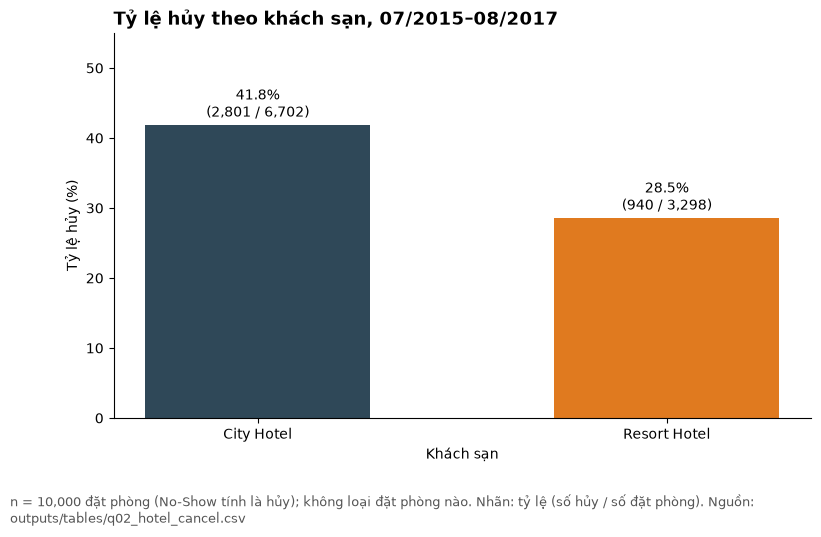

In [ ]:
# Hàm dùng chung cho mọi câu về hủy phòng
def cancel_table(frame, by):
    """Theo nhóm `by`: số đặt phòng, số hủy, tỷ lệ hủy.
    Mẫu số tỷ lệ hủy = số đặt phòng có is_canceled không thiếu."""
    t = frame.groupby(by, observed=True).agg(n_bookings=('booking_id', 'size'),
                                              n_known=('is_canceled', 'count'),
                                              n_canceled=('is_canceled', 'sum')).reset_index()
    t['cancel_rate_pct'] = (t['n_canceled'] / t['n_known'] * 100).round(2)
    return t

# Câu 2 · Số đặt phòng và tỷ lệ hủy theo khách sạn
q02 = cancel_table(clean_df, 'hotel')
q02['share_pct'] = (q02['n_bookings'] / q02['n_bookings'].sum() * 100).round(2)
q02 = q02[['hotel', 'n_bookings', 'share_pct', 'n_canceled', 'cancel_rate_pct']]
save_table(q02, 'q02_hotel_cancel')
gap = q02['cancel_rate_pct'].iloc[0] - q02['cancel_rate_pct'].iloc[1]
print(f'City − Resort: {gap:.2f} điểm phần trăm')
display(q02)

fig, ax = plt.subplots(figsize=FIGSIZE)
bars = ax.bar(q02['hotel'], q02['cancel_rate_pct'], color=[HOTEL_COLORS[h] for h in q02['hotel']], width=0.55)
ax.bar_label(bars, labels=[f'{r:.1f}%\n({c:,} / {n:,})' for r, c, n in
                           zip(q02['cancel_rate_pct'], q02['n_canceled'], q02['n_bookings'])], padding=3)
ax.set_ylim(0, 55)
finish_chart(ax, 'Tỷ lệ hủy theo khách sạn, 07/2015–08/2017', 'Khách sạn', 'Tỷ lệ hủy (%)',
             note=f"n = {q02['n_bookings'].sum():,} đặt phòng (No-Show tính là hủy); không loại đặt phòng nào. "
                  'Nhãn: tỷ lệ (số hủy / số đặt phòng). Nguồn: outputs/tables/q02_hotel_cancel.csv')
save_fig(fig, 'fig01_hotel_cancel')
plt.show()

In [ ]:
check('q02_hotel_cancel đã được tạo', lambda: q02 is not None and len(q02) > 0)
check('q02 có đúng 2 khách sạn', lambda: len(q02) == 2)
check('Đã lưu fig01_hotel_cancel.png', lambda: (OUTPUT_DIR / 'figures' / 'fig01_hotel_cancel.png').exists())

✅ q02_hotel_cancel đã được tạo
✅ q02 có đúng 2 khách sạn
✅ Đã lưu fig01_hotel_cancel.png


True

> **✍️ Nhận xét Câu 2**
>
> 1. **Phát hiện chính:** City Hotel chiếm 67,02% số đặt phòng và có tỷ lệ hủy cao hơn Resort Hotel.
> 2. **Số liệu và mẫu số:** City Hotel 2.801 hủy / 6.702 đặt phòng = **41,79%**; Resort Hotel 940 / 3.298 = **28,50%** (mẫu số: mọi đặt phòng có `is_canceled`, không loại đặt phòng nào; No-Show tính là hủy).
> 3. **So sánh:** chênh **13,29 điểm phần trăm**, tức tỷ lệ của City gấp khoảng 1,47 lần Resort.
> 4. **Giới hạn:** hai khách sạn khác loại hình (thành phố/nghỉ dưỡng), vị trí và cơ cấu kênh bán; chênh lệch không cho biết nguyên nhân hủy.
>
> *Nguồn: `outputs/tables/q02_hotel_cancel.csv` · `outputs/figures/fig01_hotel_cancel.png`*

## Câu 3 · Mùa vụ: số đặt phòng theo tháng đến năm 2016

| | |
|---|---|
| **Cần tính** | Chỉ năm **2016** (năm duy nhất đủ 12 tháng trong dữ liệu): số đặt phòng theo tháng × khách sạn; tỷ lệ hủy theo tháng. Nêu tháng cao nhất, thấp nhất của mỗi khách sạn. |
| **Mẫu số và trình bày** | Biểu đồ 2: hai đường theo tháng 1–12. Có thể dùng `monthly_summary`. Không so sánh trực tiếp với 2015, 2017 (thiếu tháng). |
| **Đầu ra** | `clean_df` → `q03_monthly_arrivals_2016` + `fig02_monthly_arrivals_2016.png` |

**Gợi ý:** Cột gợi ý: `arrival_month, City Hotel, Resort Hotel, total, cancel_rate_pct`.

💾 outputs/tables/q03_monthly_arrivals_2016.csv  (12 dòng)
City Hotel: cao nhất tháng 10 (360), thấp nhất tháng 1 (117)
Resort Hotel: cao nhất tháng 5 (162), thấp nhất tháng 1 (62)
Tỷ lệ hủy cả năm 2016 = 36.52% (KHÔNG phải trung bình 12 tháng = 35.63%)


,arrival_month,City Hotel,Resort Hotel,total,cancel_rate_pct,cancel_rate_city,cancel_rate_resort
0,1,117,62,179,22.35,29.06,9.68
1,2,206,139,345,33.04,33.01,33.09
2,3,267,140,407,33.42,38.58,23.57
3,4,288,160,448,37.28,42.01,28.75
4,5,291,162,453,39.29,45.7,27.78
5,6,321,124,445,37.3,41.74,25.81
6,7,248,123,371,30.19,29.44,31.71
7,8,285,143,428,36.68,34.39,41.26
8,9,337,126,463,40.17,44.21,29.37
9,10,360,157,517,40.62,45.83,28.66


🖼️  outputs/figures/fig02_monthly_arrivals_2016.png


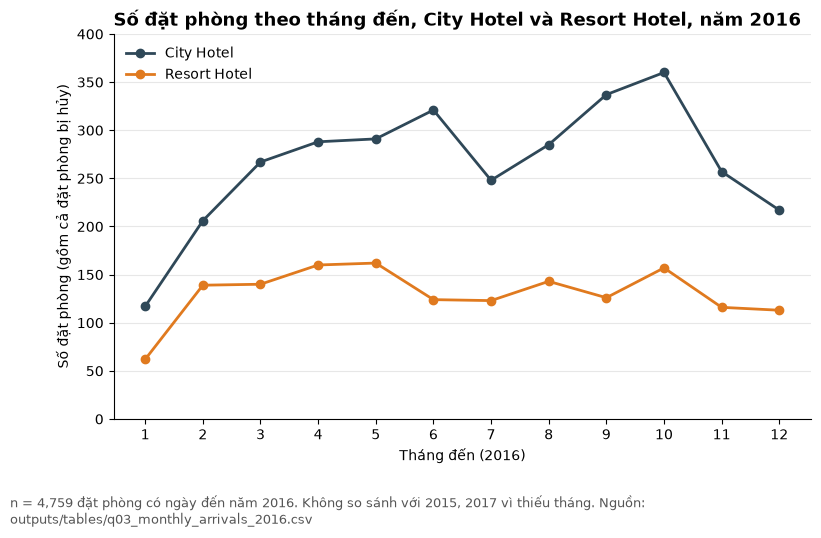

In [ ]:
# Câu 3 · Mùa vụ năm 2016
y2016 = clean_df[clean_df['arrival_year'] == 2016]

by_month_hotel = cancel_table(y2016, ['arrival_month', 'hotel'])
q03 = by_month_hotel.pivot(index='arrival_month', columns='hotel', values='n_bookings')
q03['total'] = q03['City Hotel'] + q03['Resort Hotel']
q03['cancel_rate_pct'] = cancel_table(y2016, 'arrival_month').set_index('arrival_month')['cancel_rate_pct']
rates = by_month_hotel.pivot(index='arrival_month', columns='hotel', values='cancel_rate_pct')
q03['cancel_rate_city'] = rates['City Hotel']
q03['cancel_rate_resort'] = rates['Resort Hotel']
q03 = q03.reset_index()
q03.columns.name = None
save_table(q03, 'q03_monthly_arrivals_2016')

for h in HOTELS:
    print(f"{h}: cao nhất tháng {q03.loc[q03[h].idxmax(), 'arrival_month']} ({q03[h].max()}), "
          f"thấp nhất tháng {q03.loc[q03[h].idxmin(), 'arrival_month']} ({q03[h].min()})")
print(f"Tỷ lệ hủy cả năm 2016 = {y2016['is_canceled'].mean() * 100:.2f}% "
      f"(KHÔNG phải trung bình 12 tháng = {q03['cancel_rate_pct'].mean():.2f}%)")
display(q03)

fig, ax = plt.subplots(figsize=FIGSIZE)
for h in HOTELS:
    ax.plot(q03['arrival_month'], q03[h], marker='o', color=HOTEL_COLORS[h], label=h, linewidth=2)
ax.set_xticks(range(1, 13))
ax.set_ylim(0, 400)
ax.legend(frameon=False)
ax.grid(axis='y', alpha=0.3)
finish_chart(ax, 'Số đặt phòng theo tháng đến, City Hotel và Resort Hotel, năm 2016', 'Tháng đến (2016)',
             'Số đặt phòng (gồm cả đặt phòng bị hủy)',
             note=f"n = {len(y2016):,} đặt phòng có ngày đến năm 2016. Không so sánh với 2015, 2017 vì thiếu tháng. "
                  'Nguồn: outputs/tables/q03_monthly_arrivals_2016.csv')
save_fig(fig, 'fig02_monthly_arrivals_2016')
plt.show()

In [ ]:
check('q03_monthly_arrivals_2016 đã được tạo', lambda: q03 is not None and len(q03) > 0)
check('q03 có đủ 12 tháng', lambda: len(q03) == 12)
check('Đã lưu fig02_monthly_arrivals_2016.png', lambda: (OUTPUT_DIR / 'figures' / 'fig02_monthly_arrivals_2016.png').exists())

✅ q03_monthly_arrivals_2016 đã được tạo
✅ q03 có đủ 12 tháng
✅ Đã lưu fig02_monthly_arrivals_2016.png


True

> **✍️ Nhận xét Câu 3**
>
> 1. **Phát hiện chính:** năm 2016, City Hotel có số đặt phòng cao nhất vào **tháng 10 (360)** và thấp nhất tháng 1 (117); Resort Hotel cao nhất **tháng 5 (162)**, thấp nhất tháng 1 (62). Đường Resort phẳng hơn, City có hai đỉnh (tháng 6 và tháng 9–10).
> 2. **Số liệu và mẫu số:** 4.759 đặt phòng có `arrival_date` năm 2016 (City 3.194, Resort 1.565); 49 đặt phòng thiếu ngày đến bị loại khỏi phân tích theo tháng.
> 3. **So sánh:** tỷ lệ hủy cả năm 2016 = 36,52% (cộng tử số và mẫu số), khác trung bình cộng 12 tỷ lệ tháng (35,63%). Tháng 1 có tỷ lệ hủy thấp nhất (22,35%), tháng 10 cao nhất (40,62%).
> 4. **Giới hạn:** số đặt phòng gồm cả đặt phòng bị hủy, không phải số khách thực ở; mẫu là một phần bộ gốc nên số tuyệt đối nhỏ; không so sánh tổng năm với 2015, 2017 vì thiếu tháng.
>
> *Nguồn: `outputs/tables/q03_monthly_arrivals_2016.csv` · `outputs/figures/fig02_monthly_arrivals_2016.png`*

## Câu 4 · Thời gian đặt trước (lead time) và hủy phòng

| | |
|---|---|
| **Cần tính** | Thống kê `lead_time` theo khách sạn (số mẫu, trung bình, trung vị, Q1, Q3, max) và **tỷ lệ hủy theo `lead_time_group`**. |
| **Mẫu số và trình bày** | Biểu đồ 3: cột tỷ lệ hủy theo 5 nhóm, **đúng thứ tự** `0-7 → 181+`. Đây là mối liên hệ quan sát, không phải nhân quả. |
| **Đầu ra** | `clean_df` → `q04_leadtime_stats`, `q04_leadtime_cancel` + `fig03_leadtime_cancel.png` |

**Gợi ý:** Lưu **cả 2 bảng**.

Thiếu lead_time: 31 đặt phòng


,hotel,n,mean,min,q1,median,q3,max
0,City Hotel,6683,110.8,0.0,24.0,74.0,164.0,629.0
1,Resort Hotel,3286,93.0,0.0,12.0,61.0,154.0,709.0
2,Cả hai khách sạn,9969,104.9,0.0,19.0,71.0,161.0,709.0


💾 outputs/tables/q04_leadtime_stats.csv  (3 dòng)
💾 outputs/tables/q04_leadtime_cancel.csv  (5 dòng)


,lead_time_group,n_bookings,n_known,n_canceled,cancel_rate_pct,cancel_rate_city,cancel_rate_resort
0,0-7,1581,1581,159,10.06,12.54,6.76
1,8-30,1537,1537,425,27.65,30.46,22.31
2,31-90,2542,2542,946,37.21,38.94,32.92
3,91-180,2244,2244,1001,44.61,47.54,38.42
4,181+,2065,2065,1199,58.06,65.44,41.15


🖼️  outputs/figures/fig03_leadtime_cancel.png


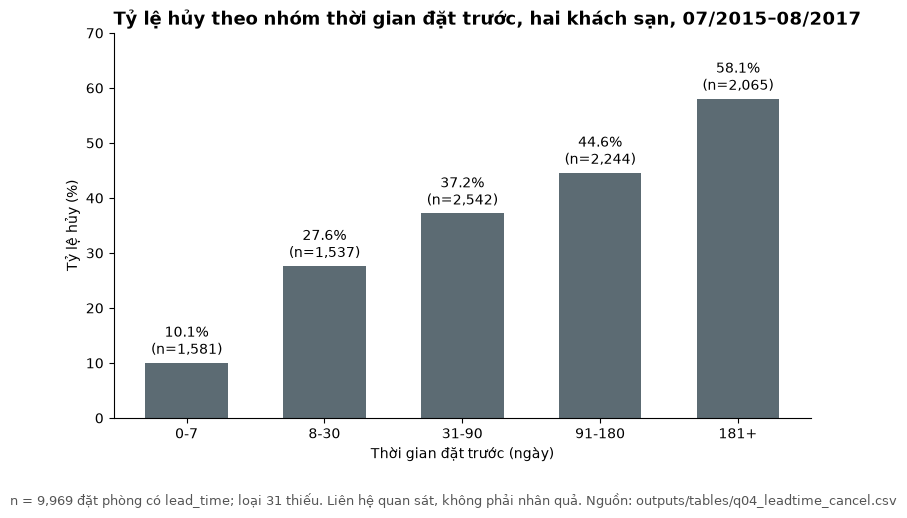

In [ ]:
# Câu 4 · Lead time và hủy phòng
STAT_NAMES = {'count': 'n', '25%': 'q1', '50%': 'median', '75%': 'q3'}

# Thống kê lead_time: describe() tính sẵn n, mean, min, Q1, median, Q3, max
stats = clean_df.groupby('hotel')['lead_time'].describe()
stats.loc['Cả hai khách sạn'] = clean_df['lead_time'].describe()
q04 = stats.rename(columns=STAT_NAMES).drop(columns='std').round(1).astype({'n': int}).reset_index()
print('Thiếu lead_time:', clean_df['lead_time'].isna().sum(), 'đặt phòng')
display(q04)

# Tỷ lệ hủy theo 5 nhóm lead time (thứ tự 0-7 -> 181+ có sẵn trong pd.cut)
q04_b = cancel_table(clean_df, 'lead_time_group')
rates = cancel_table(clean_df, ['lead_time_group', 'hotel']).pivot(index='lead_time_group', columns='hotel', values='cancel_rate_pct')
q04_b['cancel_rate_city'] = rates['City Hotel'].values
q04_b['cancel_rate_resort'] = rates['Resort Hotel'].values
save_table(q04, 'q04_leadtime_stats')
save_table(q04_b, 'q04_leadtime_cancel')
display(q04_b)

fig, ax = plt.subplots(figsize=FIGSIZE)
bars = ax.bar(q04_b['lead_time_group'].astype(str), q04_b['cancel_rate_pct'], color='#5C6B73', width=0.6)
ax.bar_label(bars, labels=[f'{r:.1f}%\n(n={n:,})' for r, n in zip(q04_b['cancel_rate_pct'], q04_b['n_bookings'])], padding=3)
ax.set_ylim(0, 70)
finish_chart(ax, 'Tỷ lệ hủy theo nhóm thời gian đặt trước, hai khách sạn, 07/2015–08/2017',
             'Thời gian đặt trước (ngày)', 'Tỷ lệ hủy (%)',
             note=f"n = {q04_b['n_bookings'].sum():,} đặt phòng có lead_time; loại {clean_df['lead_time'].isna().sum()} thiếu. "
                  'Liên hệ quan sát, không phải nhân quả. Nguồn: outputs/tables/q04_leadtime_cancel.csv')
save_fig(fig, 'fig03_leadtime_cancel')
plt.show()

In [ ]:
check('q04_leadtime_stats đã được tạo', lambda: q04 is not None and len(q04) > 0)
check('q04_leadtime_cancel đã được tạo', lambda: q04_b is not None and len(q04_b) > 0)
check('q04_leadtime_cancel có 5 nhóm', lambda: len(q04_b) == 5)
check('Đã lưu fig03_leadtime_cancel.png', lambda: (OUTPUT_DIR / 'figures' / 'fig03_leadtime_cancel.png').exists())

✅ q04_leadtime_stats đã được tạo
✅ q04_leadtime_cancel đã được tạo
✅ q04_leadtime_cancel có 5 nhóm
✅ Đã lưu fig03_leadtime_cancel.png


True

> **✍️ Nhận xét Câu 4**
>
> 1. **Phát hiện chính:** tỷ lệ hủy tăng dần theo thời gian đặt trước, từ **10,06%** ở nhóm 0–7 ngày (n = 1.581) lên **58,06%** ở nhóm 181+ ngày (n = 2.065).
> 2. **Số liệu và mẫu số:** 9.969 đặt phòng có `lead_time` hợp lệ (loại 31 thiếu). Trung vị lead time City 74 ngày (Q1–Q3: 24–164), Resort 61 ngày (12–154); trung bình lớn hơn trung vị (110,8 và 93,0) do đuôi phải dài (max 629 và 709 ngày).
> 3. **So sánh:** chênh 48 điểm phần trăm giữa hai nhóm đầu–cuối; xu hướng xuất hiện ở cả hai khách sạn (City 12,54% → 65,44%; Resort 6,76% → 41,15%).
> 4. **Giới hạn:** đây là mối liên hệ quan sát, không chứng minh đặt sớm làm khách hủy; nhóm đặt sớm có thể khác về phân khúc và chính sách cọc (xem Câu 6, 7).
>
> *Nguồn: `outputs/tables/q04_leadtime_stats.csv`, `q04_leadtime_cancel.csv` · `outputs/figures/fig03_leadtime_cancel.png`*

## Câu 5 · Top 10 quốc gia của khách

| | |
|---|---|
| **Cần tính** | Đếm đặt phòng theo `country`; Top 10; tỷ lệ trên **tổng số đặt phòng**; tỷ lệ hủy mỗi nước. Báo cáo riêng số đặt phòng thiếu quốc gia. Đồng hạng → sắp tiếp theo mã. |
| **Mẫu số và trình bày** | Biểu đồ 4: cột ngang, sắp theo số lượng. |
| **Đầu ra** | `clean_df` → `q05_top10_country` + `fig04_top10_country.png` |

**Gợi ý:** Cột gợi ý: `rank, country, n_bookings, pct_of_all_bookings, cancel_rate_pct`.

💾 outputs/tables/q05_top10_country.csv  (10 dòng)
Mẫu số: 10,000 đặt phòng, trong đó 107 thiếu quốc gia. CN: 99 · CHN: 85


,rank,country,n_bookings,pct_of_all_bookings,cancel_rate_pct
78,1,PRT,4005,40.05,57.68
34,2,GBR,999,9.99,19.72
31,3,FRA,876,8.76,19.06
28,4,ESP,700,7.00,24.57
23,5,DEU,650,6.50,18.62
49,6,ITA,294,2.94,33.67
44,7,IRL,281,2.81,23.84
5,8,BEL,201,2.01,18.41
99,9,USA,198,1.98,24.75
9,10,BRA,192,1.92,41.15


🖼️  outputs/figures/fig04_top10_country.png


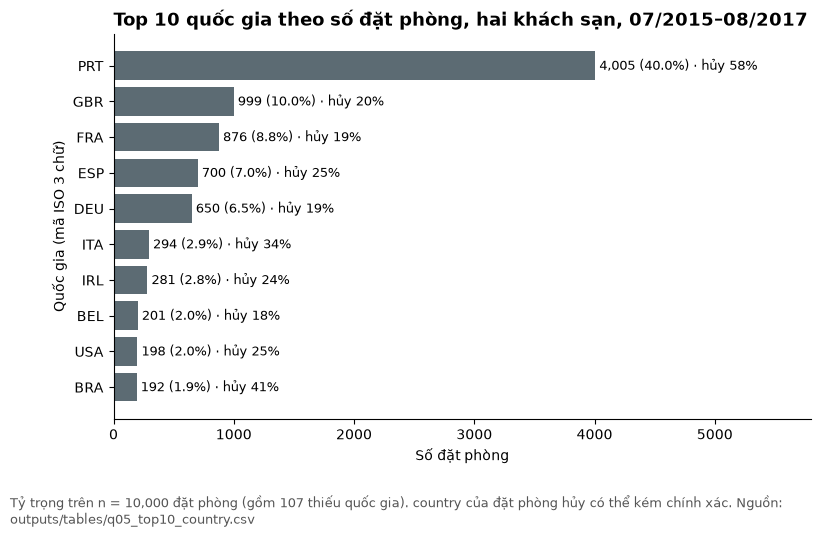

In [ ]:
# Câu 5 · Top 10 quốc gia
n_all = len(clean_df)
n_no_country = clean_df['country'].isna().sum()

q05 = cancel_table(clean_df, 'country')                       # groupby tự bỏ ô thiếu country
q05 = q05.sort_values(['n_bookings', 'country'], ascending=[False, True]).head(10).copy()   # đồng hạng -> theo mã
q05.insert(0, 'rank', range(1, 11))
q05['pct_of_all_bookings'] = (q05['n_bookings'] / n_all * 100).round(2)              # mẫu số gồm cả thiếu quốc gia
q05 = q05[['rank', 'country', 'n_bookings', 'pct_of_all_bookings', 'cancel_rate_pct']]
save_table(q05, 'q05_top10_country')
print(f'Mẫu số: {n_all:,} đặt phòng, trong đó {n_no_country} thiếu quốc gia. '
      f"CN: {(clean_df['country'] == 'CN').sum()} · CHN: {(clean_df['country'] == 'CHN').sum()}")
display(q05)

fig, ax = plt.subplots(figsize=FIGSIZE)
top = q05.iloc[::-1]                                              # đảo để nước lớn nhất nằm trên cùng
bars = ax.barh(top['country'], top['n_bookings'], color='#5C6B73')
ax.bar_label(bars, labels=[f'{n:,} ({p:.1f}%) · hủy {c:.0f}%' for n, p, c in
                           zip(top['n_bookings'], top['pct_of_all_bookings'], top['cancel_rate_pct'])], padding=3, fontsize=9)
ax.set_xlim(0, 5800)
finish_chart(ax, 'Top 10 quốc gia theo số đặt phòng, hai khách sạn, 07/2015–08/2017', 'Số đặt phòng', 'Quốc gia (mã ISO 3 chữ)',
             note=f'Tỷ trọng trên n = {n_all:,} đặt phòng (gồm {n_no_country} thiếu quốc gia). country của đặt phòng hủy '
                  'có thể kém chính xác. Nguồn: outputs/tables/q05_top10_country.csv')
save_fig(fig, 'fig04_top10_country')
plt.show()

In [ ]:
check('q05_top10_country đã được tạo', lambda: q05 is not None and len(q05) > 0)
check('q05 có 10 quốc gia', lambda: len(q05) == 10)
check('Đã lưu fig04_top10_country.png', lambda: (OUTPUT_DIR / 'figures' / 'fig04_top10_country.png').exists())

✅ q05_top10_country đã được tạo
✅ q05 có 10 quốc gia
✅ Đã lưu fig04_top10_country.png


True

> **✍️ Nhận xét Câu 5**
>
> 1. **Phát hiện chính:** Bồ Đào Nha (PRT) chiếm **40,05%** số đặt phòng (4.005 / 10.000) và có tỷ lệ hủy **57,68%**, cao nhất trong Top 10.
> 2. **Số liệu và mẫu số:** tỷ trọng tính trên 10.000 đặt phòng, gồm 107 đặt phòng thiếu quốc gia (1,07%, báo riêng). Top 10 chiếm 83,96% tổng số; sau PRT là GBR (9,99%), FRA (8,76%), ESP (7,00%), DEU (6,50%).
> 3. **So sánh:** tỷ lệ hủy của PRT cao hơn GBR (19,72%) khoảng 38 điểm phần trăm và gấp khoảng 2,4 lần nhóm khách ngoài PRT (23,88% trên 5.888 đặt phòng).
> 4. **Giới hạn:** theo tác giả nguồn, `country` thường chỉ được xác nhận khi nhận phòng nên với đặt phòng bị hủy có thể kém chính xác - tỷ lệ hủy theo quốc gia cần đọc thận trọng. `CN` (99) và `CHN` (85) được giữ riêng, cả hai ngoài Top 10.
>
> *Nguồn: `outputs/tables/q05_top10_country.csv` · `outputs/figures/fig04_top10_country.png`*

## Câu 6 · Phân khúc thị trường

| | |
|---|---|
| **Cần tính** | Theo `market_segment`: số đặt phòng, tỷ trọng, tỷ lệ hủy; báo cáo riêng số thiếu phân khúc. |
| **Mẫu số và trình bày** | Biểu đồ 5: cột ngang (số đặt phòng hoặc tỷ lệ hủy), sắp theo giá trị. Nêu phân khúc nhỏ (ví dụ Aviation) có mẫu ít → tỷ lệ kém ổn định. |
| **Đầu ra** | `clean_df` → `q06_segment_cancel` + `fig05_segment_cancel.png` |

**Gợi ý:** Thêm cột `n_bookings` cạnh tỷ lệ để người đọc thấy cỡ mẫu.

💾 outputs/tables/q06_segment_cancel.csv  (7 dòng)
Thiếu phân khúc: 3


,market_segment,n_bookings,share_pct,n_canceled,cancel_rate_pct,small_sample
6,Online TA,4741,47.42,1753,36.98,False
5,Offline TA/TO,2012,20.13,683,33.95,False
4,Groups,1703,17.04,1054,61.89,False
3,Direct,1018,10.18,153,15.03,False
2,Corporate,441,4.41,81,18.37,False
1,Complementary,61,0.61,10,16.39,True
0,Aviation,21,0.21,5,23.81,True


🖼️  outputs/figures/fig05_segment_cancel.png


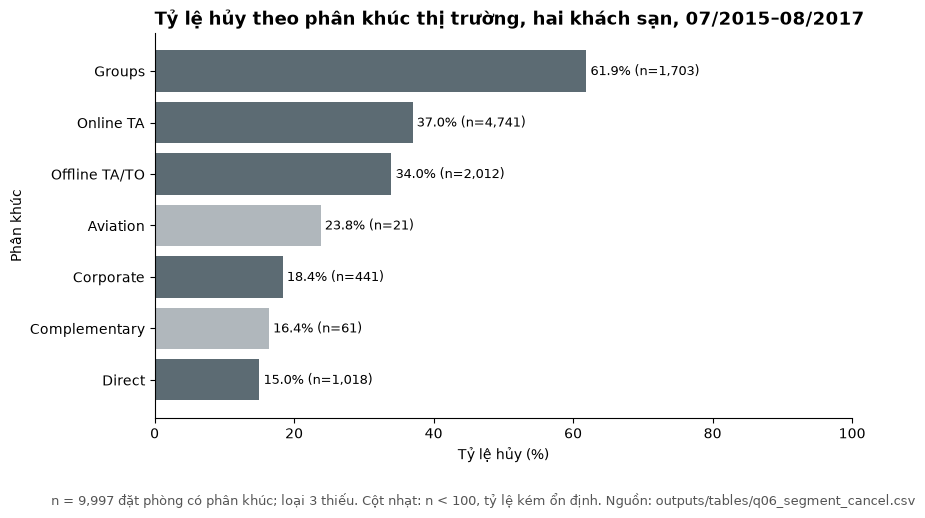

In [ ]:
# Câu 6 · Phân khúc thị trường
n_no_segment = clean_df['market_segment'].isna().sum()
q06 = cancel_table(clean_df, 'market_segment').sort_values('n_bookings', ascending=False)
q06['share_pct'] = (q06['n_bookings'] / q06['n_bookings'].sum() * 100).round(2)   # mẫu số: đặt phòng có phân khúc
q06['small_sample'] = q06['n_bookings'] < 100
q06 = q06[['market_segment', 'n_bookings', 'share_pct', 'n_canceled', 'cancel_rate_pct', 'small_sample']]
save_table(q06, 'q06_segment_cancel')
print('Thiếu phân khúc:', n_no_segment)
display(q06)

fig, ax = plt.subplots(figsize=FIGSIZE)
plot = q06.sort_values('cancel_rate_pct')
bars = ax.barh(plot['market_segment'], plot['cancel_rate_pct'],
               color=['#B0B7BC' if small else '#5C6B73' for small in plot['small_sample']])
ax.bar_label(bars, labels=[f'{r:.1f}% (n={n:,})' for r, n in zip(plot['cancel_rate_pct'], plot['n_bookings'])], padding=3, fontsize=9)
ax.set_xlim(0, 100)
finish_chart(ax, 'Tỷ lệ hủy theo phân khúc thị trường, hai khách sạn, 07/2015–08/2017', 'Tỷ lệ hủy (%)', 'Phân khúc',
             note=f"n = {q06['n_bookings'].sum():,} đặt phòng có phân khúc; loại {n_no_segment} thiếu. "
                  'Cột nhạt: n < 100, tỷ lệ kém ổn định. Nguồn: outputs/tables/q06_segment_cancel.csv')
save_fig(fig, 'fig05_segment_cancel')
plt.show()

In [ ]:
check('q06_segment_cancel đã được tạo', lambda: q06 is not None and len(q06) > 0)
check('Đã lưu fig05_segment_cancel.png', lambda: (OUTPUT_DIR / 'figures' / 'fig05_segment_cancel.png').exists())

✅ q06_segment_cancel đã được tạo
✅ Đã lưu fig05_segment_cancel.png


True

> **✍️ Nhận xét Câu 6**
>
> 1. **Phát hiện chính:** Online TA là phân khúc lớn nhất (**47,42%**, 4.741 đặt phòng); Groups có tỷ lệ hủy cao nhất (**61,89%**, 1.054 / 1.703).
> 2. **Số liệu và mẫu số:** 9.997 đặt phòng có phân khúc (3 thiếu do `Undefined`, báo riêng). Direct có tỷ lệ hủy thấp nhất trong các phân khúc lớn (15,03%, n = 1.018).
> 3. **So sánh:** Groups cao hơn Online TA (36,98%) 24,9 điểm phần trăm và gấp hơn 4 lần Direct.
> 4. **Giới hạn:** Aviation (n = 21) và Complementary (n = 61) có cỡ mẫu nhỏ, tỷ lệ kém ổn định (cột nhạt trên hình). Phân khúc trùng lặp với khách sạn và loại cọc (ví dụ phần lớn đặt phòng Non Refund thuộc Groups), nên không tách được tác động riêng của phân khúc.
>
> *Nguồn: `outputs/tables/q06_segment_cancel.csv` · `outputs/figures/fig05_segment_cancel.png`*

## Câu 7 · Loại đặt cọc và trạng thái đặt phòng

| | |
|---|---|
| **Cần tính** | Bảng chéo `deposit_type × reservation_status`; tỷ lệ **trong từng loại đặt cọc** (Check-Out, Canceled, No-Show, và `Unknown` nếu trạng thái thiếu). |
| **Mẫu số và trình bày** | Biểu đồ 6: cột chồng 100%. So sánh tỷ lệ hủy giữa các loại theo điểm phần trăm và nêu cỡ mẫu (Refundable rất ít). |
| **Đầu ra** | `clean_df` → `q07_deposit_cancel` + `fig06_deposit_cancel.png` |

**Gợi ý:** `pd.crosstab(..., normalize='index')`; điền `'Unknown'` **chỉ khi trình bày**.

💾 outputs/tables/q07_deposit_cancel.csv  (3 dòng)


reservation_status,deposit_type,n_bookings,n_Check-Out,n_Canceled,n_No-Show,n_Unknown,pct_Check-Out,pct_Canceled,pct_No-Show,pct_Unknown,cancel_rate_pct
0,No Deposit,8728,6224,2377,105,22,71.31,27.23,1.2,0.25,28.52
1,Non Refund,1259,12,1244,0,3,0.95,98.81,0.0,0.24,99.05
2,Refundable,13,8,5,0,0,61.54,38.46,0.0,0.00,38.46


🖼️  outputs/figures/fig06_deposit_cancel.png


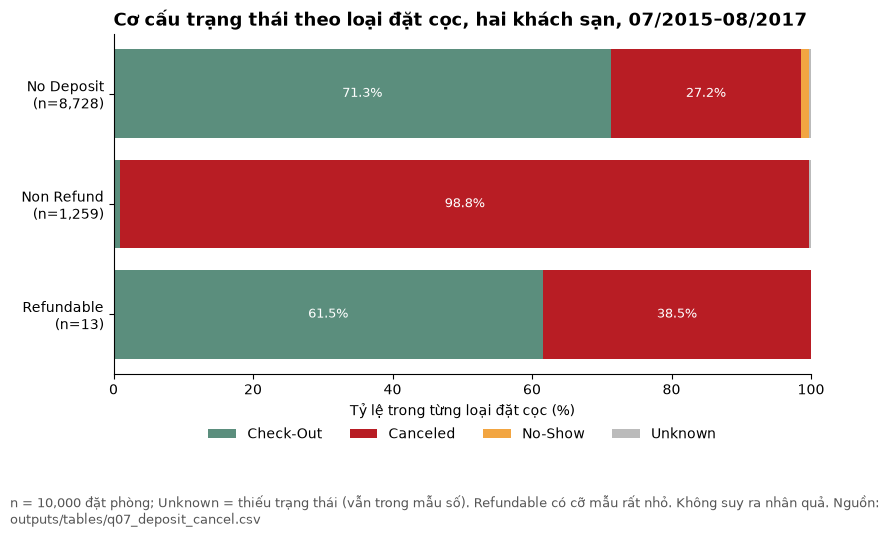

In [ ]:
# Câu 7 · Loại đặt cọc × trạng thái
STATUS_ORDER = STATUSES + ['Unknown']
status = clean_df['reservation_status'].fillna('Unknown')    # 'Unknown' chỉ để trình bày, vẫn nằm trong mẫu số

counts = pd.crosstab(clean_df['deposit_type'], status).reindex(index=DEPOSITS, columns=STATUS_ORDER, fill_value=0)
pct = (counts.div(counts.sum(axis=1), axis=0) * 100).round(2)          # tỷ lệ trong từng loại đặt cọc

q07 = pd.concat([counts.add_prefix('n_'), pct.add_prefix('pct_')], axis=1)
q07.insert(0, 'n_bookings', counts.sum(axis=1))
q07['cancel_rate_pct'] = cancel_table(clean_df, 'deposit_type').set_index('deposit_type')['cancel_rate_pct']
q07 = q07.reset_index()
save_table(q07, 'q07_deposit_cancel')
display(q07)

fig, ax = plt.subplots(figsize=FIGSIZE)
colors = {**STATUS_COLORS, 'Unknown': '#BBBBBB'}
labels = [f'{d}\n(n={n:,})' for d, n in zip(pct.index, counts.sum(axis=1))]
left = 0
for st in STATUS_ORDER:                                               # vẽ cột chồng 100%
    bars = ax.barh(labels, pct[st], left=left, color=colors[st], label=st)
    ax.bar_label(bars, labels=[f'{v:.1f}%' if v >= 4 else '' for v in pct[st]], label_type='center', color='white', fontsize=9)
    left = left + pct[st].values
ax.set_xlim(0, 100)
ax.invert_yaxis()
ax.legend(ncol=4, frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.12))
fig.subplots_adjust(bottom=0.2)
finish_chart(ax, 'Cơ cấu trạng thái theo loại đặt cọc, hai khách sạn, 07/2015–08/2017', 'Tỷ lệ trong từng loại đặt cọc (%)', '',
             note=f"n = {counts.values.sum():,} đặt phòng; Unknown = thiếu trạng thái (vẫn trong mẫu số). Refundable có cỡ mẫu rất nhỏ. "
                  'Không suy ra nhân quả. Nguồn: outputs/tables/q07_deposit_cancel.csv')
save_fig(fig, 'fig06_deposit_cancel')
plt.show()

In [ ]:
check('q07_deposit_cancel đã được tạo', lambda: q07 is not None and len(q07) > 0)
check('Đã lưu fig06_deposit_cancel.png', lambda: (OUTPUT_DIR / 'figures' / 'fig06_deposit_cancel.png').exists())

✅ q07_deposit_cancel đã được tạo
✅ Đã lưu fig06_deposit_cancel.png


True

> **✍️ Nhận xét Câu 7**
>
> 1. **Phát hiện chính:** nhóm **Non Refund** có 98,81% đặt phòng ở trạng thái Canceled (1.244 / 1.259), trong khi No Deposit có 71,31% Check-Out.
> 2. **Số liệu và mẫu số:** mẫu số là tổng đặt phòng của từng loại cọc (trạng thái thiếu hiển thị là Unknown nhưng vẫn trong mẫu số: 22 ở No Deposit, 3 ở Non Refund). Tỷ lệ hủy (gồm No-Show): No Deposit 28,52%, Non Refund 99,05%, Refundable 38,46%.
> 3. **So sánh:** Non Refund cao hơn No Deposit khoảng 70,5 điểm phần trăm. No-Show chỉ xuất hiện ở No Deposit (1,20%).
> 4. **Giới hạn:** **không** kết luận đặt cọc làm khách hủy - nhóm Non Refund tập trung ở City Hotel (1.106 / 1.259) và phân khúc Groups/Offline TA/TO, lead time trung vị 186 ngày; kết quả có thể phản ánh cách ghi nhận hoặc đặc điểm nhóm khách. Refundable chỉ có 13 đặt phòng, không đủ để so sánh.
>
> *Nguồn: `outputs/tables/q07_deposit_cancel.csv` · `outputs/figures/fig06_deposit_cancel.png`*

## Câu 8 · Giá phòng bình quân/đêm (ADR)

| | |
|---|---|
| **Cần tính** | Chỉ đặt phòng **không hủy** có `adr` hợp lệ **và > 0**: theo khách sạn - số mẫu, trung bình, trung vị, min, max, Q1, Q3. Báo cáo riêng số `adr = 0` và số thiếu. |
| **Mẫu số và trình bày** | Biểu đồ 7: histogram độ rộng khoảng 20 EUR, tách hai khách sạn (2 panel hoặc chồng trong suốt). Không xóa giá cao trong miền. |
| **Đầu ra** | `clean_df` → `q08_adr_stats_by_hotel` + `fig07_adr_hist.png` |

**Gợi ý:** `groupby('hotel')['adr'].describe()`.

💾 outputs/tables/q08_adr_stats_by_hotel.csv  (2 dòng)


,hotel,n,mean,min,q1,median,q3,max,n_adr_zero,n_adr_missing
0,City Hotel,3828,108.18,4.5,80.75,100.65,126.9,336.00,63,10
1,Resort Hotel,2293,93.60,6.0,51.50,75.00,120.0,349.67,57,8


🖼️  outputs/figures/fig07_adr_hist.png


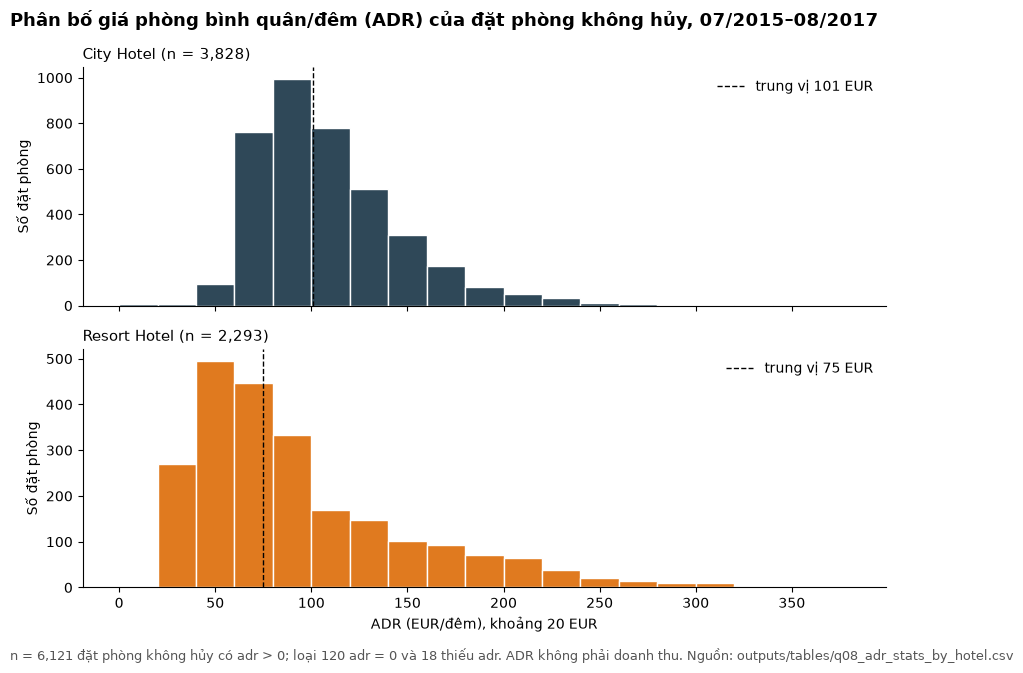

In [ ]:
# Câu 8 · ADR - chỉ đặt phòng không hủy, adr > 0
stayed = clean_df[clean_df['is_canceled'] == 0]          # đặt phòng không hủy (khách thực ở)
priced = stayed[stayed['adr'] > 0]

q08 = priced.groupby('hotel')['adr'].describe().rename(columns=STAT_NAMES).drop(columns='std').round(2).astype({'n': int})
q08['n_adr_zero'] = (stayed['adr'] == 0).groupby(stayed['hotel']).sum()       # báo cáo riêng
q08['n_adr_missing'] = stayed['adr'].isna().groupby(stayed['hotel']).sum()    # báo cáo riêng
q08 = q08.reset_index()
save_table(q08, 'q08_adr_stats_by_hotel')
display(q08)

bins = range(0, 381, 20)                                  # khoảng 20 EUR
fig, axes = plt.subplots(2, 1, figsize=(9, 6.5), sharex=True)
for ax, h in zip(axes, HOTELS):
    values = priced.loc[priced['hotel'] == h, 'adr']
    ax.hist(values, bins=bins, color=HOTEL_COLORS[h], edgecolor='white')
    ax.axvline(values.median(), color='black', linestyle='--', linewidth=1, label=f'trung vị {values.median():.0f} EUR')
    ax.set_title(f'{h} (n = {len(values):,})', loc='left', fontsize=11)
    ax.set_ylabel('Số đặt phòng')
    ax.legend(frameon=False)
    ax.spines[['top', 'right']].set_visible(False)
axes[1].set_xlabel('ADR (EUR/đêm), khoảng 20 EUR')
fig.suptitle('Phân bố giá phòng bình quân/đêm (ADR) của đặt phòng không hủy, 07/2015–08/2017',
             fontsize=13, fontweight='bold', x=0.01, ha='left')
fig.text(0.01, -0.02, f"n = {len(priced):,} đặt phòng không hủy có adr > 0; loại {q08['n_adr_zero'].sum()} adr = 0 và "
         f"{q08['n_adr_missing'].sum()} thiếu adr. ADR không phải doanh thu. Nguồn: outputs/tables/q08_adr_stats_by_hotel.csv",
         fontsize=9, color='#555555')
fig.tight_layout()
save_fig(fig, 'fig07_adr_hist')
plt.show()

In [ ]:
check('q08_adr_stats_by_hotel đã được tạo', lambda: q08 is not None and len(q08) > 0)
check('Đã lưu fig07_adr_hist.png', lambda: (OUTPUT_DIR / 'figures' / 'fig07_adr_hist.png').exists())

✅ q08_adr_stats_by_hotel đã được tạo
✅ Đã lưu fig07_adr_hist.png


True

> **✍️ Nhận xét Câu 8**
>
> 1. **Phát hiện chính:** giá phòng bình quân/đêm của City Hotel tập trung ở mức cao hơn và hẹp hơn Resort Hotel.
> 2. **Số liệu và mẫu số:** chỉ đặt phòng không hủy có `adr > 0`: City n = 3.828 - trung bình 108,18, trung vị 100,65, Q1–Q3 80,75–126,90 EUR; Resort n = 2.293 - trung bình 93,60, trung vị 75,00, Q1–Q3 51,50–120,00 EUR. Báo riêng: 120 đặt phòng `adr = 0` (City 63, Resort 57) và 18 thiếu `adr`.
> 3. **So sánh:** trung vị City cao hơn Resort 25,65 EUR; khoảng Q1–Q3 của Resort rộng 68,5 EUR so với 46,15 EUR ở City. Ở Resort, trung bình vượt trung vị 18,6 EUR - phân bố lệch phải rõ hơn (đuôi giá cao).
> 4. **Giới hạn:** ADR là giá bình quân/đêm, **không phải doanh thu**; không có thông tin loại phòng thực tế, mùa và chi tiêu ngoài tiền phòng. Giá cao trong miền (đến 349,67 EUR) được giữ.
>
> *Nguồn: `outputs/tables/q08_adr_stats_by_hotel.csv` · `outputs/figures/fig07_adr_hist.png`*

## Câu 9 · Thời gian lưu trú

| | |
|---|---|
| **Cần tính** | Đặt phòng **không hủy** có `total_nights` hợp lệ: phân bố theo số đêm (0, 1, …, 14, `15+`) và khách sạn; tỷ lệ lưu trú 1–3 đêm; số đặt phòng 0 đêm (báo cáo riêng). |
| **Mẫu số và trình bày** | Biểu đồ 8: cột theo số đêm **tăng dần**, tách khách sạn. |
| **Đầu ra** | `clean_df` → `q09_stay_nights` + `fig08_stay_nights.png` |

**Gợi ý:** Cột gợi ý: `nights_group, City Hotel, Resort Hotel, total, pct`.

💾 outputs/tables/q09_stay_nights.csv  (16 dòng)
City Hotel: 1–3 đêm = 70.29% trên 3,884; 0 đêm = 8
Resort Hotel: 1–3 đêm = 50.72% trên 2,350; 0 đêm = 29
Chung: 1–3 đêm = 62.91%; loại 25 đặt phòng không hủy thiếu số đêm


,nights_group,City Hotel,Resort Hotel,total,pct
0,0,8,29,37,0.59
1,1,788,525,1313,21.06
2,2,909,363,1272,20.40
3,3,1033,304,1337,21.45
4,4,650,249,899,14.42
5,5,252,153,405,6.50
6,6,91,100,191,3.06
7,7,107,406,513,8.23
8,8,14,40,54,0.87
9,9,10,29,39,0.63


🖼️  outputs/figures/fig08_stay_nights.png


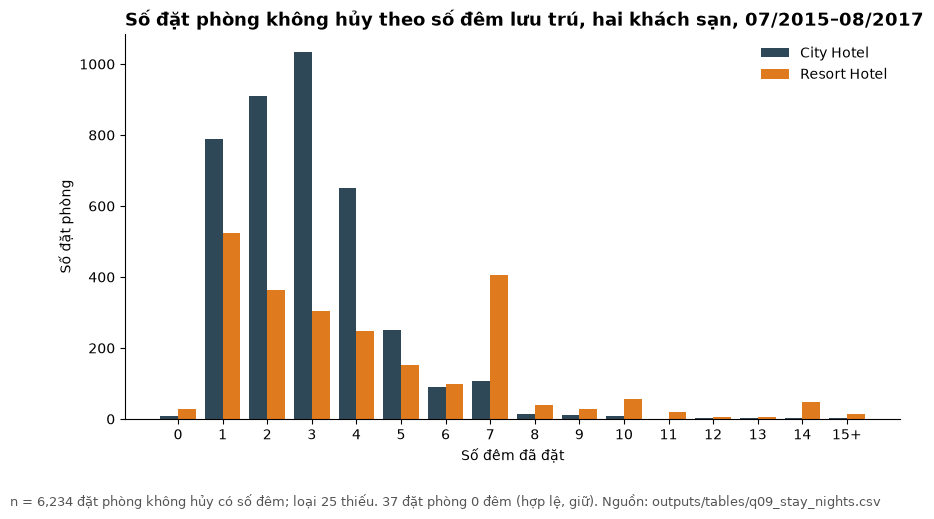

In [ ]:
# Câu 9 · Thời gian lưu trú - đặt phòng không hủy có total_nights
NIGHT_GROUPS = [str(i) for i in range(15)] + ['15+']
with_nights = stayed[stayed['total_nights'].notna()]
nights_group = with_nights['total_nights'].clip(upper=15).astype(int).astype(str).replace('15', '15+')

q09 = pd.crosstab(nights_group, with_nights['hotel']).reindex(NIGHT_GROUPS, fill_value=0)
q09['total'] = q09['City Hotel'] + q09['Resort Hotel']
q09['pct'] = (q09['total'] / q09['total'].sum() * 100).round(2)
q09 = q09.rename_axis('nights_group').reset_index()
q09.columns.name = None
save_table(q09, 'q09_stay_nights')

for h in HOTELS:
    n = with_nights.loc[with_nights['hotel'] == h, 'total_nights']
    print(f'{h}: 1–3 đêm = {n.between(1, 3).mean() * 100:.2f}% trên {len(n):,}; 0 đêm = {(n == 0).sum()}')
print(f"Chung: 1–3 đêm = {with_nights['total_nights'].between(1, 3).mean() * 100:.2f}%; "
      f"loại {stayed['total_nights'].isna().sum()} đặt phòng không hủy thiếu số đêm")
display(q09)

fig, ax = plt.subplots(figsize=(10, 5))
x = range(len(NIGHT_GROUPS))
ax.bar([i - 0.2 for i in x], q09['City Hotel'], width=0.4, color=HOTEL_COLORS['City Hotel'], label='City Hotel')
ax.bar([i + 0.2 for i in x], q09['Resort Hotel'], width=0.4, color=HOTEL_COLORS['Resort Hotel'], label='Resort Hotel')
ax.set_xticks(list(x), NIGHT_GROUPS)
ax.legend(frameon=False)
finish_chart(ax, 'Số đặt phòng không hủy theo số đêm lưu trú, hai khách sạn, 07/2015–08/2017',
             'Số đêm đã đặt', 'Số đặt phòng',
             note=f"n = {len(with_nights):,} đặt phòng không hủy có số đêm; loại {stayed['total_nights'].isna().sum()} thiếu. "
                  f"{q09.loc[0, 'total']} đặt phòng 0 đêm (hợp lệ, giữ). Nguồn: outputs/tables/q09_stay_nights.csv")
save_fig(fig, 'fig08_stay_nights')
plt.show()

In [ ]:
check('q09_stay_nights đã được tạo', lambda: q09 is not None and len(q09) > 0)
check('Đã lưu fig08_stay_nights.png', lambda: (OUTPUT_DIR / 'figures' / 'fig08_stay_nights.png').exists())

✅ q09_stay_nights đã được tạo
✅ Đã lưu fig08_stay_nights.png


True

> **✍️ Nhận xét Câu 9**
>
> 1. **Phát hiện chính:** lưu trú ngắn 1–3 đêm chiếm **62,91%** đặt phòng không hủy; Resort Hotel có thêm một đỉnh rõ ở **7 đêm**.
> 2. **Số liệu và mẫu số:** 6.234 đặt phòng không hủy có `total_nights` (loại 25 thiếu số đêm). 37 đặt phòng 0 đêm (City 8, Resort 29) - hợp lệ, được giữ và báo riêng.
> 3. **So sánh:** tỷ lệ 1–3 đêm của City là 70,29% (trên 3.884), cao hơn Resort 50,72% (trên 2.350) 19,6 điểm phần trăm. Ở Resort, 406 đặt phòng (17,3%) là đúng 7 đêm và 26,6% từ 7 đêm trở lên, so với 3,9% ở City.
> 4. **Giới hạn:** số đêm là số đêm **đã đặt**; dữ liệu không cho biết khách trả phòng sớm hay ở thêm.
>
> *Nguồn: `outputs/tables/q09_stay_nights.csv` · `outputs/figures/fig08_stay_nights.png`*

## Câu 10 · Đổi loại phòng khi nhận phòng

| | |
|---|---|
| **Cần tính** | Trong đặt phòng **Check-Out** có đủ cả hai loại phòng: tỷ lệ `room_changed_flag` theo khách sạn và theo `reserved_room_type`. |
| **Mẫu số và trình bày** | Mẫu số: số đặt phòng Check-Out có đủ hai loại phòng. Biểu đồ tùy chọn (`fig09_room_change.png`). Không suy ra lý do đổi phòng (nâng hạng hay hết phòng). |
| **Đầu ra** | `clean_df` → `q10_room_change_by_hotel`, `q10_room_change_by_reserved_type` |

**Gợi ý:** Với loại phòng có rất ít đặt phòng, nêu cỡ mẫu bên cạnh tỷ lệ.

In [ ]:
# Câu 10 · Đổi loại phòng - đặt phòng Check-Out có đủ hai loại phòng
checked_out = clean_df[(clean_df['reservation_status'] == 'Check-Out')
                       & clean_df['reserved_room_type'].notna() & clean_df['assigned_room_type'].notna()]

def room_change_table(by):
    t = checked_out.groupby(by).agg(n_bookings=('booking_id', 'size'), n_changed=('room_changed_flag', 'sum')).reset_index()
    t['changed_pct'] = (t['n_changed'] / t['n_bookings'] * 100).round(2)
    t['small_sample'] = t['n_bookings'] < 30
    return t

q10 = room_change_table('hotel')
q10_b = room_change_table('reserved_room_type')
save_table(q10, 'q10_room_change_by_hotel')
save_table(q10_b, 'q10_room_change_by_reserved_type')
print(f"Mẫu số: {len(checked_out):,} đặt phòng Check-Out có đủ hai loại phòng; "
      f"chung: {checked_out['room_changed_flag'].mean() * 100:.2f}% đổi phòng")
display(q10, q10_b)

💾 outputs/tables/q10_room_change_by_hotel.csv  (2 dòng)
💾 outputs/tables/q10_room_change_by_reserved_type.csv  (8 dòng)
Mẫu số: 6,242 đặt phòng Check-Out có đủ hai loại phòng; chung: 18.33% đổi phòng


,hotel,n_bookings,n_changed,changed_pct,small_sample
0,City Hotel,3891,561,14.42,False
1,Resort Hotel,2351,583,24.80,False


,reserved_room_type,n_bookings,n_changed,changed_pct,small_sample
0,A,4287,948,22.11,False
1,B,64,11,17.19,False
2,C,50,4,8.00,False
3,D,1137,114,10.03,False
4,E,397,47,11.84,False
5,F,174,15,8.62,False
6,G,110,3,2.73,False
7,H,23,2,8.70,True


In [ ]:
check('q10_room_change_by_hotel đã được tạo', lambda: q10 is not None and len(q10) > 0)
check('q10_room_change_by_reserved_type đã được tạo', lambda: q10_b is not None and len(q10_b) > 0)

✅ q10_room_change_by_hotel đã được tạo
✅ q10_room_change_by_reserved_type đã được tạo


True

> **✍️ Nhận xét Câu 10**
>
> 1. **Phát hiện chính:** 18,33% đặt phòng Check-Out được xếp loại phòng khác loại đã đặt (1.144 / 6.242); tỷ lệ ở Resort Hotel cao hơn City Hotel.
> 2. **Số liệu và mẫu số:** 6.242 đặt phòng Check-Out có đủ hai loại phòng (loại 2 thiếu loại phòng). City 561 / 3.891 = 14,42%; Resort 583 / 2.351 = 24,80%.
> 3. **So sánh:** Resort cao hơn City 10,38 điểm phần trăm. Theo loại phòng đặt, A có tỷ lệ đổi cao nhất (22,11%, n = 4.287), G thấp nhất (2,73%, n = 110); loại H chỉ có 23 đặt phòng nên tỷ lệ kém ổn định.
> 4. **Giới hạn:** dữ liệu không cho biết lý do đổi phòng (nâng hạng, hết phòng hay khách yêu cầu) nên không đánh giá được đổi phòng là tốt hay xấu.
>
> *Nguồn: `outputs/tables/q10_room_change_by_hotel.csv`, `q10_room_change_by_reserved_type.csv`*

---
# 6 INSIGHT CÓ BẰNG CHỨNG

| # | Chủ đề | Câu/Bảng/Hình làm bằng chứng | Phát hiện chính (1 câu) |
|---|---|---|---|
| 1 | Khách sạn | Câu 2 · `q02` · Hình 1; Câu 3 · `q03` | City Hotel có tỷ lệ hủy 41,79%, cao hơn Resort 13,29 điểm %, và cao hơn ở 9/12 tháng năm 2016. |
| 2 | Lead time | Câu 4 · `q04_leadtime_cancel` · Hình 3 | Tỷ lệ hủy tăng từ 10,06% (0–7 ngày) lên 58,06% (181+ ngày) ở cả hai khách sạn. |
| 3 | Đặt cọc | Câu 7 · `q07` · Hình 6 | 99,05% đặt phòng Non Refund bị hủy, nhưng nhóm này tập trung ở City Hotel, Groups và đặt rất sớm. |
| 4 | Quốc gia | Câu 5 · `q05` · Hình 4 | Khách PRT chiếm 40,05% đặt phòng với tỷ lệ hủy 57,68%, gấp 2,4 lần nhóm ngoài PRT. |
| 5 | Lưu trú & giá phòng | Câu 8, 9 · `q08`, `q09` · Hình 7, 8 | City là lưu trú ngắn, giá trung vị cao hơn; Resort có nhiều kỳ nghỉ 7 đêm và giá phân tán hơn. |
| 6 | Chất lượng dữ liệu | Câu 1 · `q01` · `quality_report` | 325 dòng lặp và nhiều định dạng lỗi; nếu không làm sạch, số đặt phòng City và ADR tối đa đều sai. |

### Insight 1 - City Hotel hủy nhiều hơn Resort Hotel ở hầu hết các tháng

Trong 6.702 đặt phòng của City Hotel có 2.801 bị hủy (41,79%), cao hơn Resort Hotel (28,50% trên 3.298 đặt phòng) 13,29 điểm phần trăm, tức gấp khoảng 1,47 lần. Khoảng cách không chỉ đến từ một mùa: trong năm 2016, tỷ lệ hủy của City cao hơn Resort ở 9/12 tháng; ngoại lệ là tháng 2 (gần bằng nhau), tháng 7 và tháng 8 (Resort 41,26% so với City 34,39%). Trong phạm vi hai khách sạn của mẫu, City cần được theo dõi tỷ lệ hủy sát hơn. Tuy nhiên, hai khách sạn khác loại hình, vị trí và cơ cấu kênh bán; cần dữ liệu về lý do hủy để giải thích chênh lệch. *(Nguồn: Bảng q02, q03; Hình 1, 2)*

### Insight 2 - Đặt càng sớm, tỷ lệ hủy quan sát được càng cao

Trong 9.969 đặt phòng có lead time hợp lệ (loại 31 đặt phòng thiếu), tỷ lệ hủy tăng đều qua năm nhóm: 10,06% ở nhóm 0–7 ngày (n = 1.581), 37,21% ở nhóm 31–90 ngày và 58,06% ở nhóm 181+ ngày (n = 2.065), tức chênh 48 điểm phần trăm. Xu hướng xuất hiện ở cả City Hotel (12,54% → 65,44%) và Resort Hotel (6,76% → 41,15%), nên không chỉ do khác biệt giữa hai khách sạn. Với hai khách sạn trong mẫu, lead time là một chỉ báo mô tả hữu ích khi theo dõi đặt phòng. Đây là liên hệ quan sát, không phải nhân quả: nhóm 181+ ngày có 37,7% Groups và 31,3% Non Refund. *(Nguồn: Bảng q04_leadtime_cancel; Hình 3)*

### Insight 3 - Non Refund gần như toàn bộ bị hủy, nhưng không chứng minh tác động của đặt cọc

Trong 1.259 đặt phòng Non Refund, 1.244 có trạng thái Canceled (98,81%), tỷ lệ hủy 99,05%, cao hơn No Deposit (28,52% trên 8.728 đặt phòng) khoảng 70,5 điểm phần trăm. Nhóm Non Refund tập trung ở City Hotel (1.106 đặt phòng), phân khúc Groups (813) và Offline TA/TO (410), với lead time trung vị 186 ngày so với 57 ngày của No Deposit. Vì vậy, trong mẫu này, chênh lệch có thể phản ánh cách ghi nhận hoặc đặc điểm nhóm khách; cần dữ liệu về chính sách cọc thực tế và lý do hủy để kiểm chứng. *(Nguồn: Bảng q07; Hình 6)*

### Insight 4 - Khách Bồ Đào Nha chiếm 40% đặt phòng và có tỷ lệ hủy cao bất thường

Trong 10.000 đặt phòng (gồm 107 đặt phòng thiếu quốc gia), khách PRT chiếm 4.005 đặt phòng (40,05%), gấp khoảng bốn lần GBR (9,99%), nước đứng thứ hai. Tỷ lệ hủy của PRT là 57,68%, cao hơn GBR 38 điểm phần trăm và gấp khoảng 2,4 lần nhóm khách ngoài PRT (23,88% trên 5.888 đặt phòng). Với hai khách sạn đặt tại Bồ Đào Nha, tỷ trọng khách nội địa lớn là điều dễ hiểu. Tuy nhiên, theo tác giả nguồn, quốc gia thường chỉ được xác nhận khi nhận phòng, nên đặt phòng bị hủy có thể mang mã PRT mặc định; tỷ lệ hủy theo quốc gia cần được kiểm chứng trước khi dùng. *(Nguồn: Bảng q05; Hình 4)*

### Insight 5 - Hai khách sạn khác nhau rõ về độ dài lưu trú và mức giá

Trong 6.234 đặt phòng không hủy có số đêm hợp lệ, 70,29% đặt phòng của City Hotel là 1–3 đêm, so với 50,72% ở Resort Hotel (chênh 19,6 điểm phần trăm). Resort có đỉnh riêng ở 7 đêm (406 đặt phòng, 17,3%) và 26,6% đặt phòng từ 7 đêm trở lên, so với 3,9% ở City. Về giá (chỉ đặt phòng không hủy, adr > 0), trung vị ADR City là 100,65 EUR, cao hơn Resort (75,00 EUR) 25,65 EUR, nhưng Resort phân tán hơn (Q1–Q3: 51,5–120 EUR). Trong mẫu, City giống khách sạn lưu trú ngắn, Resort giống điểm nghỉ theo tuần. ADR không phải doanh thu; không có dữ liệu về mùa giá và chi tiêu khác. *(Nguồn: Bảng q08, q09; Hình 7, 8)*

### Insight 6 - Không làm sạch thì số đặt phòng, giá phòng và tỷ lệ hủy đều lệch

Tệp có 10.325 dòng nhưng chỉ 10.000 đặt phòng sau chuẩn hóa mã: 181 dòng trùng tuyệt đối bị loại và 144 dòng được gộp, trong đó 15 đặt phòng có giá trị mâu thuẫn. Nếu đếm thô nhãn 'City Hotel', kết quả là 6.763 thay vì 6.702 đặt phòng thật; ADR lớn nhất thô là 5.400 EUR thay vì 392 EUR; 41 dòng có is_canceled mâu thuẫn trạng thái. Tổng 3.955 ô sai quy ước được đưa về 0, đổi lại tỷ lệ thiếu của adr tăng từ 0,24% lên 0,36% do giá sai chuyển thành thiếu. Giới hạn: quy tắc gộp xung đột của nhóm có thể làm kết quả lệch vài đặt phòng so với nhóm khác. *(Nguồn: Bảng q01; quality_report; row_lineage)*

---

**Giới hạn chung**

1. Chỉ có **hai khách sạn ở Bồ Đào Nha** (một ở Lisbon, một ở Algarve), ngày đến 07/2015–08/2017, là mẫu ngẫu nhiên của bộ gốc 119.390 đặt phòng có thêm lỗi cài sẵn → không đại diện cho ngành khách sạn nói chung.
2. Không có **lý do hủy**, chính sách giá, giá đối thủ → mọi so sánh tỷ lệ hủy (theo lead time, cọc, phân khúc, quốc gia) là liên hệ quan sát, không phải nhân quả; các biến này còn chồng lấn nhau.
3. `adr` là giá bình quân/đêm và `revenue_est` chỉ là **ước tính tiền phòng** (không gồm ăn uống, dịch vụ, khoản hoàn/phạt hủy) → không phải doanh thu thực.
4. Chỉ năm 2016 đủ 12 tháng; `country` của đặt phòng hủy có thể kém chính xác; một số nhóm có cỡ mẫu nhỏ (Refundable 13, Aviation 21, loại phòng H 23).

**Hướng bổ sung dữ liệu / câu hỏi tiếp theo**

1. Thu thập **lý do hủy và ngày hủy so với ngày đến** để tách hủy sớm/hủy sát ngày, và kiểm tra vì sao Non Refund có tỷ lệ hủy cao (chính sách thực tế, cách ghi nhận).
2. Bổ sung **doanh thu thực theo đặt phòng** (tiền phòng đã thu, phí hủy, dịch vụ) và lịch giá theo mùa để so sánh ADR với doanh thu; mô tả tỷ lệ hủy theo tổ hợp phân khúc × loại cọc × khách sạn.

---
# GIAI ĐOẠN E · XUẤT DỮ LIỆU VÀ TỰ KIỂM TRA TRƯỚC KHI NỘP

1. Chạy ô xuất bên dưới.
2. **Restart & Run all** - mọi ô phải chạy không lỗi, số thứ tự ô liên tục 1, 2, 3…
3. Xem bảng tiến độ: mục tiêu 100%.
4. (Khuyến nghị) Chạy `python tools/kiem_tra_nop_bai.py <thư mục bài nộp>` trên thư mục đã sắp xếp theo Mục 12 của đề.

In [ ]:
outputs = {
    'bookings_clean.csv': clean_df,
    'monthly_summary.csv': monthly_summary,
    'cleaning_log.csv': cleaning_log,
    'row_lineage.csv': row_lineage,
    'quality_report.csv': quality_report,
}
for filename, frame in outputs.items():
    if frame is None:
        print(f'⏳ CHƯA XUẤT {filename}: biến còn None.')
    else:
        frame.to_csv(OUTPUT_DIR / filename, index=False, encoding='utf-8-sig')
        print(f'💾 outputs/{filename}  ({len(frame)} dòng)')

💾 outputs/bookings_clean.csv  (10000 dòng)
💾 outputs/monthly_summary.csv  (52 dòng)
💾 outputs/cleaning_log.csv  (51 dòng)
💾 outputs/row_lineage.csv  (10325 dòng)
💾 outputs/quality_report.csv  (46 dòng)


In [ ]:
show_progress()

Tiến độ tệp đầu ra: 27/27 (100%)


,Nhóm,Tệp,Có
0,Dữ liệu,bookings_clean.csv,✅
1,Dữ liệu,monthly_summary.csv,✅
2,Dữ liệu,cleaning_log.csv,✅
3,Dữ liệu,row_lineage.csv,✅
4,Dữ liệu,quality_report.csv,✅
5,Bảng,a_missing_survey.csv,✅
6,Bảng,a_issue_catalog.csv,✅
7,Bảng,q01_before_after.csv,✅
8,Bảng,q02_hotel_cancel.csv,✅
9,Bảng,q03_monthly_arrivals_2016.csv,✅


In [ ]:
# (Tùy chọn - Colab) Nén thư mục outputs để tải về máy trước khi phiên Colab kết thúc
import shutil
archive = shutil.make_archive('outputs_backup', 'zip', OUTPUT_DIR)
print('Đã tạo', archive, '- tải về từ bảng Files.')

Đã tạo /Users/chilly/Downloads/Khach_san_Sinh_vien/NhomXX_KhachSan/outputs_backup.zip — tải về từ bảng Files.
